Cell 1 — Cài đặt thư viện

In [ ]:
!pip -q install pandas numpy scikit-learn scipy matplotlib seaborn openpyxl

Cell 2 — Import thư viện và cấu hình

In [ ]:
import os
import time
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from scipy.optimize import linear_sum_assignment

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ==========================================
# DATA CONFIGURATION
# ==========================================

# Nếu chạy Colab, sẽ có tùy chọn upload file.
DATA_PATH = "/content/online_retail_II.xlsx"

# ==========================================
# RFM CONFIGURATION
# ==========================================

# Các cửa sổ Rolling RFM ứng viên
WINDOWS = [28, 56, 91]

# Khoảng cách giữa các snapshot
SNAPSHOT_STRIDE = 28

# ==========================================
# CLUSTERING CONFIGURATION
# ==========================================

K_MIN = 2
K_MAX = 8

MIN_CLUSTER_FRACTION = 0.01

MAX_SILHOUETTE_SAMPLE = 5000

# ==========================================
# ADAPTIVE WINDOW CONFIGURATION
# ==========================================

QUALITY_WEIGHT = 0.80
STABILITY_WEIGHT = 0.20

# Chỉ đổi window nếu điểm mới tốt hơn đủ ngưỡng
HYSTERESIS_MARGIN = 0.05

# ==========================================
# OUTPUT
# ==========================================

OUTPUT_DIR = Path("/content/adaptive_rfm_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration initialized.")

Configuration initialized.


Cell 3 — Upload và đọc Online Retail II

In [ ]:
import zipfile
from pathlib import Path
import pandas as pd

def upload_dataset_if_needed():

    try:
        from google.colab import files

        print("Please upload Online Retail II ZIP/XLSX/CSV.")

        uploaded = files.upload()

        if not uploaded:
            raise ValueError("No file uploaded.")

        filename = next(iter(uploaded.keys()))

        return Path("/content") / filename

    except ImportError:

        raise RuntimeError(
            "Please upload the dataset manually."
        )


def extract_zip_file(zip_path):

    extract_dir = Path("/content/online_retail_ii_extracted")

    extract_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    print("Extracting ZIP file...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:

        zip_ref.extractall(extract_dir)

    print("Extraction completed.")

    return extract_dir


def load_retail_dataset(path):

    path = Path(path)

    # ======================================
    # CASE 1: ZIP FILE
    # ======================================

    if path.suffix.lower() == ".zip":

        extract_dir = extract_zip_file(path)

        files_found = []

        for extension in ["*.xlsx", "*.xls", "*.csv"]:

            files_found.extend(
                extract_dir.rglob(extension)
            )

        if not files_found:

            raise FileNotFoundError(
                "No XLSX, XLS or CSV file found inside ZIP."
            )

        print("\nFiles found:")

        for file in files_found:

            print("-", file.name)

        excel_files = [
            f for f in files_found
            if f.suffix.lower() in [".xlsx", ".xls"]
        ]

        csv_files = [
            f for f in files_found
            if f.suffix.lower() == ".csv"
        ]

        if excel_files:

            path = excel_files[0]

        elif csv_files:

            path = csv_files[0]

        print("\nSelected file:", path.name)

    # ======================================
    # CASE 2: EXCEL
    # ======================================

    if path.suffix.lower() in [".xlsx", ".xls"]:

        excel = pd.ExcelFile(path)

        frames = []

        for sheet in excel.sheet_names:

            print("Reading sheet:", sheet)

            temp = pd.read_excel(
                path,
                sheet_name=sheet
            )

            frames.append(temp)

        data = pd.concat(
            frames,
            ignore_index=True
        )

    # ======================================
    # CASE 3: CSV
    # ======================================

    elif path.suffix.lower() == ".csv":

        data = pd.read_csv(
            path,
            encoding="latin1",
            low_memory=False
        )

    else:

        raise ValueError(
            f"Unsupported file format: {path.suffix}"
        )

    return data


# ======================================
# LOAD DATASET
# ======================================

dataset_path = upload_dataset_if_needed()

raw_df = load_retail_dataset(dataset_path)


print("\n" + "=" * 50)
print("ONLINE RETAIL II DATASET")
print("=" * 50)

print("Rows:", f"{len(raw_df):,}")

print("Columns:", len(raw_df.columns))

print("Column names:", raw_df.columns.tolist())

display(raw_df.head())

print("\nDataset information:")

raw_df.info()

Please upload Online Retail II ZIP/XLSX/CSV.


Saving online+retail+ii.zip to online+retail+ii (2).zip
Extracting ZIP file...
Extraction completed.

Files found:
- online_retail_II.xlsx

Selected file: online_retail_II.xlsx
Reading sheet: Year 2009-2010
Reading sheet: Year 2010-2011

ONLINE RETAIL II DATASET
Rows: 1,067,371
Columns: 8
Column names: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


Cell 4 — Data preprocessing

In [ ]:
def normalize_columns(data):

    df = data.copy()

    column_mapping = {}

    for col in df.columns:

        normalized = str(col).strip().lower()

        if normalized in ["invoice", "invoiceno"]:
            column_mapping[col] = "Invoice"

        elif normalized == "quantity":
            column_mapping[col] = "Quantity"

        elif normalized in ["invoicedate", "invoice date"]:
            column_mapping[col] = "InvoiceDate"

        elif normalized in ["price", "unitprice", "unit price"]:
            column_mapping[col] = "Price"

        elif normalized in ["customer id", "customerid"]:
            column_mapping[col] = "CustomerID"

        elif normalized == "stockcode":
            column_mapping[col] = "StockCode"

        elif normalized == "description":
            column_mapping[col] = "Description"

        elif normalized == "country":
            column_mapping[col] = "Country"

    df = df.rename(columns=column_mapping)

    return df


def preprocess_retail_data(raw):

    df = normalize_columns(raw)

    required_columns = [
        "Invoice",
        "Quantity",
        "InvoiceDate",
        "Price",
        "CustomerID"
    ]

    missing = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing:

        raise ValueError(
            f"Missing required columns: {missing}"
        )

    rows_before = len(df)

    # Convert data types
    df["Invoice"] = (
        df["Invoice"]
        .astype(str)
        .str.strip()
    )

    df["InvoiceDate"] = pd.to_datetime(
        df["InvoiceDate"],
        errors="coerce"
    )

    df["Quantity"] = pd.to_numeric(
        df["Quantity"],
        errors="coerce"
    )

    df["Price"] = pd.to_numeric(
        df["Price"],
        errors="coerce"
    )

    df["CustomerID"] = pd.to_numeric(
        df["CustomerID"],
        errors="coerce"
    )

    # Remove missing values
    df = df.dropna(
        subset=[
            "Invoice",
            "InvoiceDate",
            "Quantity",
            "Price",
            "CustomerID"
        ]
    )

    # Remove cancelled invoices
    cancelled_mask = (
        df["Invoice"]
        .str.upper()
        .str.startswith("C")
    )

    df = df[~cancelled_mask]

    # Main experiment: valid positive purchases only
    df = df[
        (df["Quantity"] > 0) &
        (df["Price"] > 0)
    ]

    # CustomerID as integer
    df["CustomerID"] = (
        df["CustomerID"]
        .astype("int64")
    )

    # Calculate transaction amount
    df["Amount"] = (
        df["Quantity"] *
        df["Price"]
    )

    # Remove exact duplicate records only
    df = df.drop_duplicates()

    # Sort chronologically
    df = df.sort_values(
        "InvoiceDate"
    ).reset_index(drop=True)

    print("Rows before preprocessing:", f"{rows_before:,}")
    print("Rows after preprocessing:", f"{len(df):,}")

    print(
        "Removed rows:",
        f"{rows_before - len(df):,}"
    )

    print(
        "Unique customers:",
        f"{df['CustomerID'].nunique():,}"
    )

    print(
        "Date range:",
        df["InvoiceDate"].min(),
        "to",
        df["InvoiceDate"].max()
    )

    print(
        "Total revenue:",
        f"{df['Amount'].sum():,.2f}"
    )

    return df


df = preprocess_retail_data(raw_df)

display(df.head())

Rows before preprocessing: 1,067,371
Rows after preprocessing: 779,425
Removed rows: 287,946
Unique customers: 5,878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Total revenue: 17,374,804.27


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Amount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


Cell 5 — Xây dựng snapshot dates

In [ ]:
def generate_snapshot_dates(
    data,
    windows,
    stride_days=28
):

    max_window = max(windows)

    first_date = (
        data["InvoiceDate"].min()
        + pd.Timedelta(days=max_window)
    )

    last_date = data["InvoiceDate"].max()

    dates = pd.date_range(
        start=first_date.normalize(),
        end=last_date.normalize(),
        freq=f"{stride_days}D"
    )

    # Include final date if it is not already included
    if len(dates) == 0:

        dates = pd.DatetimeIndex([
            last_date.normalize()
        ])

    elif dates[-1] < last_date.normalize():

        dates = dates.append(
            pd.DatetimeIndex([
                last_date.normalize()
            ])
        )

    dates = dates.unique()

    return list(dates)


snapshot_dates = generate_snapshot_dates(
    df,
    WINDOWS,
    SNAPSHOT_STRIDE
)

print("Number of snapshots:", len(snapshot_dates))

print("First snapshot:", snapshot_dates[0])

print("Last snapshot:", snapshot_dates[-1])

display(
    pd.DataFrame({
        "SnapshotDate": snapshot_dates
    })
)

Number of snapshots: 25
First snapshot: 2010-03-02 00:00:00
Last snapshot: 2011-12-09 00:00:00


,SnapshotDate
0,2010-03-02
1,2010-03-30
2,2010-04-27
3,2010-05-25
4,2010-06-22
5,2010-07-20
6,2010-08-17
7,2010-09-14
8,2010-10-12
9,2010-11-09


Cell 6 — Tính Lifetime RFM và Rolling RFM

In [ ]:
def calculate_rfm(
    data,
    snapshot_date,
    window_days=None
):

    snapshot_end = (
        pd.Timestamp(snapshot_date).normalize()
        + pd.Timedelta(days=1)
    )

    if window_days is None:

        start_date = data["InvoiceDate"].min()

    else:

        start_date = (
            snapshot_end
            - pd.Timedelta(days=window_days)
        )

    subset = data[
        (data["InvoiceDate"] >= start_date) &
        (data["InvoiceDate"] < snapshot_end)
    ]

    if subset.empty:

        return pd.DataFrame(
            columns=[
                "Recency",
                "Frequency",
                "Monetary"
            ]
        )

    rfm = subset.groupby(
        "CustomerID"
    ).agg(

        LastPurchase=("InvoiceDate", "max"),

        Frequency=("Invoice", "nunique"),

        Monetary=("Amount", "sum")

    )

    rfm["Recency"] = (
        snapshot_end - rfm["LastPurchase"]
    ).dt.total_seconds() / 86400

    rfm = rfm[
        [
            "Recency",
            "Frequency",
            "Monetary"
        ]
    ]

    rfm = rfm.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    return rfm


# Test Rolling RFM
test_snapshot = snapshot_dates[0]

rfm_28 = calculate_rfm(
    df,
    test_snapshot,
    window_days=28
)

rfm_56 = calculate_rfm(
    df,
    test_snapshot,
    window_days=56
)

rfm_91 = calculate_rfm(
    df,
    test_snapshot,
    window_days=91
)

# Lifetime RFM
rfm_lifetime = calculate_rfm(
    df,
    test_snapshot,
    window_days=None
)

print("28-day customers:", len(rfm_28))
print("56-day customers:", len(rfm_56))
print("91-day customers:", len(rfm_91))
print("Lifetime customers:", len(rfm_lifetime))

display(rfm_28.head())

28-day customers: 783
56-day customers: 1262
91-day customers: 1719
Lifetime customers: 1744


,Recency,Frequency,Monetary
CustomerID,,,
12346,0.452778,1,27.05
12360,8.602778,1,118.00
12370,21.596528,1,562.96
12373,26.494444,1,437.90
12380,15.478472,2,3017.30


Cell 7 — Chuẩn hóa dữ liệu RFM

In [ ]:
def transform_rfm(rfm):

    features = rfm[
        [
            "Recency",
            "Frequency",
            "Monetary"
        ]
    ].copy()

    # Log transformation for skewed features
    features["Frequency"] = np.log1p(
        features["Frequency"].clip(lower=0)
    )

    features["Monetary"] = np.log1p(
        features["Monetary"].clip(lower=0)
    )

    # Clip extreme values using this snapshot only
    for col in features.columns:

        lower = features[col].quantile(0.01)

        upper = features[col].quantile(0.99)

        features[col] = features[col].clip(
            lower,
            upper
        )

    scaler = StandardScaler()

    X = scaler.fit_transform(features)

    return X, scaler, features


X_test, scaler_test, transformed_test = transform_rfm(
    rfm_56
)

print("Original RFM shape:", rfm_56.shape)

print("Transformed shape:", X_test.shape)

display(
    pd.DataFrame(
        X_test,
        columns=[
            "Recency",
            "Frequency",
            "Monetary"
        ]
    ).head()
)

Original RFM shape: (1262, 3)
Transformed shape: (1262, 3)


,Recency,Frequency,Monetary
0,-1.476604,1.392761,-1.726807
1,-0.931997,-0.570845,-1.226968
2,0.858070,-0.570845,-1.305662
3,-0.063716,-0.570845,0.366704
4,0.263577,-0.570845,0.109899


Cell 8 — Adaptive K-Means

In [ ]:
def normalize_score(series, higher_is_better=True):

    min_value = series.min()
    max_value = series.max()

    if np.isclose(min_value, max_value):

        return pd.Series(
            0.5,
            index=series.index
        )

    normalized = (
        (series - min_value) /
        (max_value - min_value)
    )

    if not higher_is_better:

        normalized = 1 - normalized

    return normalized


def evaluate_k_candidates(
    X,
    k_min=K_MIN,
    k_max=K_MAX
):

    n_samples = len(X)

    if n_samples < 10:

        return None, pd.DataFrame()

    results = {}

    for k in range(k_min, min(k_max + 1, n_samples)):

        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )

        labels = model.fit_predict(X)

        unique_labels = np.unique(labels)

        if len(unique_labels) < 2:

            continue

        if len(unique_labels) >= n_samples:

            continue

        cluster_counts = np.bincount(labels)

        minimum_size = max(
            2,
            int(np.ceil(MIN_CLUSTER_FRACTION * n_samples))
        )

        # Ưu tiên các phương án không có cụm quá nhỏ.
        # Nếu tất cả K đều vi phạm, sẽ xử lý fallback bên dưới.
        if cluster_counts.min() < minimum_size:

            continue

        sample_size = min(
            MAX_SILHOUETTE_SAMPLE,
            n_samples
        )

        silhouette = silhouette_score(
            X,
            labels,
            sample_size=sample_size,
            random_state=RANDOM_STATE
        )

        dbi = davies_bouldin_score(
            X,
            labels
        )

        chi = calinski_harabasz_score(
            X,
            labels
        )

        results[k] = {
            "model": model,
            "labels": labels,
            "silhouette": silhouette,
            "dbi": dbi,
            "chi": chi,
            "inertia": model.inertia_,
            "cluster_sizes": cluster_counts
        }

    # Fallback nếu không K nào thỏa điều kiện cluster size.
    if not results:

        for k in range(k_min, min(k_max + 1, n_samples)):

            model = KMeans(
                n_clusters=k,
                random_state=RANDOM_STATE,
                n_init=10
            )

            labels = model.fit_predict(X)

            if len(np.unique(labels)) < 2:

                continue

            sample_size = min(
                MAX_SILHOUETTE_SAMPLE,
                n_samples
            )

            results[k] = {
                "model": model,
                "labels": labels,
                "silhouette": silhouette_score(
                    X,
                    labels,
                    sample_size=sample_size,
                    random_state=RANDOM_STATE
                ),
                "dbi": davies_bouldin_score(
                    X,
                    labels
                ),
                "chi": calinski_harabasz_score(
                    X,
                    labels
                ),
                "inertia": model.inertia_,
                "cluster_sizes": np.bincount(labels)
            }

    if not results:

        return None, pd.DataFrame()

    metrics = pd.DataFrame.from_dict(
        {
            k: {
                "silhouette": v["silhouette"],
                "dbi": v["dbi"],
                "chi": v["chi"],
                "inertia": v["inertia"]
            }
            for k, v in results.items()
        },
        orient="index"
    )

    # Composite score
    metrics["silhouette_norm"] = normalize_score(
        metrics["silhouette"],
        higher_is_better=True
    )

    metrics["dbi_norm"] = normalize_score(
        metrics["dbi"],
        higher_is_better=False
    )

    metrics["chi_norm"] = normalize_score(
        metrics["chi"],
        higher_is_better=True
    )

    metrics["composite_score"] = (
        0.40 * metrics["silhouette_norm"] +
        0.30 * metrics["dbi_norm"] +
        0.30 * metrics["chi_norm"]
    )

    best_k = int(
        metrics["composite_score"].idxmax()
    )

    best_result = results[best_k]

    return (
        {
            "best_k": best_k,
            **best_result
        },
        metrics.sort_index()
    )


# Test Adaptive K-Means
best_result, k_metrics = evaluate_k_candidates(
    X_test
)

if best_result is not None:

    print("Selected K:", best_result["best_k"])

    print(
        "Silhouette:",
        round(best_result["silhouette"], 4)
    )

    print(
        "DBI:",
        round(best_result["dbi"], 4)
    )

    print(
        "CHI:",
        round(best_result["chi"], 4)
    )

    display(k_metrics)

else:

    print("Unable to find valid K.")

Selected K: 2
Silhouette: 0.4097
DBI: 0.9996
CHI: 863.5794


,silhouette,dbi,chi,inertia,silhouette_norm,dbi_norm,chi_norm,composite_score
2,0.409702,0.999619,863.579406,2246.377030,1.000000,0.918771,0.892144,0.943275
3,0.351144,1.004260,883.434838,1575.274057,0.500737,0.845611,1.000000,0.753978
4,0.345469,0.994467,800.331378,1301.676305,0.452354,1.000000,0.548579,0.645515
5,0.327228,1.006503,796.599483,1071.037350,0.296838,0.810252,0.528307,0.520303
6,0.292412,1.025715,731.606153,967.692214,0.000000,0.507402,0.175260,0.204799
7,0.307804,1.057902,709.138039,862.355376,0.131225,0.000000,0.053212,0.068454
8,0.310800,1.048909,699.342006,772.050704,0.156770,0.141774,0.000000,0.105240


Cell 9 — Đánh giá các Rolling Window tại một snapshot

In [ ]:
def evaluate_windows_at_snapshot(
    data,
    snapshot_date
):

    rows = []

    details = {}

    for window in WINDOWS:

        rfm = calculate_rfm(
            data,
            snapshot_date,
            window_days=window
        )

        if len(rfm) < 10:

            continue

        X, scaler, transformed = transform_rfm(rfm)

        best_result, k_metrics = evaluate_k_candidates(X)

        if best_result is None:

            continue

        rows.append({

            "window": window,

            "k": best_result["best_k"],

            "n_customers": len(rfm),

            "silhouette": best_result["silhouette"],

            "dbi": best_result["dbi"],

            "chi": best_result["chi"]

        })

        details[window] = {

            "rfm": rfm,

            "X": X,

            "scaler": scaler,

            "transformed": transformed,

            "labels": best_result["labels"],

            "model": best_result["model"],

            "k_metrics": k_metrics,

            "k": best_result["best_k"],

            "silhouette": best_result["silhouette"],

            "dbi": best_result["dbi"],

            "chi": best_result["chi"]

        }

    table = pd.DataFrame(rows)

    if table.empty:

        return table, details

    # Normalize scores across candidate windows
    table["silhouette_norm"] = normalize_score(
        table["silhouette"],
        True
    )

    table["dbi_norm"] = normalize_score(
        table["dbi"],
        False
    )

    table["chi_norm"] = normalize_score(
        table["chi"],
        True
    )

    table["quality"] = (
        0.40 * table["silhouette_norm"] +
        0.30 * table["dbi_norm"] +
        0.30 * table["chi_norm"]
    )

    return table, details


# Test
window_table, window_details = evaluate_windows_at_snapshot(
    df,
    snapshot_dates[0]
)

display(window_table)

,window,k,n_customers,silhouette,dbi,chi,silhouette_norm,dbi_norm,chi_norm,quality
0,28,3,783,0.346371,1.013253,480.780835,0.000000,0.000000,0.000000,0.000000
1,56,2,1262,0.409702,0.999619,863.579406,0.980287,0.090043,0.381757,0.533654
2,91,3,1719,0.410976,0.861846,1483.509756,1.000000,1.000000,1.000000,1.000000


Cell 10 — Adaptive Rolling Window

In [ ]:

# ============================================================
# CELL 10 - ADAPTIVE ROLLING WINDOW
# Improved Research Implementation
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.metrics import adjusted_rand_score


# ------------------------------------------------------------
# 1. TEMPORAL STABILITY
# ------------------------------------------------------------

def calculate_temporal_stability(
    previous_record,
    current_details,
    min_common_customers=10
):
    """
    Calculate temporal stability using Adjusted Rand Index.

    Only customers appearing in both consecutive snapshots
    are considered.

    Returns:
        ari             : Original ARI in [-1, 1]
        stability       : Normalized ARI in [0, 1]
        n_common        : Number of common customers
        status          : Evaluation status
    """

    if previous_record is None:

        return {
            "ari": np.nan,
            "stability": 0.5,
            "n_common": 0,
            "status": "first_snapshot"
        }

    previous_rfm = previous_record["rfm"]
    previous_labels = previous_record["labels"]

    current_rfm = current_details["rfm"]
    current_labels = current_details["labels"]

    # Ensure labels are aligned with customer IDs.
    previous_series = pd.Series(
        np.asarray(previous_labels),
        index=previous_rfm.index
    )

    current_series = pd.Series(
        np.asarray(current_labels),
        index=current_rfm.index
    )

    # Compare only customers present in both snapshots.
    common_customers = previous_series.index.intersection(
        current_series.index
    )

    n_common = len(common_customers)

    if n_common < min_common_customers:

        return {
            "ari": np.nan,
            "stability": 0.5,
            "n_common": n_common,
            "status": "insufficient_overlap"
        }

    previous_common = previous_series.loc[
        common_customers
    ]

    current_common = current_series.loc[
        common_customers
    ]

    ari = adjusted_rand_score(
        previous_common,
        current_common
    )

    # Normalize ARI from [-1, 1] to [0, 1].
    stability = np.clip(
        (ari + 1.0) / 2.0,
        0.0,
        1.0
    )

    return {
        "ari": float(ari),
        "stability": float(stability),
        "n_common": int(n_common),
        "status": "valid"
    }


# ------------------------------------------------------------
# 2. ADAPTIVE ROLLING RFM ENGINE
# ------------------------------------------------------------

def run_adaptive_rolling_rfm(
    data,
    dates,
    quality_weight=0.70,
    stability_weight=0.30,
    hysteresis_margin=0.05,
    min_common_customers=10
):
    """
    Adaptive Rolling Dynamic RFM.

    Main procedure:

    1. Evaluate all candidate rolling windows.
    2. Evaluate clustering quality.
    3. Evaluate temporal stability.
    4. Calculate adaptive score.
    5. Apply hysteresis.
    6. Save selected clustering results.

    Important:
    Temporal stability is calculated only between consecutive
    snapshots. Missing candidate windows are not allowed to
    reuse stale historical records.
    """

    # --------------------------------------------------------
    # Validate parameters
    # --------------------------------------------------------

    if not np.isclose(
        quality_weight + stability_weight,
        1.0
    ):
        raise ValueError(
            "quality_weight + stability_weight must equal 1."
        )

    if quality_weight < 0 or stability_weight < 0:
        raise ValueError(
            "Weights must be non-negative."
        )

    if hysteresis_margin < 0:
        raise ValueError(
            "hysteresis_margin must be non-negative."
        )

    if min_common_customers < 2:
        raise ValueError(
            "min_common_customers must be at least 2."
        )

    if not dates:
        raise ValueError(
            "No snapshot dates were provided."
        )

    history = []

    previous_window = None

    # Records from the immediately preceding snapshot ONLY.
    previous_window_records = {}

    # --------------------------------------------------------
    # Process snapshots
    # --------------------------------------------------------

    for index, snapshot in enumerate(dates):

        start_time = time.time()

        snapshot = pd.Timestamp(snapshot)

        print("\n" + "-" * 65)
        print(
            f"Processing snapshot "
            f"{index + 1}/{len(dates)}: {snapshot.date()}"
        )

        # ----------------------------------------------------
        # Step 1: Evaluate candidate windows
        # ----------------------------------------------------

        table, details = evaluate_windows_at_snapshot(
            data,
            snapshot
        )

        if table.empty or not details:

            print(
                "WARNING: No valid candidate windows."
            )

            # Break temporal continuity.
            # Do not reuse records from an older snapshot.
            previous_window_records = {}
            previous_window = None

            continue

        table = table.copy()

        table["window"] = table["window"].astype(int)

        # ----------------------------------------------------
        # Step 2: Calculate temporal stability
        # ----------------------------------------------------

        temporal_ari = []
        stability_scores = []
        common_customer_counts = []
        stability_status = []

        for _, row in table.iterrows():

            window = int(row["window"])

            current_details = details[window]

            previous_record = (
                previous_window_records.get(window)
            )

            stability_result = (
                calculate_temporal_stability(
                    previous_record=previous_record,
                    current_details=current_details,
                    min_common_customers=min_common_customers
                )
            )

            temporal_ari.append(
                stability_result["ari"]
            )

            stability_scores.append(
                stability_result["stability"]
            )

            common_customer_counts.append(
                stability_result["n_common"]
            )

            stability_status.append(
                stability_result["status"]
            )

        table["temporal_ari"] = temporal_ari

        table["stability"] = stability_scores

        table["common_customers"] = (
            common_customer_counts
        )

        table["stability_status"] = stability_status

        # ----------------------------------------------------
        # Step 3: Calculate adaptive score
        # ----------------------------------------------------

        table["adaptive_score"] = (
            quality_weight * table["quality"]
            +
            stability_weight * table["stability"]
        )

        # Prevent invalid scores from being selected.
        table["adaptive_score"] = (
            table["adaptive_score"].replace(
                [np.inf, -np.inf],
                np.nan
            )
        )

        valid_table = table[
            table["adaptive_score"].notna()
        ].copy()

        if valid_table.empty:

            print(
                "WARNING: No valid adaptive scores."
            )

            previous_window_records = {}
            previous_window = None

            continue

        # ----------------------------------------------------
        # Step 4: Select the best candidate
        # ----------------------------------------------------

        best_index = valid_table[
            "adaptive_score"
        ].idxmax()

        best_row = valid_table.loc[best_index]

        best_window = int(
            best_row["window"]
        )

        selected_window = best_window

        hysteresis_applied = False

        # ----------------------------------------------------
        # Step 5: Apply hysteresis
        # ----------------------------------------------------

        previous_score = np.nan

        score_improvement = np.nan

        if previous_window is not None:

            previous_candidate = valid_table[
                valid_table["window"] == previous_window
            ]

            if not previous_candidate.empty:

                previous_score = float(
                    previous_candidate[
                        "adaptive_score"
                    ].iloc[0]
                )

                best_score = float(
                    best_row["adaptive_score"]
                )

                score_improvement = (
                    best_score - previous_score
                )

                # Keep the previous window when the new
                # candidate does not exceed the required margin.
                if (
                    best_window != previous_window
                    and score_improvement < hysteresis_margin
                ):

                    selected_window = previous_window

                    hysteresis_applied = True

        # ----------------------------------------------------
        # Step 6: Retrieve selected clustering result
        # ----------------------------------------------------

        if selected_window not in details:

            raise RuntimeError(
                f"Selected window {selected_window} "
                "does not exist in candidate details."
            )

        selected = details[selected_window]

        selected_row = valid_table[
            valid_table["window"] == selected_window
        ].iloc[0]

        elapsed = time.time() - start_time

        # ----------------------------------------------------
        # Step 7: Save selected result
        # ----------------------------------------------------

        record = {

            # Snapshot information
            "snapshot_date": snapshot,

            # Selected configuration
            "window": selected_window,

            "k": int(selected["k"]),

            "n_customers": len(selected["rfm"]),

            # Clustering quality
            "silhouette": float(
                selected["silhouette"]
            ),

            "dbi": float(
                selected["dbi"]
            ),

            "chi": float(
                selected["chi"]
            ),

            "quality": float(
                selected_row["quality"]
            ),

            # Temporal stability
            "temporal_ari": (
                float(selected_row["temporal_ari"])
                if pd.notna(selected_row["temporal_ari"])
                else np.nan
            ),

            "stability": float(
                selected_row["stability"]
            ),

            "stability_status": (
                selected_row["stability_status"]
            ),

            "common_customers": int(
                selected_row["common_customers"]
            ),

            # Adaptive selection
            "adaptive_score": float(
                selected_row["adaptive_score"]
            ),

            "best_candidate_window": best_window,

            "previous_window": previous_window,

            "previous_window_score": previous_score,

            "score_improvement": score_improvement,

            "hysteresis_applied": hysteresis_applied,

            "window_changed": (
                previous_window is not None
                and selected_window != previous_window
            ),

            # Performance
            "runtime_seconds": elapsed,

            # Selected model outputs
            "rfm": selected["rfm"].copy(),

            "X": selected["X"],

            "labels": np.asarray(
                selected["labels"]
            ).copy(),

            "model": selected["model"],

            # Full candidate evaluation
            "window_table": table.copy()

        }

        history.append(record)

        # ----------------------------------------------------
        # Step 8: Update records for NEXT snapshot
        # ----------------------------------------------------

        # IMPORTANT:
        # Replace the complete dictionary instead of updating
        # the old one. This removes missing windows and prevents
        # stale temporal comparisons.

        current_window_records = {}

        for window, candidate in details.items():

            current_window_records[int(window)] = {

                "rfm": candidate["rfm"].copy(),

                "labels": np.asarray(
                    candidate["labels"]
                ).copy(),

                "snapshot_date": snapshot

            }

        previous_window_records = current_window_records

        previous_window = selected_window

        # ----------------------------------------------------
        # Step 9: Progress report
        # ----------------------------------------------------

        print(
            f"Selected window: {selected_window} days"
        )

        print(
            f"Best candidate: {best_window} days"
        )

        print(
            f"Selected K: {selected['k']}"
        )

        print(
            f"Customers: {len(selected['rfm']):,}"
        )

        print(
            f"Silhouette: {selected['silhouette']:.4f}"
        )

        print(
            f"Temporal ARI: "
            f"{record['temporal_ari']}"
        )

        print(
            f"Stability: {record['stability']:.4f}"
        )

        print(
            f"Adaptive score: "
            f"{record['adaptive_score']:.4f}"
        )

        print(
            f"Hysteresis applied: "
            f"{hysteresis_applied}"
        )

        print(
            f"Runtime: {elapsed:.2f} seconds"
        )

    return history


# ============================================================
# 3. RUN ADAPTIVE ROLLING RFM
# ============================================================

adaptive_history = run_adaptive_rolling_rfm(

    data=df,

    dates=snapshot_dates,

    quality_weight=0.70,

    stability_weight=0.30,

    hysteresis_margin=HYSTERESIS_MARGIN,

    min_common_customers=10

)


# ============================================================
# 4. RESULTS SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("ADAPTIVE ROLLING RFM COMPLETED")
print("=" * 70)

print(
    "Snapshots processed:",
    len(adaptive_history)
)

if adaptive_history:

    adaptive_results_preview = pd.DataFrame([

        {

            "snapshot_date": r["snapshot_date"],

            "window": r["window"],

            "best_candidate_window": (
                r["best_candidate_window"]
            ),

            "k": r["k"],

            "customers": r["n_customers"],

            "silhouette": r["silhouette"],

            "temporal_ari": r["temporal_ari"],

            "stability": r["stability"],

            "stability_status": (
                r["stability_status"]
            ),

            "adaptive_score": r["adaptive_score"],

            "hysteresis_applied": (
                r["hysteresis_applied"]
            ),

            "runtime_seconds": r["runtime_seconds"]

        }

        for r in adaptive_history

    ])

    display(
        adaptive_results_preview.round(4)
    )

    print("\nSelected window distribution:")

    display(
        adaptive_results_preview[
            "window"
        ].value_counts().sort_index().to_frame(
            "snapshot_count"
        )
    )

else:

    raise RuntimeError(
        "Adaptive Rolling RFM did not produce any valid snapshots. "
        "Check the dataset, preprocessing and candidate windows."
    )



-----------------------------------------------------------------
Processing snapshot 1/25: 2010-03-02
Selected window: 91 days
Best candidate: 91 days
Selected K: 3
Customers: 1,719
Silhouette: 0.4110
Temporal ARI: nan
Stability: 0.5000
Adaptive score: 0.8500
Hysteresis applied: False
Runtime: 3.59 seconds

-----------------------------------------------------------------
Processing snapshot 2/25: 2010-03-30
Selected window: 28 days
Best candidate: 28 days
Selected K: 4
Customers: 958
Silhouette: 0.3857
Temporal ARI: 0.039909243196702394
Stability: 0.5200
Adaptive score: 0.5663
Hysteresis applied: False
Runtime: 2.99 seconds

-----------------------------------------------------------------
Processing snapshot 3/25: 2010-04-27
Selected window: 91 days
Best candidate: 91 days
Selected K: 2
Customers: 1,938
Silhouette: 0.3968
Temporal ARI: 0.19698126698688384
Stability: 0.5985
Adaptive score: 0.6933
Hysteresis applied: False
Runtime: 3.35 seconds

--------------------------------------

,snapshot_date,window,best_candidate_window,k,customers,silhouette,temporal_ari,stability,stability_status,adaptive_score,hysteresis_applied,runtime_seconds
0,2010-03-02,91,91,3,1719,0.4110,NaN,0.5000,first_snapshot,0.8500,False,3.5893
1,2010-03-30,28,28,4,958,0.3857,0.0399,0.5200,valid,0.5663,False,2.9882
2,2010-04-27,91,91,2,1938,0.3968,0.1970,0.5985,valid,0.6933,False,3.3513
3,2010-05-25,91,91,2,2031,0.3893,0.2756,0.6378,valid,0.6113,False,2.6015
4,2010-06-22,91,91,2,2066,0.3999,0.2963,0.6482,valid,0.8176,False,2.0136
5,2010-07-20,91,91,2,2059,0.4046,0.3074,0.6537,valid,0.6453,False,1.9944
6,2010-08-17,91,91,2,1961,0.3959,0.3185,0.6593,valid,0.8130,False,1.8656
7,2010-09-14,91,91,2,1905,0.3859,0.2221,0.6111,valid,0.7070,False,1.8503
8,2010-10-12,91,91,3,2244,0.3692,0.1814,0.5907,valid,0.7713,False,2.8030
9,2010-11-09,56,56,2,2201,0.3994,0.1277,0.5638,valid,0.6605,False,3.5929



Selected window distribution:


,snapshot_count
window,
28,3
56,2
91,20


Cell 11 — Segment Evolution Tracking

In [ ]:

# ============================================================
# CELL 11 - SEGMENT EVOLUTION TRACKING
# Improved Research Implementation
# ============================================================

import numpy as np
import pandas as pd

from collections import defaultdict, deque
from scipy.optimize import linear_sum_assignment


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

EVOLUTION_MIN_OVERLAP = globals().get(
    "EVOLUTION_MIN_OVERLAP", 5
)

EVOLUTION_COVERAGE_THRESHOLD = globals().get(
    "EVOLUTION_COVERAGE_THRESHOLD", 0.20
)

EVOLUTION_JACCARD_THRESHOLD = globals().get(
    "EVOLUTION_JACCARD_THRESHOLD", 0.10
)


# ------------------------------------------------------------
# 2. BUILD CLUSTER MEMBERSHIPS
# ------------------------------------------------------------

def build_cluster_memberships(rfm, labels):
    """
    Build mapping:
        cluster_id -> set(customer_ids)

    K-Means labels are treated as temporary identifiers.
    They are NOT assumed to retain identity across snapshots.
    """

    labels = np.asarray(labels)

    if len(rfm) != len(labels):
        raise ValueError(
            "Number of labels does not match RFM customers."
        )

    if not rfm.index.is_unique:
        raise ValueError(
            "Customer IDs in RFM index must be unique."
        )

    membership = {}

    for cluster_id in np.unique(labels):

        mask = labels == cluster_id

        membership[int(cluster_id)] = set(
            rfm.index[mask]
        )

    return membership


# ------------------------------------------------------------
# 3. CLUSTER OVERLAP METRICS
# ------------------------------------------------------------

def calculate_cluster_overlap(old_members, new_members):

    intersection = len(
        old_members.intersection(new_members)
    )

    union = len(
        old_members.union(new_members)
    )

    old_coverage = (
        intersection / len(old_members)
        if len(old_members) > 0 else 0.0
    )

    new_coverage = (
        intersection / len(new_members)
        if len(new_members) > 0 else 0.0
    )

    jaccard = (
        intersection / union
        if union > 0 else 0.0
    )

    return {
        "intersection": intersection,
        "union": union,
        "jaccard": jaccard,
        "old_coverage": old_coverage,
        "new_coverage": new_coverage
    }


# ------------------------------------------------------------
# 4. BUILD OVERLAP GRAPH
# ------------------------------------------------------------

def build_evolution_graph(
    old_membership,
    new_membership,
    min_overlap,
    coverage_threshold,
    jaccard_threshold
):
    """
    Build a bipartite graph between old and new clusters.

    An edge represents a sufficiently strong customer overlap.
    """

    adjacency_old = defaultdict(set)
    adjacency_new = defaultdict(set)

    overlap_records = []

    for old_id, old_members in old_membership.items():

        for new_id, new_members in new_membership.items():

            metrics = calculate_cluster_overlap(
                old_members,
                new_members
            )

            meaningful_edge = (
                metrics["intersection"] >= min_overlap
                and (
                    metrics["old_coverage"] >= coverage_threshold
                    or metrics["new_coverage"] >= coverage_threshold
                    or metrics["jaccard"] >= jaccard_threshold
                )
            )

            overlap_records.append({

                "old_cluster": old_id,

                "new_cluster": new_id,

                **metrics,

                "meaningful_edge": meaningful_edge

            })

            if meaningful_edge:

                adjacency_old[old_id].add(new_id)

                adjacency_new[new_id].add(old_id)

    overlap_df = pd.DataFrame(overlap_records)

    return adjacency_old, adjacency_new, overlap_df


# ------------------------------------------------------------
# 5. FIND CONNECTED COMPONENTS
# ------------------------------------------------------------

def find_evolution_components(
    old_clusters,
    new_clusters,
    adjacency_old,
    adjacency_new
):
    """
    Find connected components in the bipartite overlap graph.

    Components represent relationships between old and new
    segments, independent of arbitrary K-Means label numbers.
    """

    visited_old = set()
    visited_new = set()

    components = []

    # Start traversal from every old cluster.
    for start_old in old_clusters:

        if start_old in visited_old:
            continue

        component_old = set()
        component_new = set()

        queue = deque([
            ("old", start_old)
        ])

        while queue:

            node_type, node_id = queue.popleft()

            if node_type == "old":

                if node_id in visited_old:
                    continue

                visited_old.add(node_id)

                component_old.add(node_id)

                for new_id in adjacency_old[node_id]:

                    if new_id not in visited_new:

                        queue.append(
                            ("new", new_id)
                        )

            else:

                if node_id in visited_new:
                    continue

                visited_new.add(node_id)

                component_new.add(node_id)

                for old_id in adjacency_new[node_id]:

                    if old_id not in visited_old:

                        queue.append(
                            ("old", old_id)
                        )

        components.append(
            (component_old, component_new)
        )

    # New clusters without old-cluster relationships.
    for new_id in new_clusters:

        if new_id not in visited_new:

            components.append(
                (set(), {new_id})
            )

    return components


# ------------------------------------------------------------
# 6. CLASSIFY EVOLUTION EVENTS
# ------------------------------------------------------------

def classify_evolution_event(
    old_count,
    new_count
):

    if old_count == 0 and new_count > 0:

        return "Birth"

    if old_count > 0 and new_count == 0:

        return "Death"

    if old_count == 1 and new_count == 1:

        return "Continuation"

    if old_count == 1 and new_count > 1:

        return "Split"

    if old_count > 1 and new_count == 1:

        return "Merge"

    return "Reorganization"


# ------------------------------------------------------------
# 7. HUNGARIAN MATCHING FOR CUSTOMER MIGRATION
# ------------------------------------------------------------

def align_clusters_for_migration(
    old_labels,
    new_labels
):
    """
    Match old and new clusters using maximum common-customer
    overlap.

    This is a one-to-one matching.

    Unmatched new clusters are not forced into an old cluster.
    """

    old_ids = np.unique(old_labels)

    new_ids = np.unique(new_labels)

    contingency = np.zeros(
        (len(old_ids), len(new_ids)),
        dtype=int
    )

    for i, old_id in enumerate(old_ids):

        for j, new_id in enumerate(new_ids):

            contingency[i, j] = np.sum(
                (old_labels == old_id)
                &
                (new_labels == new_id)
            )

    row_ind, col_ind = linear_sum_assignment(
        -contingency
    )

    mapping = {}

    matched_overlap = 0

    for row, col in zip(row_ind, col_ind):

        # Do not create a mapping for zero-overlap pairs.
        if contingency[row, col] <= 0:
            continue

        new_id = new_ids[col]

        old_id = old_ids[row]

        mapping[int(new_id)] = int(old_id)

        matched_overlap += int(
            contingency[row, col]
        )

    return {
        "mapping": mapping,
        "contingency": contingency,
        "old_cluster_ids": old_ids,
        "new_cluster_ids": new_ids,
        "matched_overlap": matched_overlap
    }


# ------------------------------------------------------------
# 8. CUSTOMER-LEVEL MIGRATION ANALYSIS
# ------------------------------------------------------------

def analyze_customer_migrations(
    previous_record,
    current_record
):
    """
    Evaluate customer migration on the common customer cohort.

    migrated:
        True  -> Customer moved to a different old-cluster identity
                 after Hungarian alignment.
        False -> Customer remains in its matched segment.
        <NA>  -> New cluster has no valid one-to-one old-cluster match.

    Unmatched clusters are reported separately instead of being
    incorrectly interpreted as ordinary migration.
    """

    old_labels = pd.Series(
        np.asarray(previous_record["labels"]),
        index=previous_record["rfm"].index
    )

    new_labels = pd.Series(
        np.asarray(current_record["labels"]),
        index=current_record["rfm"].index
    )

    common_customers = old_labels.index.intersection(
        new_labels.index
    )

    old_y = old_labels.loc[
        common_customers
    ].to_numpy()

    new_y = new_labels.loc[
        common_customers
    ].to_numpy()

    alignment = align_clusters_for_migration(
        old_y,
        new_y
    )

    mapping = alignment["mapping"]

    records = []

    for customer_id, old_cluster, new_cluster in zip(
        common_customers,
        old_y,
        new_y
    ):

        old_cluster = int(old_cluster)

        new_cluster = int(new_cluster)

        matched_old_cluster = mapping.get(
            new_cluster
        )

        if matched_old_cluster is None:

            migrated = pd.NA

            migration_status = "unmatched_new_cluster"

        else:

            migrated = (
                old_cluster != matched_old_cluster
            )

            migration_status = (
                "migrated"
                if migrated
                else "stable"
            )

        records.append({

            "snapshot_from": previous_record["snapshot_date"],

            "snapshot_to": current_record["snapshot_date"],

            "customer_id": customer_id,

            "old_cluster": old_cluster,

            "new_cluster": new_cluster,

            "matched_old_cluster": matched_old_cluster,

            "migrated": migrated,

            "migration_status": migration_status

        })

    migrations_df = pd.DataFrame(records)

    if not migrations_df.empty:

        migrations_df["migrated"] = (
            migrations_df["migrated"].astype("boolean")
        )

    return migrations_df, alignment


# ------------------------------------------------------------
# 9. ANALYZE TWO CONSECUTIVE SNAPSHOTS
# ------------------------------------------------------------

def analyze_segment_transition(
    previous_record,
    current_record,
    min_overlap=None,
    coverage_threshold=None,
    jaccard_threshold=None
):
    """
    Detect segment evolution between two consecutive snapshots.
    """

    if min_overlap is None:
        min_overlap = EVOLUTION_MIN_OVERLAP

    if coverage_threshold is None:
        coverage_threshold = EVOLUTION_COVERAGE_THRESHOLD

    if jaccard_threshold is None:
        jaccard_threshold = EVOLUTION_JACCARD_THRESHOLD

    old_date = previous_record["snapshot_date"]

    new_date = current_record["snapshot_date"]

    # --------------------------------------------------------
    # Build memberships
    # --------------------------------------------------------

    old_membership = build_cluster_memberships(
        previous_record["rfm"],
        previous_record["labels"]
    )

    new_membership = build_cluster_memberships(
        current_record["rfm"],
        current_record["labels"]
    )

    old_clusters = list(old_membership.keys())

    new_clusters = list(new_membership.keys())

    # --------------------------------------------------------
    # Calculate overlap graph
    # --------------------------------------------------------

    adjacency_old, adjacency_new, overlap_df = (
        build_evolution_graph(
            old_membership,
            new_membership,
            min_overlap,
            coverage_threshold,
            jaccard_threshold
        )
    )

    components = find_evolution_components(
        old_clusters,
        new_clusters,
        adjacency_old,
        adjacency_new
    )

    # --------------------------------------------------------
    # Classify events
    # --------------------------------------------------------

    events = []

    for component_old, component_new in components:

        old_count = len(component_old)

        new_count = len(component_new)

        event_type = classify_evolution_event(
            old_count,
            new_count
        )

        old_customers = set()

        for cluster_id in component_old:

            old_customers.update(
                old_membership[cluster_id]
            )

        new_customers = set()

        for cluster_id in component_new:

            new_customers.update(
                new_membership[cluster_id]
            )

        shared_customers = (
            old_customers.intersection(new_customers)
        )

        union_customers = (
            old_customers.union(new_customers)
        )

        component_jaccard = (
            len(shared_customers) / len(union_customers)
            if union_customers else 0.0
        )

        old_coverage = (
            len(shared_customers) / len(old_customers)
            if old_customers else 0.0
        )

        new_coverage = (
            len(shared_customers) / len(new_customers)
            if new_customers else 0.0
        )

        # This is an overlap-strength measure, NOT a
        # statistically calibrated event probability.
        overlap_strength = (
            0.5 * component_jaccard
            + 0.25 * old_coverage
            + 0.25 * new_coverage
        )

        events.append({

            "snapshot_from": old_date,

            "snapshot_to": new_date,

            "event_type": event_type,

            "old_clusters": sorted(component_old),

            "new_clusters": sorted(component_new),

            "n_old_clusters": old_count,

            "n_new_clusters": new_count,

            "old_customers": len(old_customers),

            "new_customers": len(new_customers),

            "shared_customers": len(shared_customers),

            "component_jaccard": component_jaccard,

            "old_coverage": old_coverage,

            "new_coverage": new_coverage,

            "overlap_strength": overlap_strength

        })

    events_df = pd.DataFrame(events)

    # --------------------------------------------------------
    # Customer migration
    # --------------------------------------------------------

    migrations_df, alignment = analyze_customer_migrations(
        previous_record,
        current_record
    )

    # --------------------------------------------------------
    # Summary
    # --------------------------------------------------------

    if not migrations_df.empty:

        evaluable = migrations_df[
            migrations_df["migrated"].notna()
        ]

        migration_rate = (
            evaluable["migrated"].astype(bool).mean()
            if not evaluable.empty else np.nan
        )

        migrated_count = (
            int(evaluable["migrated"].sum())
            if not evaluable.empty else 0
        )

        unmatched_count = int(
            (
                migrations_df["migration_status"]
                == "unmatched_new_cluster"
            ).sum()
        )

    else:

        migration_rate = np.nan

        migrated_count = 0

        unmatched_count = 0

    event_counts = (
        events_df["event_type"].value_counts().to_dict()
        if not events_df.empty else {}
    )

    summary = {

        "snapshot_from": old_date,

        "snapshot_to": new_date,

        "old_cluster_count": len(old_clusters),

        "new_cluster_count": len(new_clusters),

        "common_customers": len(
            previous_record["rfm"].index.intersection(
                current_record["rfm"].index
            )
        ),

        "migrated_customers": migrated_count,

        "unmatched_new_cluster_customers": unmatched_count,

        "migration_evaluable_customers": (
            len(migrations_df) - unmatched_count
        ),

        "migration_rate": migration_rate,

        "alignment_coverage": (
            alignment["matched_overlap"]
            / len(migrations_df)
            if len(migrations_df) > 0 else np.nan
        ),

        "birth_events": event_counts.get("Birth", 0),

        "death_events": event_counts.get("Death", 0),

        "split_events": event_counts.get("Split", 0),

        "merge_events": event_counts.get("Merge", 0),

        "continuation_events": event_counts.get(
            "Continuation", 0
        ),

        "reorganization_events": event_counts.get(
            "Reorganization", 0
        )

    }

    return {

        "events": events_df,

        "migrations": migrations_df,

        "overlaps": overlap_df,

        "summary": summary,

        "alignment": alignment

    }


# ------------------------------------------------------------
# 10. RUN EVOLUTION OVER ALL SNAPSHOTS
# ------------------------------------------------------------

def run_segment_evolution(adaptive_history):

    if len(adaptive_history) < 2:

        print(
            "At least two valid snapshots are required."
        )

        return (
            [],
            pd.DataFrame(),
            pd.DataFrame(),
            pd.DataFrame()
        )

    evolution_history = []

    all_events = []

    all_migrations = []

    all_summaries = []

    for i in range(1, len(adaptive_history)):

        previous_record = adaptive_history[i - 1]

        current_record = adaptive_history[i]

        result = analyze_segment_transition(
            previous_record,
            current_record
        )

        evolution_history.append(result)

        if not result["events"].empty:
            all_events.append(result["events"])

        if not result["migrations"].empty:
            all_migrations.append(result["migrations"])

        all_summaries.append(
            result["summary"]
        )

        summary = result["summary"]

        migration_text = (
            f"{summary['migration_rate']:.2%}"
            if pd.notna(summary["migration_rate"])
            else "N/A"
        )

        print(
            f"Transition {i}/{len(adaptive_history)-1} | "
            f"{pd.Timestamp(summary['snapshot_from']).date()} -> "
            f"{pd.Timestamp(summary['snapshot_to']).date()} | "
            f"Migration: {migration_text} | "
            f"Split: {summary['split_events']} | "
            f"Merge: {summary['merge_events']} | "
            f"Birth: {summary['birth_events']} | "
            f"Death: {summary['death_events']}"
        )

    events_df = (
        pd.concat(all_events, ignore_index=True)
        if all_events else pd.DataFrame()
    )

    migrations_df = (
        pd.concat(all_migrations, ignore_index=True)
        if all_migrations else pd.DataFrame()
    )

    summaries_df = pd.DataFrame(
        all_summaries
    )

    return (
        evolution_history,
        events_df,
        migrations_df,
        summaries_df
    )


# ============================================================
# 11. EXECUTE
# ============================================================

(
    evolution_history,
    evolution_events,
    customer_migrations,
    evolution_summary
) = run_segment_evolution(
    adaptive_history
)


# ============================================================
# 12. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 75)
print("SEGMENT EVOLUTION SUMMARY")
print("=" * 75)

if not evolution_summary.empty:

    display(
        evolution_summary.round(4)
    )

print("\n" + "=" * 75)
print("EVOLUTION EVENT COUNTS")
print("=" * 75)

if not evolution_events.empty:

    display(
        evolution_events[
            "event_type"
        ].value_counts().rename_axis(
            "event_type"
        ).reset_index(
            name="count"
        )
    )

    print("\nDetailed Evolution Events:")

    display(
        evolution_events.head(20)
    )

print("\n" + "=" * 75)
print("CUSTOMER MIGRATION SAMPLE")
print("=" * 75)

if not customer_migrations.empty:

    display(
        customer_migrations.head(20)
    )

    evaluable_migrations = customer_migrations[
        customer_migrations["migrated"].notna()
    ]

    if not evaluable_migrations.empty:

        print(
            "\nAligned customer migration rate:",
            f"{evaluable_migrations['migrated'].astype(bool).mean():.2%}"
        )

    print(
        "Customers in unmatched new clusters:",
        int(
            (
                customer_migrations["migration_status"]
                == "unmatched_new_cluster"
            ).sum()
        )
    )

else:

    print(
        "No common customers available for migration analysis."
    )


Transition 1/24 | 2010-03-02 -> 2010-03-30 | Migration: 57.81% | Split: 2 | Merge: 0 | Birth: 0 | Death: 1
Transition 2/24 | 2010-03-30 -> 2010-04-27 | Migration: 54.49% | Split: 0 | Merge: 0 | Birth: 0 | Death: 0
Transition 3/24 | 2010-04-27 -> 2010-05-25 | Migration: 23.62% | Split: 0 | Merge: 0 | Birth: 0 | Death: 0
Transition 4/24 | 2010-05-25 -> 2010-06-22 | Migration: 22.68% | Split: 0 | Merge: 0 | Birth: 0 | Death: 0
Transition 5/24 | 2010-06-22 -> 2010-07-20 | Migration: 22.12% | Split: 0 | Merge: 0 | Birth: 0 | Death: 0
Transition 6/24 | 2010-07-20 -> 2010-08-17 | Migration: 21.71% | Split: 0 | Merge: 0 | Birth: 0 | Death: 0
Transition 7/24 | 2010-08-17 -> 2010-09-14 | Migration: 26.40% | Split: 0 | Merge: 0 | Birth: 0 | Death: 0
Transition 8/24 | 2010-09-14 -> 2010-10-12 | Migration: 19.60% | Split: 0 | Merge: 0 | Birth: 0 | Death: 0
Transition 9/24 | 2010-10-12 -> 2010-11-09 | Migration: 35.79% | Split: 0 | Merge: 0 | Birth: 0 | Death: 0
Transition 10/24 | 2010-11-09 -> 2010

,snapshot_from,snapshot_to,old_cluster_count,new_cluster_count,common_customers,migrated_customers,unmatched_new_cluster_customers,migration_evaluable_customers,migration_rate,alignment_coverage,birth_events,death_events,split_events,merge_events,continuation_events,reorganization_events
0,2010-03-02,2010-03-30,3,4,560,311,22,538,0.5781,0.4054,0,1,2,0,0,0
1,2010-03-30,2010-04-27,4,2,958,522,0,958,0.5449,0.4551,0,0,0,0,0,1
2,2010-04-27,2010-05-25,2,2,1689,399,0,1689,0.2362,0.7638,0,0,0,0,0,1
3,2010-05-25,2010-06-22,2,2,1724,391,0,1724,0.2268,0.7732,0,0,0,0,0,1
4,2010-06-22,2010-07-20,2,2,1777,393,0,1777,0.2212,0.7788,0,0,0,0,0,1
5,2010-07-20,2010-08-17,2,2,1700,369,0,1700,0.2171,0.7829,0,0,0,0,0,1
6,2010-08-17,2010-09-14,2,2,1610,425,0,1610,0.2640,0.7360,0,0,0,0,0,1
7,2010-09-14,2010-10-12,2,3,1646,224,503,1143,0.1960,0.5583,0,0,0,0,0,1
8,2010-10-12,2010-11-09,3,2,1601,573,0,1601,0.3579,0.6421,0,0,0,0,0,1
9,2010-11-09,2010-12-07,2,2,2201,569,0,2201,0.2585,0.7415,0,0,0,0,0,1



EVOLUTION EVENT COUNTS


,event_type,count
0,Reorganization,23
1,Split,2
2,Death,1



Detailed Evolution Events:


,snapshot_from,snapshot_to,event_type,old_clusters,new_clusters,n_old_clusters,n_new_clusters,old_customers,new_customers,shared_customers,component_jaccard,old_coverage,new_coverage,overlap_strength
0,2010-03-02,2010-03-30,Split,[0],"[0, 2]",1,2,392,208,111,0.226994,0.283163,0.533654,0.317701
1,2010-03-02,2010-03-30,Death,[1],[],1,0,469,0,0,0.000000,0.000000,0.000000,0.000000
2,2010-03-02,2010-03-30,Split,[2],"[1, 3]",1,2,858,750,177,0.123690,0.206294,0.236000,0.172418
3,2010-03-30,2010-04-27,Reorganization,"[0, 1, 2, 3]","[0, 1]",4,2,958,1938,958,0.494324,1.000000,0.494324,0.620743
4,2010-04-27,2010-05-25,Reorganization,"[0, 1]","[0, 1]",2,2,1938,2031,1689,0.740789,0.871517,0.831610,0.796177
5,2010-05-25,2010-06-22,Reorganization,"[0, 1]","[0, 1]",2,2,2031,2066,1724,0.726507,0.848843,0.834463,0.784080
6,2010-06-22,2010-07-20,Reorganization,"[0, 1]","[0, 1]",2,2,2066,2059,1777,0.756814,0.860116,0.863040,0.809196
7,2010-07-20,2010-08-17,Reorganization,"[0, 1]","[0, 1]",2,2,2059,1961,1700,0.732759,0.825644,0.866905,0.789516
8,2010-08-17,2010-09-14,Reorganization,"[0, 1]","[0, 1]",2,2,1961,1905,1610,0.713652,0.821010,0.845144,0.773365
9,2010-09-14,2010-10-12,Reorganization,"[0, 1]","[0, 1, 2]",2,3,1905,2244,1646,0.657611,0.864042,0.733512,0.728194



CUSTOMER MIGRATION SAMPLE


,snapshot_from,snapshot_to,customer_id,old_cluster,new_cluster,matched_old_cluster,migrated,migration_status
0,2010-03-02,2010-03-30,12359,1,0,0.0,True,migrated
1,2010-03-02,2010-03-30,12360,2,1,1.0,True,migrated
2,2010-03-02,2010-03-30,12370,2,0,0.0,True,migrated
3,2010-03-02,2010-03-30,12373,2,1,1.0,True,migrated
4,2010-03-02,2010-03-30,12380,0,3,2.0,True,migrated
5,2010-03-02,2010-03-30,12417,0,3,2.0,True,migrated
6,2010-03-02,2010-03-30,12431,2,3,2.0,False,stable
7,2010-03-02,2010-03-30,12435,1,3,2.0,True,migrated
8,2010-03-02,2010-03-30,12437,0,0,0.0,False,stable
9,2010-03-02,2010-03-30,12455,1,1,1.0,False,stable



Aligned customer migration rate: 26.58%
Customers in unmatched new clusters: 1621


Cell 12 — Stability Evaluation: ARI, NMI và Customer Migration

In [ ]:

# ============================================================
# CELL 12 - TEMPORAL STABILITY EVALUATION
# ARI + NMI + Hungarian Cluster Alignment
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

from scipy.optimize import linear_sum_assignment


# ------------------------------------------------------------
# 1. GET COMMON CUSTOMER LABELS
# ------------------------------------------------------------

def get_common_customer_labels(
    previous_record,
    current_record
):
    """
    Extract labels for customers appearing in both snapshots.

    Returns:
        old_labels
        new_labels
        common_customers
    """

    old_rfm = previous_record["rfm"]

    new_rfm = current_record["rfm"]

    old_labels = pd.Series(
        np.asarray(previous_record["labels"]),
        index=old_rfm.index
    )

    new_labels = pd.Series(
        np.asarray(current_record["labels"]),
        index=new_rfm.index
    )

    common_customers = old_labels.index.intersection(
        new_labels.index
    )

    old_common = old_labels.loc[
        common_customers
    ].to_numpy()

    new_common = new_labels.loc[
        common_customers
    ].to_numpy()

    return (
        old_common,
        new_common,
        common_customers
    )


# ------------------------------------------------------------
# 2. HUNGARIAN CLUSTER ALIGNMENT
# ------------------------------------------------------------

def align_cluster_labels_hungarian(
    old_labels,
    new_labels
):
    """
    Match new clusters to old clusters using maximum overlap.

    Hungarian matching is one-to-one.

    A new cluster with zero overlap is not mapped to an old
    cluster.
    """

    old_labels = np.asarray(old_labels)

    new_labels = np.asarray(new_labels)

    if len(old_labels) != len(new_labels):

        raise ValueError(
            "Old and new labels must have equal lengths."
        )

    if len(old_labels) == 0:

        return {

            "mapping": {},

            "contingency": np.zeros((0, 0), dtype=int),

            "old_cluster_ids": np.array([]),

            "new_cluster_ids": np.array([]),

            "matched_overlap": 0,

            "matched_pairs": []

        }

    old_ids = np.unique(old_labels)

    new_ids = np.unique(new_labels)

    contingency = np.zeros(
        (len(old_ids), len(new_ids)),
        dtype=int
    )

    for i, old_id in enumerate(old_ids):

        for j, new_id in enumerate(new_ids):

            contingency[i, j] = np.sum(
                (old_labels == old_id)
                &
                (new_labels == new_id)
            )

    row_ind, col_ind = linear_sum_assignment(
        -contingency
    )

    mapping = {}

    matched_pairs = []

    matched_overlap = 0

    for row, col in zip(row_ind, col_ind):

        overlap = int(
            contingency[row, col]
        )

        if overlap <= 0:
            continue

        old_id = int(old_ids[row])

        new_id = int(new_ids[col])

        mapping[new_id] = old_id

        matched_overlap += overlap

        matched_pairs.append({

            "old_cluster": old_id,

            "new_cluster": new_id,

            "overlap": overlap

        })

    return {

        "mapping": mapping,

        "contingency": contingency,

        "old_cluster_ids": old_ids,

        "new_cluster_ids": new_ids,

        "matched_overlap": matched_overlap,

        "matched_pairs": matched_pairs

    }


# ------------------------------------------------------------
# 3. EVALUATE TEMPORAL STABILITY
# ------------------------------------------------------------

def evaluate_temporal_stability(
    previous_record,
    current_record,
    min_common_customers=10
):
    """
    Evaluate clustering stability between two consecutive
    snapshots.

    Metrics:
        ARI
        NMI
        Aligned migration rate
        Alignment coverage
        Common customer count
    """

    old_y, new_y, common_customers = (
        get_common_customer_labels(
            previous_record,
            current_record
        )
    )

    n_common = len(common_customers)

    result = {

        "snapshot_from": previous_record["snapshot_date"],

        "snapshot_to": current_record["snapshot_date"],

        "common_customers": n_common,

        "ari": np.nan,

        "nmi": np.nan,

        "migration_rate": np.nan,

        "stable_customer_rate": np.nan,

        "alignment_coverage": np.nan,

        "matched_customers": 0,

        "unmatched_customers": 0,

        "migrated_customers": 0,

        "stable_customers": 0,

        "status": None

    }

    # --------------------------------------------------------
    # Insufficient common customers
    # --------------------------------------------------------

    if n_common < min_common_customers:

        result["status"] = "insufficient_overlap"

        return result

    # --------------------------------------------------------
    # ARI and NMI
    # --------------------------------------------------------

    result["ari"] = float(
        adjusted_rand_score(
            old_y,
            new_y
        )
    )

    result["nmi"] = float(
        normalized_mutual_info_score(
            old_y,
            new_y,
            average_method="arithmetic"
        )
    )

    # --------------------------------------------------------
    # Hungarian alignment
    # --------------------------------------------------------

    alignment = align_cluster_labels_hungarian(
        old_y,
        new_y
    )

    mapping = alignment["mapping"]

    aligned_new_labels = np.array([

        mapping.get(int(label), -1)

        for label in new_y

    ])

    matched_mask = aligned_new_labels != -1

    matched_count = int(
        matched_mask.sum()
    )

    unmatched_count = int(
        (~matched_mask).sum()
    )

    if matched_count > 0:

        migration_mask = (
            old_y[matched_mask]
            != aligned_new_labels[matched_mask]
        )

        migrated_count = int(
            migration_mask.sum()
        )

        stable_count = int(
            matched_count - migrated_count
        )

        migration_rate = (
            migrated_count / matched_count
        )

        stable_rate = (
            stable_count / matched_count
        )

    else:

        migrated_count = 0

        stable_count = 0

        migration_rate = np.nan

        stable_rate = np.nan

    result.update({

        "migration_rate": float(migration_rate)
        if pd.notna(migration_rate) else np.nan,

        "stable_customer_rate": float(stable_rate)
        if pd.notna(stable_rate) else np.nan,

        "alignment_coverage": (
            matched_count / n_common
        ),

        "matched_customers": matched_count,

        "unmatched_customers": unmatched_count,

        "migrated_customers": migrated_count,

        "stable_customers": stable_count,

        "status": "valid"

    })

    return result


# ------------------------------------------------------------
# 4. RUN TEMPORAL STABILITY EVALUATION
# ------------------------------------------------------------

def run_temporal_stability_evaluation(
    adaptive_history,
    min_common_customers=10
):
    """
    Evaluate every consecutive snapshot transition.

    Returns:
        stability_history
        stability_df
    """

    stability_history = []

    if len(adaptive_history) < 2:

        print(
            "At least two snapshots are required "
            "for temporal stability evaluation."
        )

        return (
            stability_history,
            pd.DataFrame()
        )

    for i in range(1, len(adaptive_history)):

        previous_record = adaptive_history[i - 1]

        current_record = adaptive_history[i]

        result = evaluate_temporal_stability(
            previous_record,
            current_record,
            min_common_customers=min_common_customers
        )

        stability_history.append(result)

        ari_text = (
            f"{result['ari']:.4f}"
            if pd.notna(result["ari"])
            else "N/A"
        )

        nmi_text = (
            f"{result['nmi']:.4f}"
            if pd.notna(result["nmi"])
            else "N/A"
        )

        migration_text = (
            f"{result['migration_rate']:.2%}"
            if pd.notna(result["migration_rate"])
            else "N/A"
        )

        coverage_text = (
            f"{result['alignment_coverage']:.2%}"
            if pd.notna(result["alignment_coverage"])
            else "N/A"
        )

        print(
            f"Transition {i}/{len(adaptive_history)-1} | "
            f"Common: {result['common_customers']:,} | "
            f"ARI: {ari_text} | "
            f"NMI: {nmi_text} | "
            f"Migration: {migration_text} | "
            f"Coverage: {coverage_text} | "
            f"Status: {result['status']}"
        )

    stability_df = pd.DataFrame(
        stability_history
    )

    return (
        stability_history,
        stability_df
    )


# ============================================================
# 5. EXECUTE
# ============================================================

(
    stability_history,
    stability_df
) = run_temporal_stability_evaluation(

    adaptive_history,

    min_common_customers=10

)


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 75)
print("TEMPORAL STABILITY EVALUATION")
print("=" * 75)

if not stability_df.empty:

    display(
        stability_df.round(4)
    )

    print("\nAverage Temporal Metrics:")

    display(
        stability_df[
            [
                "ari",
                "nmi",
                "migration_rate",
                "stable_customer_rate",
                "alignment_coverage"
            ]
        ].mean().to_frame(
            "average"
        ).round(4)
    )

    print("\nEvaluation Status:")

    display(
        stability_df["status"].value_counts().to_frame(
            "transition_count"
        )
    )

else:

    print(
        "No temporal stability results available."
    )


# ============================================================
# 7. CONSISTENCY CHECK WITH CELL 11
# ============================================================

if (
    "evolution_summary" in globals()
    and not evolution_summary.empty
    and not stability_df.empty
):

    print("\nCell 11 / Cell 12 consistency check:")

    check_df = evolution_summary[
        [
            "snapshot_from",
            "snapshot_to",
            "migration_rate"
        ]
    ].merge(

        stability_df[
            [
                "snapshot_from",
                "snapshot_to",
                "migration_rate"
            ]
        ],

        on=[
            "snapshot_from",
            "snapshot_to"
        ],

        how="inner",

        suffixes=(
            "_cell11",
            "_cell12"
        )

    )

    if not check_df.empty:

        check_df["absolute_difference"] = (
            check_df["migration_rate_cell11"]
            -
            check_df["migration_rate_cell12"]
        ).abs()

        display(
            check_df.round(6)
        )

        if (
            check_df["absolute_difference"]
            .fillna(0)
            .max() < 1e-8
        ):

            print(
                "PASS: Cell 11 and Cell 12 migration rates agree."
            )

        else:

            print(
                "WARNING: Migration rates differ. "
                "Inspect the alignment and cohort definitions."
            )

    else:

        print(
            "No matching snapshot transitions to compare."
        )


Transition 1/24 | Common: 560 | ARI: 0.0266 | NMI: 0.0689 | Migration: 57.81% | Coverage: 96.07% | Status: valid
Transition 2/24 | Common: 958 | ARI: 0.1070 | NMI: 0.1202 | Migration: 54.49% | Coverage: 100.00% | Status: valid
Transition 3/24 | Common: 1,689 | ARI: 0.2756 | NMI: 0.1915 | Migration: 23.62% | Coverage: 100.00% | Status: valid
Transition 4/24 | Common: 1,724 | ARI: 0.2963 | NMI: 0.2118 | Migration: 22.68% | Coverage: 100.00% | Status: valid
Transition 5/24 | Common: 1,777 | ARI: 0.3074 | NMI: 0.2145 | Migration: 22.12% | Coverage: 100.00% | Status: valid
Transition 6/24 | Common: 1,700 | ARI: 0.3185 | NMI: 0.2297 | Migration: 21.71% | Coverage: 100.00% | Status: valid
Transition 7/24 | Common: 1,610 | ARI: 0.2221 | NMI: 0.1642 | Migration: 26.40% | Coverage: 100.00% | Status: valid
Transition 8/24 | Common: 1,646 | ARI: 0.1814 | NMI: 0.1586 | Migration: 19.60% | Coverage: 69.44% | Status: valid
Transition 9/24 | Common: 1,601 | ARI: 0.1437 | NMI: 0.1005 | Migration: 35.79

,snapshot_from,snapshot_to,common_customers,ari,nmi,migration_rate,stable_customer_rate,alignment_coverage,matched_customers,unmatched_customers,migrated_customers,stable_customers,status
0,2010-03-02,2010-03-30,560,0.0266,0.0689,0.5781,0.4219,0.9607,538,22,311,227,valid
1,2010-03-30,2010-04-27,958,0.1070,0.1202,0.5449,0.4551,1.0000,958,0,522,436,valid
2,2010-04-27,2010-05-25,1689,0.2756,0.1915,0.2362,0.7638,1.0000,1689,0,399,1290,valid
3,2010-05-25,2010-06-22,1724,0.2963,0.2118,0.2268,0.7732,1.0000,1724,0,391,1333,valid
4,2010-06-22,2010-07-20,1777,0.3074,0.2145,0.2212,0.7788,1.0000,1777,0,393,1384,valid
5,2010-07-20,2010-08-17,1700,0.3185,0.2297,0.2171,0.7829,1.0000,1700,0,369,1331,valid
6,2010-08-17,2010-09-14,1610,0.2221,0.1642,0.2640,0.7360,1.0000,1610,0,425,1185,valid
7,2010-09-14,2010-10-12,1646,0.1814,0.1586,0.1960,0.8040,0.6944,1143,503,224,919,valid
8,2010-10-12,2010-11-09,1601,0.1437,0.1005,0.3579,0.6421,1.0000,1601,0,573,1028,valid
9,2010-11-09,2010-12-07,2201,0.2304,0.1804,0.2585,0.7415,1.0000,2201,0,569,1632,valid



Average Temporal Metrics:


,average
ari,0.2189
nmi,0.1829
migration_rate,0.2814
stable_customer_rate,0.7186
alignment_coverage,0.9561



Evaluation Status:


,transition_count
status,
valid,24



Cell 11 / Cell 12 consistency check:


,snapshot_from,snapshot_to,migration_rate_cell11,migration_rate_cell12,absolute_difference
0,2010-03-02,2010-03-30,0.578067,0.578067,0.0
1,2010-03-30,2010-04-27,0.544885,0.544885,0.0
2,2010-04-27,2010-05-25,0.236234,0.236234,0.0
3,2010-05-25,2010-06-22,0.226798,0.226798,0.0
4,2010-06-22,2010-07-20,0.221159,0.221159,0.0
5,2010-07-20,2010-08-17,0.217059,0.217059,0.0
6,2010-08-17,2010-09-14,0.263975,0.263975,0.0
7,2010-09-14,2010-10-12,0.195976,0.195976,0.0
8,2010-10-12,2010-11-09,0.357901,0.357901,0.0
9,2010-11-09,2010-12-07,0.258519,0.258519,0.0


PASS: Cell 11 and Cell 12 migration rates agree.


Cell 13 — Drift Detection bằng Page-Hinkley

REAL DATA DRIFT MONITORING
Snapshots monitored: 25
Raw alarms: 1
Grouped drift events: 1


,snapshot_date,window,customer_count,median_monetary,log_median_monetary,alarm,direction,statistic_up,statistic_down,cooldown
0,2010-03-02,91,1719,394.600,5.9804,False,None,0.0000,0.0,False
1,2010-03-30,28,958,330.145,5.8026,False,None,0.0000,0.0,False
2,2010-04-27,91,1938,409.445,6.0172,False,None,0.0000,0.0,False
3,2010-05-25,91,2031,415.140,6.0310,False,None,0.0000,0.0,False
4,2010-06-22,91,2066,412.310,6.0242,False,None,0.0000,0.0,False
5,2010-07-20,91,2059,403.090,6.0016,False,None,0.2675,0.0,False
6,2010-08-17,91,1961,406.070,6.0090,False,None,0.6114,0.0,False
7,2010-09-14,91,1905,422.630,6.0489,False,None,1.3698,0.0,False
8,2010-10-12,91,2244,444.725,6.0997,False,None,2.6565,0.0,False
9,2010-11-09,56,2201,424.200,6.0526,False,None,3.4532,0.0,False


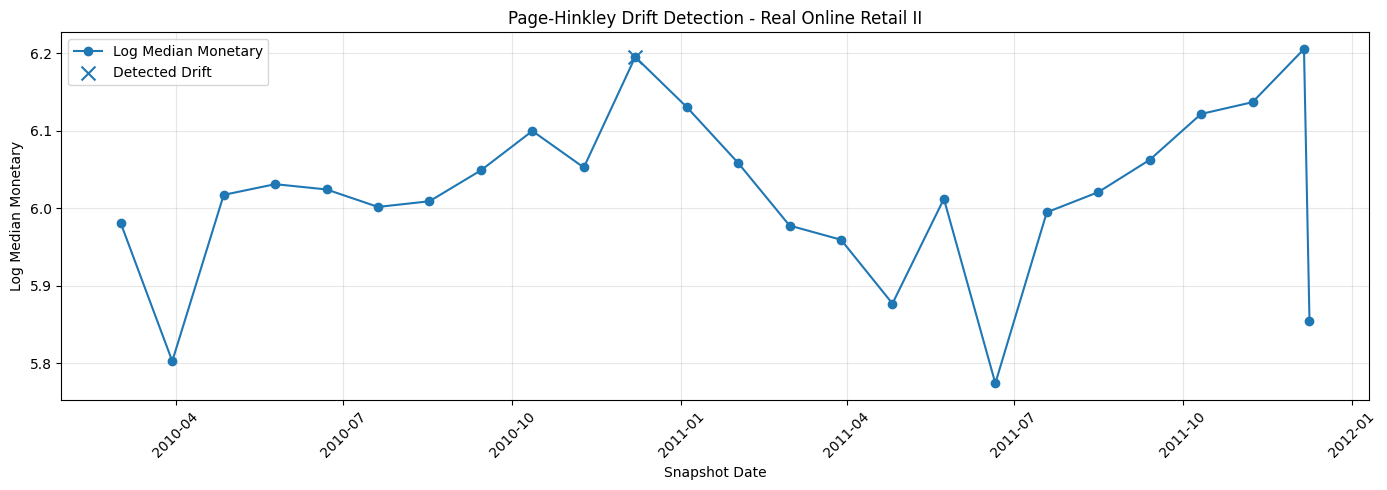


SYNTHETIC DRIFT EXPERIMENT
True drift points: [80, 140]
Raw alarms: [61, 87, 113, 139, 165, 191]
Grouped detected events: [61]


,true_drift_events,detected_events,true_positive,false_positive,false_negative,precision,recall,f1_score,mean_detection_delay,false_alarms_per_100_points
0,2,1,0,1,2,0.0,0.0,0.0,NaN,0.5882



MONTE CARLO DRIFT EVALUATION


,true_drift_events,detected_events,true_positive,false_positive,false_negative,precision,recall,f1_score,mean_detection_delay,false_alarms_per_100_points,trial
0,2,1,0,1,2,0.0,0.0,0.0,NaN,0.5882,1
1,2,2,1,1,1,0.5,0.5,0.5,0.0,0.5882,2
2,2,2,1,1,1,0.5,0.5,0.5,0.0,0.5882,3
3,2,2,1,1,1,0.5,0.5,0.5,0.0,0.5882,4
4,2,2,1,1,1,0.5,0.5,0.5,0.0,0.5882,5
5,2,1,0,1,2,0.0,0.0,0.0,NaN,0.5882,6
6,2,2,1,1,1,0.5,0.5,0.5,0.0,0.5882,7
7,2,1,0,1,2,0.0,0.0,0.0,NaN,0.5882,8
8,2,2,0,2,2,0.0,0.0,0.0,NaN,1.1765,9
9,2,1,0,1,2,0.0,0.0,0.0,NaN,0.5882,10



Mean and Standard Deviation:


,precision,recall,f1_score,mean_detection_delay,false_alarms_per_100_points
mean,0.1667,0.1667,0.1667,0.0,0.7843
std,0.2397,0.2397,0.2397,0.0,0.2820


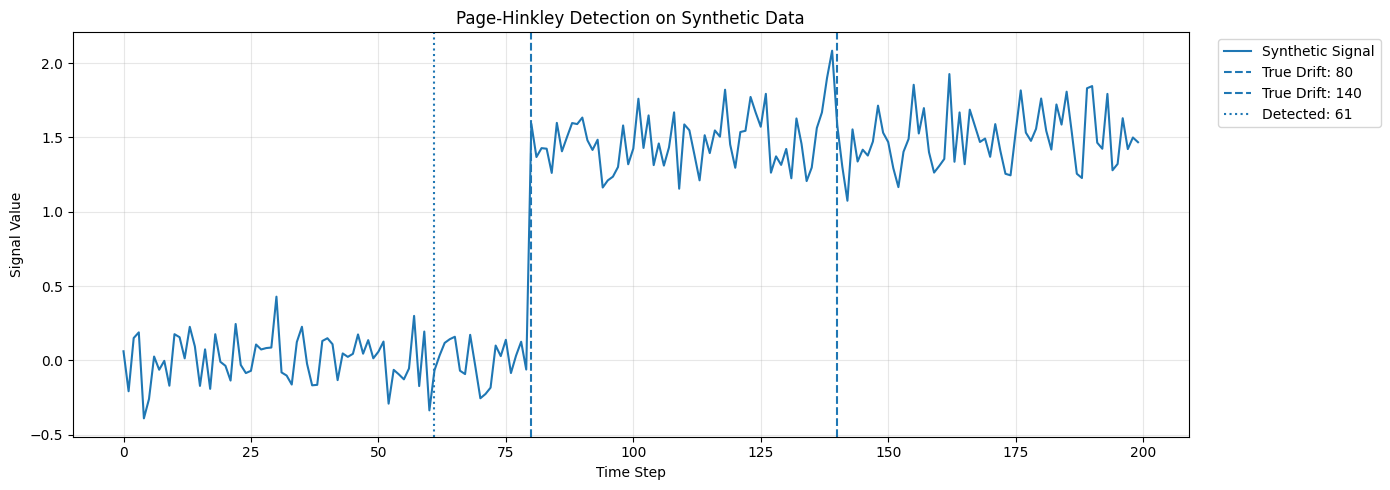


DRIFT DETECTION EXPERIMENT COMPLETED


,real_snapshots,real_raw_alarm_count,real_grouped_drift_events,synthetic_precision,synthetic_recall,synthetic_f1,synthetic_detection_delay,synthetic_false_alarms_per_100_points,monte_carlo_mean_precision,monte_carlo_mean_recall,monte_carlo_mean_f1,monte_carlo_std_f1,monte_carlo_mean_detection_delay,monte_carlo_mean_false_alarms_per_100_points
0,25,1,1,0.0,0.0,0.0,NaN,0.5882,0.1667,0.1667,0.1667,0.2397,0.0,0.7843


In [ ]:

# ============================================================
# CELL 13 - PAGE-HINKLEY DRIFT DETECTION
# Improved Research Implementation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

PH_DELTA = 0.05
PH_THRESHOLD = 5.0

PH_SYNTHETIC_WARMUP = 30
PH_SYNTHETIC_LENGTH = 200
PH_DETECTION_TOLERANCE = 20

PH_RANDOM_SEED = 42

# Engineering extensions:
PH_COOLDOWN = 25
PH_ALARM_GAP = 30

PH_MIN_BASELINE_STD = 1e-8


# ============================================================
# 2. PAGE-HINKLEY DETECTOR
# ============================================================

class PageHinkleyDetector:
    """
    Two-sided Page-Hinkley detector.

    The baseline mean and standard deviation are estimated
    from the initial historical observations and then fixed.

    Upward statistic:
        PH+ = cumulative deviation - historical minimum

    Downward statistic:
        PH- = historical maximum - cumulative deviation

    Reset and cooldown are engineering extensions intended
    to reduce repeated alarms after a detected change.
    """

    def __init__(
        self,
        delta=0.05,
        threshold=5.0,
        direction="both",
        baseline_mean=None,
        baseline_std=None,
        cooldown=25
    ):

        if delta < 0:
            raise ValueError("delta must be non-negative.")

        if threshold <= 0:
            raise ValueError("threshold must be positive.")

        if direction not in ["up", "down", "both"]:
            raise ValueError(
                "direction must be up, down or both."
            )

        self.delta = float(delta)

        self.threshold = float(threshold)

        self.direction = direction

        self.baseline_mean = baseline_mean

        self.baseline_std = baseline_std

        self.cooldown = int(cooldown)

        self.cumulative = 0.0

        self.minimum_cumulative = 0.0

        self.maximum_cumulative = 0.0

        self.cooldown_remaining = 0

        self.total_alarms = 0

    def reset_statistics(self):

        self.cumulative = 0.0

        self.minimum_cumulative = 0.0

        self.maximum_cumulative = 0.0

    def update(self, value):

        if self.baseline_mean is None:
            raise ValueError(
                "Baseline mean has not been initialized."
            )

        value = float(value)

        if not np.isfinite(value):
            raise ValueError(
                "Input value must be finite."
            )

        scale = max(
            float(self.baseline_std),
            PH_MIN_BASELINE_STD
        )

        # Standardized deviation from historical baseline.
        x = (
            value - self.baseline_mean
        ) / scale

        # Cooldown period after an alarm.
        if self.cooldown_remaining > 0:

            self.cooldown_remaining -= 1

            return {

                "alarm": False,

                "direction": None,

                "statistic_up": 0.0,

                "statistic_down": 0.0,

                "cooldown": True

            }

        # Page-Hinkley cumulative deviation.
        self.cumulative += (
            x - self.delta
        )

        self.minimum_cumulative = min(
            self.minimum_cumulative,
            self.cumulative
        )

        self.maximum_cumulative = max(
            self.maximum_cumulative,
            self.cumulative
        )

        statistic_up = (
            self.cumulative
            - self.minimum_cumulative
        )

        statistic_down = (
            self.maximum_cumulative
            - self.cumulative
        )

        upward_alarm = (
            statistic_up > self.threshold
        )

        downward_alarm = (
            statistic_down > self.threshold
        )

        if self.direction == "up":

            alarm = upward_alarm

        elif self.direction == "down":

            alarm = downward_alarm

        else:

            alarm = (
                upward_alarm or downward_alarm
            )

        if upward_alarm and downward_alarm:

            detected_direction = "both"

        elif upward_alarm:

            detected_direction = "up"

        elif downward_alarm:

            detected_direction = "down"

        else:

            detected_direction = None

        if alarm:

            self.total_alarms += 1

            # Reset cumulative statistics after alarm.
            self.reset_statistics()

            # Suppress repeated alarms temporarily.
            self.cooldown_remaining = self.cooldown

        return {

            "alarm": bool(alarm),

            "direction": detected_direction,

            "statistic_up": float(statistic_up),

            "statistic_down": float(statistic_down),

            "cooldown": False

        }


# ============================================================
# 3. RUN PAGE-HINKLEY ON A SERIES
# ============================================================

def run_page_hinkley(
    values,
    dates=None,
    warmup=5,
    delta=PH_DELTA,
    threshold=PH_THRESHOLD,
    direction="both",
    cooldown=PH_COOLDOWN
):

    values = np.asarray(
        values,
        dtype=float
    )

    if values.ndim != 1:
        raise ValueError(
            "Input values must be one-dimensional."
        )

    if len(values) <= warmup:
        raise ValueError(
            "Series length must be greater than warmup."
        )

    if not np.all(np.isfinite(values)):
        raise ValueError(
            "Input contains NaN or infinite values."
        )

    if dates is not None and len(dates) != len(values):
        raise ValueError(
            "Length of dates must equal length of values."
        )

    if warmup < 2:
        raise ValueError(
            "warmup must be at least 2."
        )

    # Historical baseline only.
    baseline = values[:warmup]

    baseline_mean = float(
        np.mean(baseline)
    )

    baseline_std = float(
        np.std(baseline, ddof=1)
    )

    if baseline_std < PH_MIN_BASELINE_STD:

        baseline_std = PH_MIN_BASELINE_STD

    detector = PageHinkleyDetector(

        delta=delta,

        threshold=threshold,

        direction=direction,

        baseline_mean=baseline_mean,

        baseline_std=baseline_std,

        cooldown=cooldown

    )

    records = []

    for i, value in enumerate(values):

        if i < warmup:

            result = {

                "alarm": False,

                "direction": None,

                "statistic_up": 0.0,

                "statistic_down": 0.0,

                "cooldown": False

            }

        else:

            result = detector.update(value)

        records.append({

            "index": i,

            "snapshot_date": (
                dates[i]
                if dates is not None
                else i
            ),

            "value": float(value),

            "alarm": result["alarm"],

            "direction": result["direction"],

            "statistic_up": result["statistic_up"],

            "statistic_down": result["statistic_down"],

            "cooldown": result["cooldown"]

        })

    result_df = pd.DataFrame(records)

    result_df.attrs["baseline_mean"] = baseline_mean

    result_df.attrs["baseline_std"] = baseline_std

    result_df.attrs["warmup"] = warmup

    return result_df


# ============================================================
# 4. GROUP ALARMS INTO DISTINCT EVENTS
# ============================================================

def group_alarm_events(
    alarm_indices,
    max_gap=PH_ALARM_GAP
):
    """
    Group nearby raw alarms into detected drift events.

    The first alarm in each group represents the detection time.
    """

    alarm_indices = sorted(
        set(int(x) for x in alarm_indices)
    )

    if not alarm_indices:
        return []

    groups = []

    current_group = [
        alarm_indices[0]
    ]

    for index in alarm_indices[1:]:

        if index - current_group[-1] <= max_gap:

            current_group.append(index)

        else:

            groups.append(current_group)

            current_group = [index]

    groups.append(current_group)

    return [
        group[0]
        for group in groups
    ]


# ============================================================
# 5. EXTRACT REAL MONETARY SIGNAL
# ============================================================

def extract_monetary_signal(adaptive_history):

    records = []

    for item in adaptive_history:

        rfm = item["rfm"]

        if rfm is None or rfm.empty:
            continue

        if "Monetary" not in rfm.columns:

            raise KeyError(
                "Monetary column is missing from RFM."
            )

        monetary = pd.to_numeric(
            rfm["Monetary"],
            errors="coerce"
        )

        monetary = monetary[
            np.isfinite(monetary)
        ]

        if monetary.empty:
            continue

        median_monetary = float(
            monetary.clip(lower=0).median()
        )

        records.append({

            "snapshot_date": pd.Timestamp(
                item["snapshot_date"]
            ),

            "window": item["window"],

            "customer_count": len(rfm),

            "median_monetary": median_monetary,

            "log_median_monetary": float(
                np.log1p(median_monetary)
            )

        })

    return pd.DataFrame(records)


# ============================================================
# 6. REAL DATA DRIFT MONITORING
# ============================================================

print("=" * 75)
print("REAL DATA DRIFT MONITORING")
print("=" * 75)

real_drift_data = extract_monetary_signal(
    adaptive_history
)

real_drift_result = pd.DataFrame()

real_alarm_events = []

if len(real_drift_data) > 5:

    real_warmup = min(
        5,
        max(3, len(real_drift_data) // 3)
    )

    real_drift_result = run_page_hinkley(

        values=real_drift_data[
            "log_median_monetary"
        ].values,

        dates=real_drift_data[
            "snapshot_date"
        ].tolist(),

        warmup=real_warmup,

        delta=PH_DELTA,

        threshold=PH_THRESHOLD,

        direction="both",

        cooldown=PH_COOLDOWN

    )

    # Merge by snapshot date.
    real_drift_data = real_drift_data.merge(

        real_drift_result[
            [
                "snapshot_date",
                "alarm",
                "direction",
                "statistic_up",
                "statistic_down",
                "cooldown"
            ]
        ],

        on="snapshot_date",

        how="left",

        validate="one_to_one"

    )

    real_drift_data["alarm"] = (
        real_drift_data["alarm"].fillna(False)
    )

    raw_real_alarm_indices = (
        real_drift_result.loc[
            real_drift_result["alarm"],
            "index"
        ].tolist()
    )

    real_alarm_events = group_alarm_events(
        raw_real_alarm_indices
    )

    print(
        "Snapshots monitored:",
        len(real_drift_data)
    )

    print(
        "Raw alarms:",
        len(raw_real_alarm_indices)
    )

    print(
        "Grouped drift events:",
        len(real_alarm_events)
    )

else:

    # Preserve a consistent schema for Cell 16.
    real_drift_data["alarm"] = False

    real_drift_data["direction"] = None

    real_drift_data["statistic_up"] = np.nan

    real_drift_data["statistic_down"] = np.nan

    real_drift_data["cooldown"] = False

    print(
        "Not enough snapshots for meaningful real-data "
        "drift monitoring. At least 6 are required."
    )

display(
    real_drift_data.round(4)
)


# ============================================================
# 7. VISUALIZE REAL DATA
# ============================================================

if not real_drift_data.empty:

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(

        real_drift_data["snapshot_date"],

        real_drift_data["log_median_monetary"],

        marker="o",

        label="Log Median Monetary"

    )

    alarm_data = real_drift_data[
        real_drift_data["alarm"]
    ]

    if not alarm_data.empty:

        ax.scatter(

            alarm_data["snapshot_date"],

            alarm_data["log_median_monetary"],

            marker="x",

            s=100,

            label="Detected Drift"

        )

    ax.set_title(
        "Page-Hinkley Drift Detection - Real Online Retail II"
    )

    ax.set_xlabel("Snapshot Date")

    ax.set_ylabel("Log Median Monetary")

    ax.legend()

    ax.grid(alpha=0.3)

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()


# ============================================================
# 8. GENERATE SYNTHETIC DRIFT DATA
# ============================================================

def generate_synthetic_drift_data(
    length=200,
    warmup=30,
    drift_points=(80, 140),
    noise_std=0.20,
    random_state=42
):
    """
    Generate controlled mean shifts.

    Example:
        0 -> +1.5 at t=80
        +1.5 -> 0 at t=140

    The second change is a downward shift.
    """

    if length <= warmup:
        raise ValueError(
            "length must exceed warmup."
        )

    rng = np.random.default_rng(
        random_state
    )

    values = rng.normal(
        loc=0.0,
        scale=noise_std,
        size=length
    )

    drift_points = tuple(
        sorted(drift_points)
    )

    current_level = 0.0

    true_drift_points = []

    for i, drift_point in enumerate(drift_points):

        if not (warmup <= drift_point < length):

            raise ValueError(
                "Drift points must be within monitoring range."
            )

        if i % 2 == 0:

            current_level += 1.5

        else:

            current_level -= 1.5

        values[drift_point:] += (
            current_level
        )

        true_drift_points.append(
            int(drift_point)
        )

    true_labels = np.zeros(
        length,
        dtype=int
    )

    true_labels[true_drift_points] = 1

    return (
        values,
        true_labels,
        true_drift_points
    )


# ============================================================
# 9. EVENT-LEVEL DRIFT EVALUATION
# ============================================================

def evaluate_drift_events(
    detected_indices,
    true_drift_points,
    tolerance=PH_DETECTION_TOLERANCE,
    series_length=None,
    warmup=0
):
    """
    One-to-one event matching.

    A detection is a true positive when it occurs within
    [true drift point, true drift point + tolerance].

    False alarm rate is also reported as unmatched detections
    per 100 monitored observations.
    """

    detected_indices = sorted(
        set(int(x) for x in detected_indices)
    )

    true_drift_points = sorted(
        set(int(x) for x in true_drift_points)
    )

    matched_detections = set()

    matched_true_events = set()

    delays = []

    for event_index, true_point in enumerate(
        true_drift_points
    ):

        candidates = [

            detection

            for detection in detected_indices

            if (

                true_point <= detection
                <= true_point + tolerance

                and detection not in matched_detections

            )

        ]

        if candidates:

            detection = min(candidates)

            matched_detections.add(
                detection
            )

            matched_true_events.add(
                event_index
            )

            delays.append(
                detection - true_point
            )

    tp = len(matched_true_events)

    fp = (
        len(detected_indices)
        - len(matched_detections)
    )

    fn = (
        len(true_drift_points)
        - len(matched_true_events)
    )

    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    monitored_points = max(
        1,
        (series_length - warmup)
        if series_length is not None
        else 1
    )

    false_alarm_rate = (
        fp / monitored_points
    )

    return {

        "true_drift_events": len(true_drift_points),

        "detected_events": len(detected_indices),

        "true_positive": tp,

        "false_positive": fp,

        "false_negative": fn,

        "precision": precision,

        "recall": recall,

        "f1_score": f1,

        "mean_detection_delay": (
            float(np.mean(delays))
            if delays else np.nan
        ),

        "false_alarms_per_100_points": (
            false_alarm_rate * 100
        )

    }


# ============================================================
# 10. SINGLE SYNTHETIC EXPERIMENT
# ============================================================

synthetic_values, synthetic_labels, true_drift_points = (
    generate_synthetic_drift_data(

        length=PH_SYNTHETIC_LENGTH,

        warmup=PH_SYNTHETIC_WARMUP,

        random_state=PH_RANDOM_SEED

    )
)

synthetic_result = run_page_hinkley(

    values=synthetic_values,

    warmup=PH_SYNTHETIC_WARMUP,

    delta=PH_DELTA,

    threshold=PH_THRESHOLD,

    direction="both",

    cooldown=PH_COOLDOWN

)

raw_detected_indices = synthetic_result.loc[
    synthetic_result["alarm"],
    "index"
].tolist()

detected_indices = group_alarm_events(
    raw_detected_indices,
    max_gap=PH_ALARM_GAP
)

synthetic_metrics = evaluate_drift_events(

    detected_indices=detected_indices,

    true_drift_points=true_drift_points,

    tolerance=PH_DETECTION_TOLERANCE,

    series_length=PH_SYNTHETIC_LENGTH,

    warmup=PH_SYNTHETIC_WARMUP

)

print("\n" + "=" * 75)
print("SYNTHETIC DRIFT EXPERIMENT")
print("=" * 75)

print(
    "True drift points:",
    true_drift_points
)

print(
    "Raw alarms:",
    raw_detected_indices
)

print(
    "Grouped detected events:",
    detected_indices
)

display(
    pd.DataFrame([
        synthetic_metrics
    ]).round(4)
)


# ============================================================
# 11. MONTE CARLO EXPERIMENT
# ============================================================

def run_drift_monte_carlo(
    n_trials=30,
    length=200,
    warmup=30,
    delta=PH_DELTA,
    threshold=PH_THRESHOLD,
    tolerance=PH_DETECTION_TOLERANCE
):

    trial_results = []

    for trial in range(n_trials):

        values, labels, true_points = (
            generate_synthetic_drift_data(

                length=length,

                warmup=warmup,

                random_state=PH_RANDOM_SEED + trial

            )
        )

        detector_result = run_page_hinkley(

            values=values,

            warmup=warmup,

            delta=delta,

            threshold=threshold,

            direction="both",

            cooldown=PH_COOLDOWN

        )

        raw_detections = detector_result.loc[
            detector_result["alarm"],
            "index"
        ].tolist()

        detections = group_alarm_events(
            raw_detections,
            max_gap=PH_ALARM_GAP
        )

        metrics = evaluate_drift_events(

            detected_indices=detections,

            true_drift_points=true_points,

            tolerance=tolerance,

            series_length=length,

            warmup=warmup

        )

        metrics["trial"] = trial + 1

        trial_results.append(
            metrics
        )

    return pd.DataFrame(
        trial_results
    )


monte_carlo_results = run_drift_monte_carlo(
    n_trials=30
)

print("\n" + "=" * 75)
print("MONTE CARLO DRIFT EVALUATION")
print("=" * 75)

display(
    monte_carlo_results.round(4)
)

monte_carlo_summary = (

    monte_carlo_results[

        [

            "precision",

            "recall",

            "f1_score",

            "mean_detection_delay",

            "false_alarms_per_100_points"

        ]

    ]

    .agg(["mean", "std"])

)

print("\nMean and Standard Deviation:")

display(
    monte_carlo_summary.round(4)
)


# ============================================================
# 12. VISUALIZE SYNTHETIC DRIFT
# ============================================================

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(

    synthetic_result["index"],

    synthetic_result["value"],

    label="Synthetic Signal"

)

for point in true_drift_points:

    ax.axvline(

        x=point,

        linestyle="--",

        label=f"True Drift: {point}"

    )

for detection in detected_indices:

    ax.axvline(

        x=detection,

        linestyle=":",

        label=f"Detected: {detection}"

    )

ax.set_title(
    "Page-Hinkley Detection on Synthetic Data"
)

ax.set_xlabel("Time Step")

ax.set_ylabel("Signal Value")

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 13. EXPORTABLE DRIFT SUMMARY
# ============================================================

drift_experiment_summary = {

    "real_snapshots": len(real_drift_data),

    "real_raw_alarm_count": (
        int(real_drift_data["alarm"].sum())
        if "alarm" in real_drift_data.columns
        else 0
    ),

    "real_grouped_drift_events": len(
        real_alarm_events
    ),

    "synthetic_precision": (
        synthetic_metrics["precision"]
    ),

    "synthetic_recall": (
        synthetic_metrics["recall"]
    ),

    "synthetic_f1": (
        synthetic_metrics["f1_score"]
    ),

    "synthetic_detection_delay": (
        synthetic_metrics["mean_detection_delay"]
    ),

    "synthetic_false_alarms_per_100_points": (
        synthetic_metrics["false_alarms_per_100_points"]
    ),

    "monte_carlo_mean_precision": (
        monte_carlo_results["precision"].mean()
    ),

    "monte_carlo_mean_recall": (
        monte_carlo_results["recall"].mean()
    ),

    "monte_carlo_mean_f1": (
        monte_carlo_results["f1_score"].mean()
    ),

    "monte_carlo_std_f1": (
        monte_carlo_results["f1_score"].std()
    ),

    "monte_carlo_mean_detection_delay": (
        monte_carlo_results["mean_detection_delay"].mean()
    ),

    "monte_carlo_mean_false_alarms_per_100_points": (
        monte_carlo_results[
            "false_alarms_per_100_points"
        ].mean()
    )

}

print("\n" + "=" * 75)
print("DRIFT DETECTION EXPERIMENT COMPLETED")
print("=" * 75)

display(
    pd.DataFrame([
        drift_experiment_summary
    ]).round(4)
)


Cell 14 — Baseline: Static RFM và Fixed Rolling RFM

BASELINE TRANSACTION DATA
Rows: 779,425
Customers: 5,878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00

RUNNING BASELINE BENCHMARK

Snapshot 1/25: 2010-03-02
  Lifetime RFM: customers=1,744, Silhouette=0.3883, DBI=0.9333
  Rolling 28 Days: customers=783, Silhouette=0.3355, DBI=1.0679
  Rolling 56 Days: customers=1,262, Silhouette=0.3455, DBI=0.9945
  Rolling 91 Days: customers=1,719, Silhouette=0.3892, DBI=0.9325
  Common cohort: 783 customers
  Common-cohort methods evaluated: 5

Snapshot 2/25: 2010-03-30
  Lifetime RFM: customers=2,135, Silhouette=0.3487, DBI=0.9640
  Rolling 28 Days: customers=958, Silhouette=0.3857, DBI=0.8965
  Rolling 56 Days: customers=1,457, Silhouette=0.3329, DBI=1.0058
  Rolling 91 Days: customers=1,781, Silhouette=0.3531, DBI=0.9750
  Common cohort: 958 customers
  Common-cohort methods evaluated: 5

Snapshot 3/25: 2010-04-27
  Lifetime RFM: customers=2,402, Silhouette=0.3446, DBI=0.9649
  Rolling 28 Days: customers=858, Silhouette=0.3328, DBI=1.077

,method,snapshot_date,window_days,n_customers,n_clusters,silhouette,davies_bouldin,calinski_harabasz,inertia,minimum_cluster_size,minimum_cluster_fraction
0,Lifetime RFM,2010-03-02,Lifetime,1744,4,0.3883,0.9333,1462.4276,1485.7613,173,0.0992
1,Rolling 28 Days,2010-03-02,28,783,4,0.3355,1.0679,452.2576,856.7723,62,0.0792
2,Rolling 56 Days,2010-03-02,56,1262,4,0.3455,0.9945,800.3314,1301.6763,74,0.0586
3,Rolling 91 Days,2010-03-02,91,1719,4,0.3892,0.9325,1440.9764,1464.7828,168,0.0977
4,Lifetime RFM,2010-03-30,Lifetime,2135,4,0.3487,0.9640,1738.2364,1858.1142,243,0.1138
...,...,...,...,...,...,...,...,...,...,...,...
95,Rolling 91 Days,2011-12-06,91,2889,4,0.3539,0.9351,2431.9993,2455.9768,383,0.1326
96,Lifetime RFM,2011-12-09,Lifetime,5878,4,0.3636,0.9044,6131.4274,4268.2798,1054,0.1793
97,Rolling 28 Days,2011-12-09,28,1527,4,0.3762,0.9438,1092.0549,1453.7661,105,0.0688
98,Rolling 56 Days,2011-12-09,56,2277,4,0.3467,0.9612,1793.3168,2028.8728,266,0.1168



BASELINE SUMMARY


,method,snapshots,mean_customers,mean_silhouette,std_silhouette,mean_davies_bouldin,mean_calinski_harabasz,mean_inertia,mean_minimum_cluster_fraction
0,Lifetime RFM,25,4199.56,0.3532,0.0150,0.9317,4038.7863,3249.1123,0.1571
1,Rolling 28 Days,25,1018.52,0.3372,0.0214,0.9838,599.5579,1104.5215,0.1461
2,Rolling 56 Days,25,1632.96,0.3422,0.0195,1.0067,1100.4897,1623.4202,0.0912
3,Rolling 91 Days,25,2154.16,0.3495,0.0164,0.9728,1654.3486,1957.3180,0.1069



COMMON-COHORT BENCHMARK


,snapshot_date,method,n_common_customers,n_clusters,silhouette,davies_bouldin,calinski_harabasz,inertia,minimum_cluster_size,minimum_cluster_fraction
0,2010-03-02,Lifetime RFM,783,4,0.3357,0.9716,507.1896,795.3994,125,0.1596
1,2010-03-02,Rolling 28 Days,783,4,0.3355,1.0679,452.2576,856.7723,62,0.0792
2,2010-03-02,Rolling 56 Days,783,4,0.3281,1.0178,474.7073,830.5809,53,0.0677
3,2010-03-02,Rolling 91 Days,783,4,0.3356,0.9769,507.7744,794.7932,132,0.1686
4,2010-03-02,Adaptive Rolling Dynamic RFM,783,3,0.3409,1.0022,535.6721,989.6701,201,0.2567
...,...,...,...,...,...,...,...,...,...,...
120,2011-12-09,Lifetime RFM,1527,4,0.3583,0.8860,1172.1777,1384.4555,344,0.2253
121,2011-12-09,Rolling 28 Days,1527,4,0.3762,0.9438,1092.0549,1453.7661,105,0.0688
122,2011-12-09,Rolling 56 Days,1527,4,0.3276,1.0067,1085.0821,1460.1305,226,0.1480
123,2011-12-09,Rolling 91 Days,1527,4,0.3367,0.9232,1064.1237,1479.6075,345,0.2259


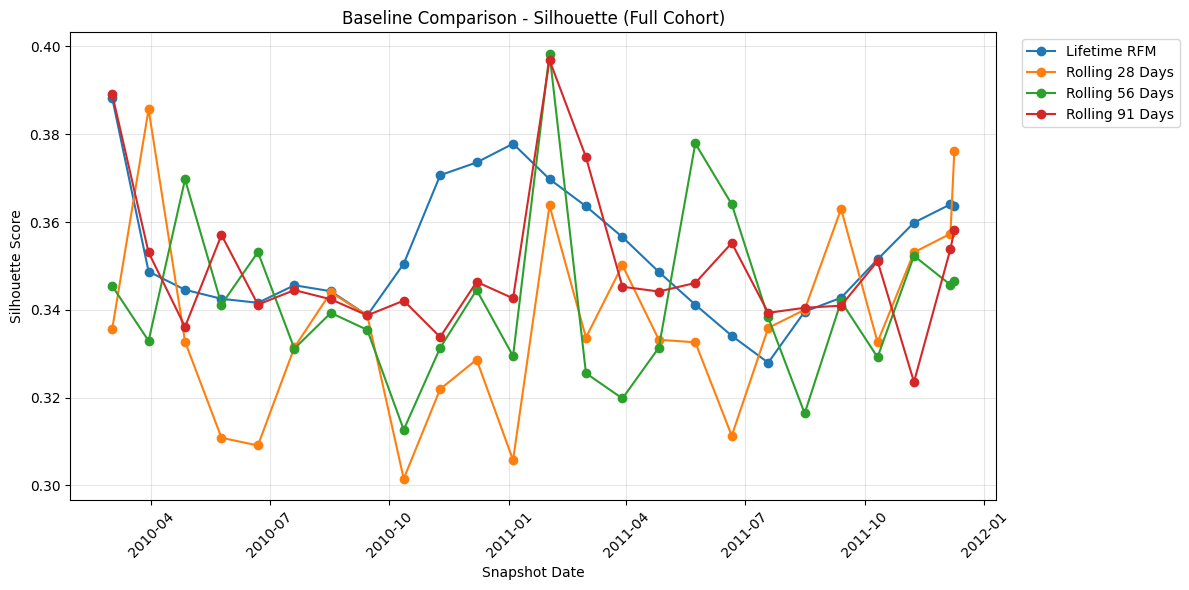

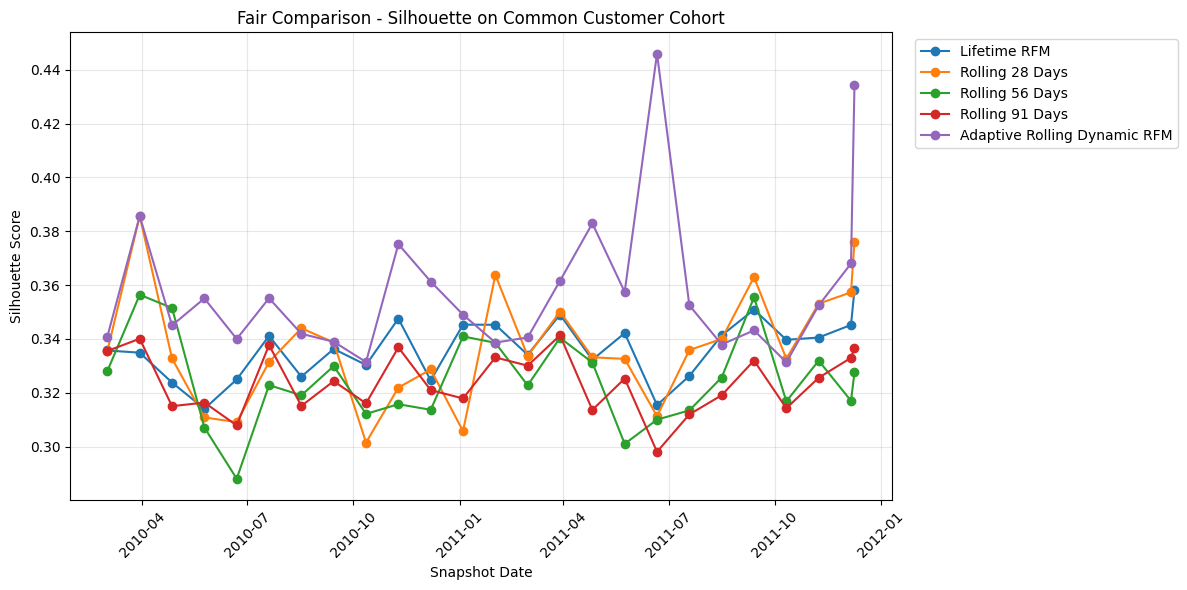


CELL 14 - BASELINE BENCHMARK COMPLETED
Full-cohort baseline runs: 100
Baseline methods: 4
Snapshots: 25
Common-cohort evaluation rows: 125

Available outputs:
- baseline_history
- baseline_results
- baseline_summary
- baseline_rfm_data
- common_cohort_results
- adaptive_common_cohort_results
- common_cohort_profiles_df


In [ ]:

# ============================================================
# CELL 14 - BASELINE BENCHMARK
# Improved Fair Comparison Implementation
#
# Experiments:
# 1. Lifetime RFM + Fixed K-Means
# 2. Rolling 28 Days + Fixed K-Means
# 3. Rolling 56 Days + Fixed K-Means
# 4. Rolling 91 Days + Fixed K-Means
#
# Additional:
# 5. Common-cohort evaluation across all methods
# 6. Adaptive model evaluation on the same common cohort
#
# Outputs:
# - baseline_history
# - baseline_results
# - baseline_summary
# - baseline_rfm_data
# - common_cohort_results
# - adaptive_common_cohort_results
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)


# ============================================================
# 0. CONFIGURATION
# ============================================================

BASELINE_FIXED_K = 4

BASELINE_WINDOWS = [28, 56, 91]

BASELINE_RANDOM_STATE = 42

BASELINE_N_INIT = 10

BASELINE_SILHOUETTE_SAMPLE = 10000

BASELINE_MIN_CUSTOMERS = 10

BASELINE_MIN_COMMON_COHORT = 10

BASELINE_MIN_CLUSTER_SIZE = 2


# ============================================================
# 1. VALIDATE INPUTS
# ============================================================

if "df" not in globals():
    raise NameError(
        "DataFrame 'df' not found. Run preprocessing first."
    )

if "snapshot_dates" not in globals():
    raise NameError(
        "'snapshot_dates' not found. Run Cell 5 first."
    )

if "adaptive_history" not in globals():
    raise NameError(
        "'adaptive_history' not found. Run Cell 10 first."
    )

if len(snapshot_dates) == 0:
    raise ValueError("snapshot_dates is empty.")

if not isinstance(df, pd.DataFrame) or df.empty:
    raise ValueError("df is empty or is not a DataFrame.")

required_columns = [
    "CustomerID",
    "Invoice",
    "InvoiceDate",
    "Quantity",
    "Price",
    "Amount"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in df: {missing_columns}"
    )


# ============================================================
# 2. PREPARE BASELINE TRANSACTIONS
# ============================================================

baseline_transactions = df[
    required_columns
].copy()

baseline_transactions["InvoiceDate"] = pd.to_datetime(
    baseline_transactions["InvoiceDate"],
    errors="coerce"
)

baseline_transactions["Quantity"] = pd.to_numeric(
    baseline_transactions["Quantity"],
    errors="coerce"
)

baseline_transactions["Price"] = pd.to_numeric(
    baseline_transactions["Price"],
    errors="coerce"
)

baseline_transactions["Amount"] = pd.to_numeric(
    baseline_transactions["Amount"],
    errors="coerce"
)

baseline_transactions["Invoice"] = (
    baseline_transactions["Invoice"].astype(str).str.strip()
)

baseline_transactions = baseline_transactions.dropna(
    subset=required_columns
)

# Use the same preprocessing policy as the main pipeline.
baseline_transactions = baseline_transactions[
    (baseline_transactions["Quantity"] > 0)
    & (baseline_transactions["Price"] > 0)
    & (baseline_transactions["Amount"] > 0)
    & (
        ~baseline_transactions["Invoice"]
        .str.upper()
        .str.startswith("C")
    )
].copy()

baseline_transactions = baseline_transactions.sort_values(
    "InvoiceDate"
).reset_index(drop=True)

# Keep the same monetary definition as Cell 6.
baseline_transactions["MonetaryValue"] = (
    baseline_transactions["Amount"]
)

if baseline_transactions.empty:
    raise ValueError(
        "No valid transactions remain for baseline experiments."
    )

print("=" * 75)
print("BASELINE TRANSACTION DATA")
print("=" * 75)

print(
    "Rows:",
    f"{len(baseline_transactions):,}"
)

print(
    "Customers:",
    f"{baseline_transactions['CustomerID'].nunique():,}"
)

print(
    "Date range:",
    baseline_transactions["InvoiceDate"].min(),
    "to",
    baseline_transactions["InvoiceDate"].max()
)


# ============================================================
# 3. CALCULATE RFM
# ============================================================

def baseline_calculate_rfm(
    transactions,
    snapshot_date,
    window_days=None
):
    """
    Calculate RFM using the same end-of-day anchor as Cell 6.

    Snapshot convention:
        snapshot_end = snapshot date normalized + 1 day

    Inclusion:
        InvoiceDate < snapshot_end

    Rolling window:
        InvoiceDate >= snapshot_end - window_days

    Recency:
        snapshot_end - LastPurchase

    Frequency:
        Number of unique invoices.

    Monetary:
        Sum of positive purchase amounts.
    """

    snapshot_end = (
        pd.Timestamp(snapshot_date).normalize()
        + pd.Timedelta(days=1)
    )

    # No future transactions.
    data = transactions[
        transactions["InvoiceDate"] < snapshot_end
    ].copy()

    if window_days is not None:

        if int(window_days) <= 0:
            raise ValueError(
                "window_days must be positive."
            )

        start_date = (
            snapshot_end
            - pd.Timedelta(days=int(window_days))
        )

        data = data[
            data["InvoiceDate"] >= start_date
        ]

    if data.empty:

        return pd.DataFrame(
            columns=[
                "Recency",
                "Frequency",
                "Monetary"
            ]
        ).rename_axis("CustomerID")

    rfm = data.groupby(
        "CustomerID"
    ).agg(

        LastPurchase=("InvoiceDate", "max"),

        Frequency=("Invoice", "nunique"),

        Monetary=("MonetaryValue", "sum")

    )

    rfm["Recency"] = (
        snapshot_end - rfm["LastPurchase"]
    ).dt.total_seconds() / 86400.0

    rfm = rfm[
        [
            "Recency",
            "Frequency",
            "Monetary"
        ]
    ]

    rfm = rfm.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    rfm = rfm[
        (rfm["Recency"] >= 0)
        & (rfm["Frequency"] > 0)
        & (rfm["Monetary"] > 0)
    ]

    return rfm


# ============================================================
# 4. TRANSFORM AND SCALE RFM
# ============================================================

def baseline_transform_rfm(rfm):
    """
    Use the same feature transformation policy as Cell 7.

    Frequency and Monetary:
        log1p transformation

    Outliers:
        1st and 99th percentile clipping

    Scaling:
        StandardScaler

    Scaler is fitted only on the current snapshot/cohort.
    """

    required = [
        "Recency",
        "Frequency",
        "Monetary"
    ]

    if not set(required).issubset(rfm.columns):
        raise ValueError(
            "RFM must contain Recency, Frequency and Monetary."
        )

    if rfm.empty:
        raise ValueError(
            "Cannot transform an empty RFM dataset."
        )

    transformed = rfm[required].copy()

    transformed["Recency"] = (
        transformed["Recency"].clip(lower=0)
    )

    transformed["Frequency"] = np.log1p(
        transformed["Frequency"].clip(lower=0)
    )

    transformed["Monetary"] = np.log1p(
        transformed["Monetary"].clip(lower=0)
    )

    for col in required:

        lower = transformed[col].quantile(0.01)

        upper = transformed[col].quantile(0.99)

        transformed[col] = transformed[col].clip(
            lower,
            upper
        )

    scaler = StandardScaler()

    X = scaler.fit_transform(
        transformed
    )

    return X, scaler


# ============================================================
# 5. EVALUATE CLUSTERING
# ============================================================

def baseline_evaluate_clustering(
    X,
    labels
):
    """
    Calculate internal clustering metrics.
    """

    X = np.asarray(X)

    labels = np.asarray(labels)

    if len(X) != len(labels):
        raise ValueError(
            "X and labels must have equal lengths."
        )

    if len(X) < 3:

        return {
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan
        }

    unique_labels = np.unique(labels)

    n_clusters = len(unique_labels)

    if (
        n_clusters < 2
        or n_clusters >= len(X)
    ):

        return {
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan
        }

    sample_size = min(
        BASELINE_SILHOUETTE_SAMPLE,
        len(X)
    )

    try:

        silhouette = silhouette_score(

            X,

            labels,

            sample_size=sample_size,

            random_state=BASELINE_RANDOM_STATE

        )

    except Exception as error:

        print(
            "Silhouette calculation warning:",
            str(error)
        )

        silhouette = np.nan

    try:

        dbi = davies_bouldin_score(
            X,
            labels
        )

    except Exception:

        dbi = np.nan

    try:

        chi = calinski_harabasz_score(
            X,
            labels
        )

    except Exception:

        chi = np.nan

    return {

        "silhouette": float(silhouette),

        "davies_bouldin": float(dbi),

        "calinski_harabasz": float(chi)

    }


# ============================================================
# 6. RUN ONE FIXED-K BASELINE
# ============================================================

def baseline_run_fixed_k(
    transactions,
    snapshot_date,
    window_days=None,
    fixed_k=BASELINE_FIXED_K,
    method_name="Baseline"
):
    """
    Run a fixed-K baseline on its complete available cohort.
    """

    rfm = baseline_calculate_rfm(
        transactions=transactions,
        snapshot_date=snapshot_date,
        window_days=window_days
    )

    if len(rfm) < max(
        BASELINE_MIN_CUSTOMERS,
        fixed_k + 1
    ):

        return None

    X, scaler = baseline_transform_rfm(
        rfm
    )

    model = KMeans(

        n_clusters=fixed_k,

        random_state=BASELINE_RANDOM_STATE,

        n_init=BASELINE_N_INIT

    )

    labels = model.fit_predict(X)

    cluster_sizes = np.bincount(
        labels
    )

    metrics = baseline_evaluate_clustering(
        X,
        labels
    )

    result = {

        "method": method_name,

        "snapshot_date": pd.Timestamp(
            snapshot_date
        ),

        "window_days": (
            "Lifetime"
            if window_days is None
            else int(window_days)
        ),

        "n_customers": len(rfm),

        "n_clusters": len(
            np.unique(labels)
        ),

        "silhouette": metrics["silhouette"],

        "davies_bouldin": metrics["davies_bouldin"],

        "calinski_harabasz": metrics["calinski_harabasz"],

        "inertia": float(model.inertia_),

        "minimum_cluster_size": int(
            cluster_sizes.min()
        ),

        "minimum_cluster_fraction": float(
            cluster_sizes.min() / len(rfm)
        ),

        "rfm": rfm.copy(),

        "X": X,

        "labels": labels,

        "model": model,

        "scaler": scaler

    }

    return result


# ============================================================
# 7. COMMON-COHORT BENCHMARK
# ============================================================

def evaluate_common_cohort(
    snapshot_date,
    method_rfms,
    method_k_values
):
    """
    Refit every method on the same customer cohort.

    The common cohort is the intersection of customer IDs
    available in every method, including the adaptive model.

    Each method retains its own K:
        - Baseline methods use BASELINE_FIXED_K.
        - Adaptive method uses the K selected by Cell 8/10.

    This evaluates the methods on the same customers while
    allowing each method to retain its own feature representation.
    """

    method_names = list(method_rfms.keys())

    if len(method_names) < 2:
        return pd.DataFrame(), pd.DataFrame()

    common_customers = None

    for method_name in method_names:

        current_ids = set(
            method_rfms[method_name].index
        )

        if common_customers is None:

            common_customers = current_ids

        else:

            common_customers.intersection_update(
                current_ids
            )

    common_customers = sorted(
        common_customers
    )

    if len(common_customers) < BASELINE_MIN_COMMON_COHORT:

        print(
            f"WARNING: Common cohort too small on "
            f"{pd.Timestamp(snapshot_date).date()}: "
            f"{len(common_customers)} customers."
        )

        return (
            pd.DataFrame(),
            pd.DataFrame()
        )

    metric_records = []

    profile_records = []

    for method_name in method_names:

        rfm = method_rfms[method_name].loc[
            common_customers
        ].copy()

        k = int(
            method_k_values[method_name]
        )

        if len(rfm) <= k:

            print(
                f"Skipping {method_name}: "
                "common cohort is smaller than K."
            )

            continue

        X, scaler = baseline_transform_rfm(
            rfm
        )

        model = KMeans(

            n_clusters=k,

            random_state=BASELINE_RANDOM_STATE,

            n_init=BASELINE_N_INIT

        )

        labels = model.fit_predict(X)

        metrics = baseline_evaluate_clustering(
            X,
            labels
        )

        sizes = np.bincount(
            labels,
            minlength=k
        )

        metric_records.append({

            "snapshot_date": pd.Timestamp(snapshot_date),

            "method": method_name,

            "n_common_customers": len(common_customers),

            "n_clusters": len(np.unique(labels)),

            "silhouette": metrics["silhouette"],

            "davies_bouldin": metrics["davies_bouldin"],

            "calinski_harabasz": metrics["calinski_harabasz"],

            "inertia": float(model.inertia_),

            "minimum_cluster_size": int(sizes.min()),

            "minimum_cluster_fraction": float(
                sizes.min() / len(rfm)
            )

        })

        profile = rfm.copy()

        profile["Cluster"] = labels

        profile["CustomerID"] = profile.index

        profile["method"] = method_name

        profile["snapshot_date"] = pd.Timestamp(
            snapshot_date
        )

        profile_records.append(
            profile.reset_index(drop=True)
        )

    metrics_df = pd.DataFrame(
        metric_records
    )

    profile_df = (

        pd.concat(
            profile_records,
            ignore_index=True
        )

        if profile_records

        else pd.DataFrame()

    )

    return metrics_df, profile_df


# ============================================================
# 8. RUN BASELINE EXPERIMENTS
# ============================================================

baseline_methods = [

    {
        "name": "Lifetime RFM",
        "window_days": None
    },

    {
        "name": "Rolling 28 Days",
        "window_days": 28
    },

    {
        "name": "Rolling 56 Days",
        "window_days": 56
    },

    {
        "name": "Rolling 91 Days",
        "window_days": 91
    }

]

baseline_history = []

common_cohort_records = []

common_cohort_profiles = []

adaptive_common_records = []

print("\n" + "=" * 75)
print("RUNNING BASELINE BENCHMARK")
print("=" * 75)

for snapshot_index, snapshot_date in enumerate(
    snapshot_dates
):

    snapshot_date = pd.Timestamp(
        snapshot_date
    )

    print(
        f"\nSnapshot {snapshot_index + 1}/{len(snapshot_dates)}:",
        snapshot_date.date()
    )

    # --------------------------------------------------------
    # Run full-cohort baseline methods
    # --------------------------------------------------------

    snapshot_method_rfms = {}

    snapshot_method_k = {}

    for method in baseline_methods:

        result = baseline_run_fixed_k(

            transactions=baseline_transactions,

            snapshot_date=snapshot_date,

            window_days=method["window_days"],

            fixed_k=BASELINE_FIXED_K,

            method_name=method["name"]

        )

        if result is None:

            print(
                f"  Skipped {method['name']}: "
                "insufficient customers."
            )

            continue

        baseline_history.append(
            result
        )

        snapshot_method_rfms[
            method["name"]
        ] = result["rfm"]

        snapshot_method_k[
            method["name"]
        ] = BASELINE_FIXED_K

        print(

            f"  {method['name']}: "

            f"customers={result['n_customers']:,}, "

            f"Silhouette={result['silhouette']:.4f}, "

            f"DBI={result['davies_bouldin']:.4f}"

        )

    # --------------------------------------------------------
    # Add adaptive model to common-cohort comparison
    # --------------------------------------------------------

    matching_adaptive = [

        item for item in adaptive_history

        if pd.Timestamp(
            item["snapshot_date"]
        ).normalize() == snapshot_date.normalize()

    ]

    if matching_adaptive:

        adaptive_record = matching_adaptive[0]

        adaptive_rfm = adaptive_record["rfm"]

        adaptive_k = int(
            adaptive_record["k"]
        )

        snapshot_method_rfms[
            "Adaptive Rolling Dynamic RFM"
        ] = adaptive_rfm

        snapshot_method_k[
            "Adaptive Rolling Dynamic RFM"
        ] = adaptive_k

    # --------------------------------------------------------
    # Evaluate all methods on the same cohort
    # --------------------------------------------------------

    if len(snapshot_method_rfms) >= 2:

        common_metrics, common_profiles = (
            evaluate_common_cohort(

                snapshot_date=snapshot_date,

                method_rfms=snapshot_method_rfms,

                method_k_values=snapshot_method_k

            )
        )

        if not common_metrics.empty:

            common_cohort_records.append(
                common_metrics
            )

            if not common_profiles.empty:

                common_cohort_profiles.append(
                    common_profiles
                )

            print(
                "  Common cohort:",
                f"{common_metrics['n_common_customers'].iloc[0]:,}",
                "customers"
            )

            print(
                "  Common-cohort methods evaluated:",
                len(common_metrics)
            )

        else:

            print(
                "  Common-cohort evaluation unavailable."
            )


# ============================================================
# 9. CREATE BASELINE RESULTS
# ============================================================

baseline_results = pd.DataFrame([

    {

        "method": item["method"],

        "snapshot_date": item["snapshot_date"],

        "window_days": item["window_days"],

        "n_customers": item["n_customers"],

        "n_clusters": item["n_clusters"],

        "silhouette": item["silhouette"],

        "davies_bouldin": item["davies_bouldin"],

        "calinski_harabasz": item["calinski_harabasz"],

        "inertia": item["inertia"],

        "minimum_cluster_size": item["minimum_cluster_size"],

        "minimum_cluster_fraction": item[
            "minimum_cluster_fraction"
        ]

    }

    for item in baseline_history

])

if baseline_results.empty:

    raise RuntimeError(
        "No baseline experiment produced a valid result."
    )

print("\n" + "=" * 75)
print("BASELINE RESULTS - FULL COHORT")
print("=" * 75)

display(
    baseline_results.round(4)
)


# ============================================================
# 10. AGGREGATE BASELINE RESULTS
# ============================================================

baseline_summary = (

    baseline_results

    .groupby("method")

    .agg(

        snapshots=("snapshot_date", "count"),

        mean_customers=("n_customers", "mean"),

        mean_silhouette=("silhouette", "mean"),

        std_silhouette=("silhouette", "std"),

        mean_davies_bouldin=("davies_bouldin", "mean"),

        mean_calinski_harabasz=("calinski_harabasz", "mean"),

        mean_inertia=("inertia", "mean"),

        mean_minimum_cluster_fraction=(
            "minimum_cluster_fraction",
            "mean"
        )

    )

    .reset_index()

)

print("\n" + "=" * 75)
print("BASELINE SUMMARY")
print("=" * 75)

display(
    baseline_summary.round(4)
)


# ============================================================
# 11. COMMON-COHORT RESULTS
# ============================================================

common_cohort_results = (

    pd.concat(
        common_cohort_records,
        ignore_index=True
    )

    if common_cohort_records

    else pd.DataFrame()

)

adaptive_common_cohort_results = (

    common_cohort_results[
        common_cohort_results["method"]
        == "Adaptive Rolling Dynamic RFM"
    ].copy()

    if not common_cohort_results.empty

    else pd.DataFrame()

)

common_cohort_profiles_df = (

    pd.concat(
        common_cohort_profiles,
        ignore_index=True
    )

    if common_cohort_profiles

    else pd.DataFrame()

)

print("\n" + "=" * 75)
print("COMMON-COHORT BENCHMARK")
print("=" * 75)

if not common_cohort_results.empty:

    display(
        common_cohort_results.round(4)
    )

else:

    print(
        "No valid common-cohort comparisons were produced."
    )

    print(
        "This can happen when the intersection of customers "
        "across all windows is too small."
    )


# ============================================================
# 12. BUILD BASELINE RFM DATA EXPORT
# ============================================================

baseline_rfm_records = []

for item in baseline_history:

    temp = item["rfm"].copy()

    temp["CustomerID"] = temp.index

    temp["snapshot_date"] = item["snapshot_date"]

    temp["method"] = item["method"]

    temp["window_days"] = item["window_days"]

    temp["Cluster"] = item["labels"]

    baseline_rfm_records.append(
        temp.reset_index(drop=True)
    )

baseline_rfm_data = (

    pd.concat(
        baseline_rfm_records,
        ignore_index=True
    )

    if baseline_rfm_records

    else pd.DataFrame()

)


# ============================================================
# 13. VISUALIZE FULL-COHORT BASELINE
# ============================================================

plt.figure(figsize=(12, 6))

for method_name in baseline_results["method"].unique():

    method_data = baseline_results[
        baseline_results["method"] == method_name
    ].sort_values("snapshot_date")

    plt.plot(

        method_data["snapshot_date"],

        method_data["silhouette"],

        marker="o",

        label=method_name

    )

plt.title(
    "Baseline Comparison - Silhouette (Full Cohort)"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Silhouette Score")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ============================================================
# 14. VISUALIZE COMMON-COHORT BASELINE
# ============================================================

if not common_cohort_results.empty:

    plt.figure(figsize=(12, 6))

    for method_name in common_cohort_results[
        "method"
    ].unique():

        method_data = common_cohort_results[
            common_cohort_results["method"]
            == method_name
        ].sort_values("snapshot_date")

        plt.plot(

            method_data["snapshot_date"],

            method_data["silhouette"],

            marker="o",

            label=method_name

        )

    plt.title(
        "Fair Comparison - Silhouette on Common Customer Cohort"
    )

    plt.xlabel("Snapshot Date")

    plt.ylabel("Silhouette Score")

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.grid(alpha=0.3)

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()


# ============================================================
# 15. COMPLETION SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("CELL 14 - BASELINE BENCHMARK COMPLETED")
print("=" * 75)

print(
    "Full-cohort baseline runs:",
    len(baseline_history)
)

print(
    "Baseline methods:",
    baseline_results["method"].nunique()
)

print(
    "Snapshots:",
    baseline_results["snapshot_date"].nunique()
)

print(
    "Common-cohort evaluation rows:",
    len(common_cohort_results)
)

print("\nAvailable outputs:")

print("- baseline_history")
print("- baseline_results")
print("- baseline_summary")
print("- baseline_rfm_data")
print("- common_cohort_results")
print("- adaptive_common_cohort_results")
print("- common_cohort_profiles_df")


Cell 15 — Ablation Study và Benchmark

ABLATION STUDY - VALIDATION
Fixed K: 4
Snapshots: 25
Adaptive snapshots: 25
Adaptive window lookup: 25 snapshots

STARTING ABLATION EXPERIMENTS

Snapshot 1/25: 2010-03-02
  E1_Lifetime_FixedK: Window=Lifetime, K=4, Customers=1,744, Silhouette=0.3883
  E2_Rolling56_FixedK: Window=56, K=4, Customers=1,262, Silhouette=0.3455
  E3_Rolling56_AdaptiveK: Window=56, K=2, Customers=1,262, Silhouette=0.4097
  E4_AdaptiveWindow_FixedK: Window=91, K=4, Customers=1,719, Silhouette=0.3892
  E5_AdaptiveWindow_AdaptiveK: Window=91, K=3, Customers=1,719, Silhouette=0.4110

Snapshot 2/25: 2010-03-30
  E1_Lifetime_FixedK: Window=Lifetime, K=4, Customers=2,135, Silhouette=0.3487
  E2_Rolling56_FixedK: Window=56, K=4, Customers=1,457, Silhouette=0.3329
  E3_Rolling56_AdaptiveK: Window=56, K=2, Customers=1,457, Silhouette=0.3962
  E4_AdaptiveWindow_FixedK: Window=28, K=4, Customers=958, Silhouette=0.3857
  E5_AdaptiveWindow_AdaptiveK: Window=28, K=4, Customers=958, Silhouette=0.3857

Snapshot 3/25: 2010-04-

,experiment,snapshot_date,window_days,k_selection,selected_k,n_customers,n_clusters,min_cluster_size,max_cluster_size,minimum_cluster_fraction,silhouette,davies_bouldin,calinski_harabasz,inertia
0,E1_Lifetime_FixedK,2010-03-02,Lifetime,Fixed,4,1744,4,173,618,0.0992,0.3883,0.9333,1462.4276,1485.7613
1,E2_Rolling56_FixedK,2010-03-02,56,Fixed,4,1262,4,74,512,0.0586,0.3455,0.9945,800.3314,1301.6763
2,E3_Rolling56_AdaptiveK,2010-03-02,56,Adaptive,2,1262,2,345,917,0.2734,0.4097,0.9996,863.5794,2246.3770
3,E4_AdaptiveWindow_FixedK,2010-03-02,91,Fixed,4,1719,4,168,625,0.0977,0.3892,0.9325,1440.9764,1464.7828
4,E5_AdaptiveWindow_AdaptiveK,2010-03-02,91,Adaptive,3,1719,3,392,858,0.2280,0.4110,0.8618,1483.5098,1889.6876
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,E1_Lifetime_FixedK,2011-12-09,Lifetime,Fixed,4,5878,4,1054,1840,0.1793,0.3636,0.9044,6131.4274,4268.2798
121,E2_Rolling56_FixedK,2011-12-09,56,Fixed,4,2277,4,266,674,0.1168,0.3467,0.9612,1793.3168,2028.8728
122,E3_Rolling56_AdaptiveK,2011-12-09,56,Adaptive,2,2277,2,770,1507,0.3382,0.4132,0.9345,1929.3754,3696.2819
123,E4_AdaptiveWindow_FixedK,2011-12-09,28,Fixed,4,1527,4,105,610,0.0688,0.3762,0.9438,1092.0549,1453.7661



All experiment/snapshot combinations completed successfully.

ABLATION SUMMARY - NATIVE COHORT


,experiment,snapshots,mean_k,std_k,mean_customers,mean_silhouette,std_silhouette,mean_davies_bouldin,mean_calinski_harabasz,mean_inertia,mean_minimum_cluster_fraction
0,E1_Lifetime_FixedK,25,4.00,0.0000,4199.56,0.3532,0.0150,0.9317,4038.7863,3249.1123,0.1571
1,E2_Rolling56_FixedK,25,4.00,0.0000,1632.96,0.3422,0.0195,1.0067,1100.4897,1623.4202,0.0912
2,E3_Rolling56_AdaptiveK,25,2.32,0.5568,1632.96,0.3955,0.0240,0.9792,1170.2231,2621.9250,0.2668
3,E4_AdaptiveWindow_FixedK,25,4.00,0.0000,1987.84,0.3491,0.0206,0.9741,1487.7160,1841.6394,0.1044
4,E5_AdaptiveWindow_AdaptiveK,25,2.24,0.5228,1987.84,0.4032,0.0189,0.9524,1570.3117,3142.1325,0.2962



Adaptive K candidate records:


,candidate_k,silhouette,dbi,chi,inertia,silhouette_norm,dbi_norm,chi_norm,composite_score,experiment,snapshot_date,selected_k
0,2,0.4097,0.9996,863.5794,2246.3770,1.0000,0.9188,0.8921,0.9433,E3_Rolling56_AdaptiveK,2010-03-02,2
1,3,0.3511,1.0043,883.4348,1575.2741,0.5007,0.8456,1.0000,0.7540,E3_Rolling56_AdaptiveK,2010-03-02,2
2,4,0.3455,0.9945,800.3314,1301.6763,0.4524,1.0000,0.5486,0.6455,E3_Rolling56_AdaptiveK,2010-03-02,2
3,5,0.3272,1.0065,796.5995,1071.0373,0.2968,0.8103,0.5283,0.5203,E3_Rolling56_AdaptiveK,2010-03-02,2
4,6,0.2924,1.0257,731.6062,967.6922,0.0000,0.5074,0.1753,0.2048,E3_Rolling56_AdaptiveK,2010-03-02,2
5,7,0.3078,1.0579,709.1380,862.3554,0.1312,0.0000,0.0532,0.0685,E3_Rolling56_AdaptiveK,2010-03-02,2
6,8,0.3108,1.0489,699.3420,772.0507,0.1568,0.1418,0.0000,0.1052,E3_Rolling56_AdaptiveK,2010-03-02,2
7,2,0.3968,0.9801,1306.6941,2928.3945,0.8661,0.3689,0.3889,0.5738,E5_AdaptiveWindow_AdaptiveK,2010-03-02,3
8,3,0.4110,0.8618,1483.5098,1889.6876,1.0000,1.0000,1.0000,1.0000,E5_AdaptiveWindow_AdaptiveK,2010-03-02,3
9,4,0.3892,0.9325,1440.9764,1464.7828,0.7933,0.6233,0.8530,0.7602,E5_AdaptiveWindow_AdaptiveK,2010-03-02,3


Common cohort 2010-03-02: 1,262 customers
Common cohort 2010-03-30: 958 customers
Common cohort 2010-04-27: 1,507 customers
Common cohort 2010-05-25: 1,503 customers
Common cohort 2010-06-22: 1,555 customers
Common cohort 2010-07-20: 1,490 customers
Common cohort 2010-08-17: 1,412 customers
Common cohort 2010-09-14: 1,426 customers
Common cohort 2010-10-12: 1,818 customers
Common cohort 2010-11-09: 2,201 customers
Common cohort 2010-12-07: 2,277 customers
Common cohort 2011-01-04: 1,741 customers
Common cohort 2011-02-01: 1,129 customers
Common cohort 2011-03-01: 1,254 customers
Common cohort 2011-03-29: 1,356 customers
Common cohort 2011-04-26: 1,467 customers
Common cohort 2011-05-24: 1,508 customers
Common cohort 2011-06-21: 909 customers
Common cohort 2011-07-19: 1,466 customers
Common cohort 2011-08-16: 1,418 customers
Common cohort 2011-09-13: 1,468 customers
Common cohort 2011-10-11: 1,840 customers
Common cohort 2011-11-08: 2,143 customers
Common cohort 2011-12-06: 2,309 custom

,experiment,snapshots,mean_common_customers,mean_k,mean_silhouette,std_silhouette,mean_davies_bouldin,mean_calinski_harabasz
0,E1_Lifetime_FixedK,25,1557.76,4.00,0.3376,0.0162,0.9398,1109.2594
1,E2_Rolling56_FixedK,25,1557.76,4.00,0.3402,0.0203,1.0100,1039.6960
2,E3_Rolling56_AdaptiveK,25,1557.76,2.36,0.3925,0.0244,0.9808,1113.9681
3,E4_AdaptiveWindow_FixedK,25,1557.76,4.00,0.3330,0.0189,0.9902,1054.6322
4,E5_AdaptiveWindow_AdaptiveK,25,1557.76,2.44,0.3794,0.0286,0.9990,1128.3728



Complete common-cohort snapshots: 25


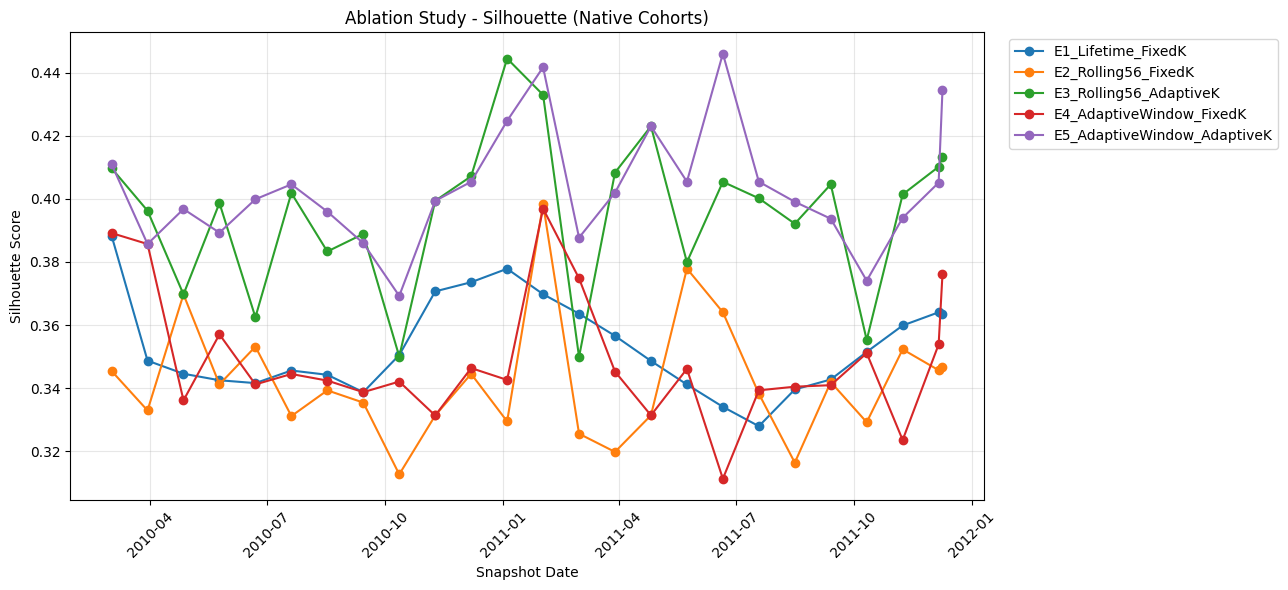

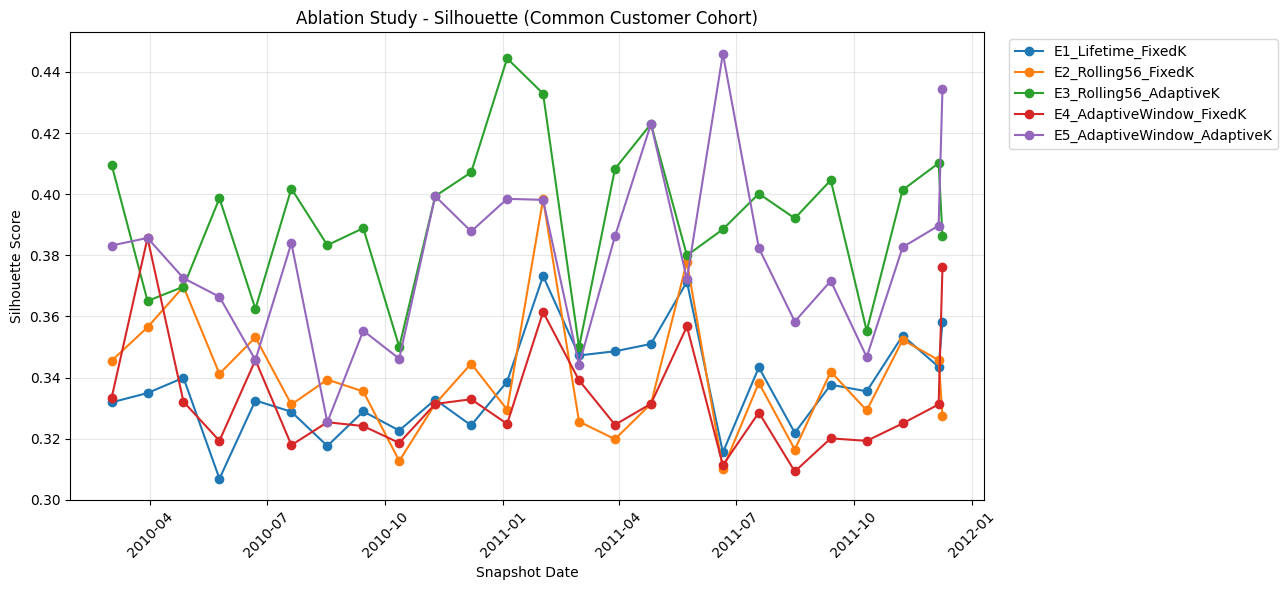

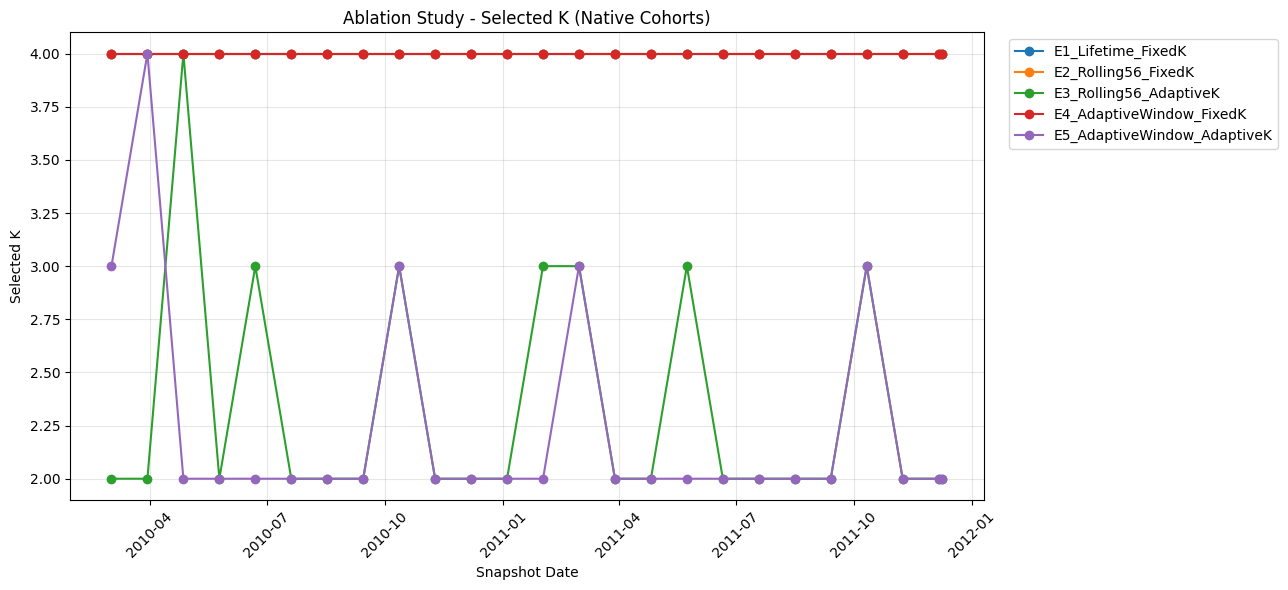

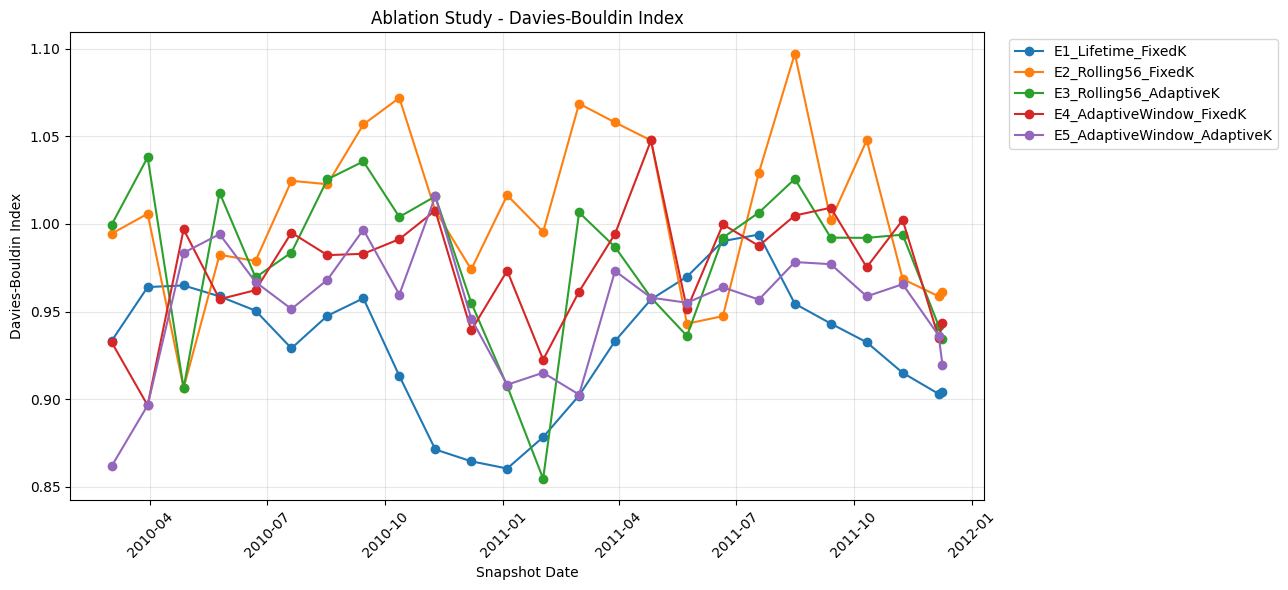


CELL 15 - ABLATION STUDY COMPLETED
Successful native experiment runs: 125
Expected native experiment runs: 125
Native experiment failures: 0
Experiments represented: 5
Common-cohort experiment rows: 125
Complete common-cohort snapshots: 25

Available outputs:
- ablation_history
- ablation_results
- ablation_summary
- ablation_k_selection
- ablation_failures
- ablation_common_cohort_results
- ablation_common_cohort_profiles
- ablation_common_cohort_summary
- ablation_comparison

Recommended interpretation:
Use ablation_comparison for comparisons across E1-E5 because all experiments use the same customer cohort.


In [ ]:

# ============================================================
# CELL 15 - ABLATION STUDY
# Adaptive Rolling Dynamic RFM
#
# E1: Lifetime RFM + Fixed K
# E2: Fixed Window 56 + Fixed K
# E3: Fixed Window 56 + Adaptive K
# E4: Adaptive Window + Fixed K
# E5: Adaptive Window + Adaptive K
#
# Improvements:
# 1. Reuse Cell 8 Adaptive K-Means algorithm.
# 2. Record failures explicitly.
# 3. Compare all five experiments on a common cohort.
# 4. Keep native-cohort and common-cohort results separate.
# 5. Report K selection and cluster-size diagnostics.
#
# Outputs:
# - ablation_history
# - ablation_results
# - ablation_summary
# - ablation_k_selection
# - ablation_failures
# - ablation_common_cohort_results
# - ablation_common_cohort_profiles
# - ablation_comparison
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)


# ============================================================
# 0. CONFIGURATION
# ============================================================

ABLATION_FIXED_K = 4

ABLATION_RANDOM_STATE = 42

ABLATION_N_INIT = 10

ABLATION_SILHOUETTE_SAMPLE = 10000

ABLATION_MIN_CUSTOMERS = 10

ABLATION_MIN_COMMON_COHORT = 10

# Must agree with the fixed K used in Cell 14.
if "BASELINE_FIXED_K" in globals():

    ABLATION_FIXED_K = int(BASELINE_FIXED_K)


# ============================================================
# 1. VALIDATE INPUTS
# ============================================================

required_objects = [
    "baseline_transactions",
    "baseline_calculate_rfm",
    "baseline_transform_rfm",
    "baseline_evaluate_clustering",
    "snapshot_dates",
    "adaptive_history",
    "evaluate_k_candidates"
]

for object_name in required_objects:

    if object_name not in globals():

        raise NameError(
            f"Missing '{object_name}'. "
            "Run Cells 1-14 before Cell 15."
        )

if not adaptive_history:

    raise ValueError(
        "adaptive_history is empty. Run Cell 10 first."
    )

if len(snapshot_dates) == 0:

    raise ValueError(
        "snapshot_dates is empty."
    )

if ABLATION_FIXED_K < 2:

    raise ValueError(
        "ABLATION_FIXED_K must be at least 2."
    )

print("=" * 80)
print("ABLATION STUDY - VALIDATION")
print("=" * 80)

print("Fixed K:", ABLATION_FIXED_K)

print("Snapshots:", len(snapshot_dates))

print("Adaptive snapshots:", len(adaptive_history))


# ============================================================
# 2. BUILD ADAPTIVE WINDOW LOOKUP
# ============================================================

adaptive_lookup = {}

for item in adaptive_history:

    snapshot_key = pd.Timestamp(
        item["snapshot_date"]
    ).normalize()

    adaptive_lookup[snapshot_key] = item


def ablation_get_adaptive_window(value):

    if isinstance(value, (int, float, np.integer, np.floating)):

        if not np.isfinite(value):
            raise ValueError(
                f"Invalid adaptive window: {value}"
            )

        return int(value)

    raise ValueError(
        f"Adaptive window must be numeric, got: {value}"
    )


print(
    "Adaptive window lookup:",
    len(adaptive_lookup),
    "snapshots"
)


# ============================================================
# 3. REUSE CELL 8 ADAPTIVE K-MEANS
# ============================================================

def ablation_select_adaptive_k(X):

    """
    Use the exact Adaptive K selection function from Cell 8.

    Cell 8 performs:
        - Candidate K evaluation
        - Minimum cluster-size filtering
        - Silhouette normalization
        - DBI normalization
        - CHI normalization
        - Composite score calculation

    This avoids implementing a different K-selection
    algorithm inside the ablation study.
    """

    best_result, k_metrics = evaluate_k_candidates(X)

    if best_result is None:

        raise RuntimeError(
            "Cell 8 evaluate_k_candidates returned no valid K."
        )

    selected_k = int(
        best_result["best_k"]
    )

    return selected_k, k_metrics.copy(), best_result


# ============================================================
# 4. DEFINE ABLATION EXPERIMENTS
# ============================================================

ABLATION_EXPERIMENTS = [

    {
        "name": "E1_Lifetime_FixedK",
        "window_type": "lifetime",
        "adaptive_k": False
    },

    {
        "name": "E2_Rolling56_FixedK",
        "window_type": "fixed56",
        "adaptive_k": False
    },

    {
        "name": "E3_Rolling56_AdaptiveK",
        "window_type": "fixed56",
        "adaptive_k": True
    },

    {
        "name": "E4_AdaptiveWindow_FixedK",
        "window_type": "adaptive",
        "adaptive_k": False
    },

    {
        "name": "E5_AdaptiveWindow_AdaptiveK",
        "window_type": "adaptive",
        "adaptive_k": True
    }

]

EXPECTED_EXPERIMENTS = len(
    ABLATION_EXPERIMENTS
)


# ============================================================
# 5. HELPER: DETERMINE WINDOW
# ============================================================

def ablation_resolve_window(
    experiment,
    snapshot_date
):

    window_type = experiment["window_type"]

    if window_type == "lifetime":

        return None

    if window_type == "fixed56":

        return 56

    if window_type == "adaptive":

        snapshot_key = pd.Timestamp(
            snapshot_date
        ).normalize()

        if snapshot_key not in adaptive_lookup:

            raise KeyError(
                f"No adaptive result for {snapshot_key.date()}."
            )

        adaptive_record = adaptive_lookup[
            snapshot_key
        ]

        return ablation_get_adaptive_window(
            adaptive_record["window"]
        )

    raise ValueError(
        f"Unknown window type: {window_type}"
    )


# ============================================================
# 6. RUN ONE NATIVE-COHORT EXPERIMENT
# ============================================================

def ablation_run_experiment(
    experiment_name,
    snapshot_date,
    window_days,
    adaptive_k=False,
    fixed_k=ABLATION_FIXED_K
):

    # --------------------------------------------------------
    # Calculate RFM
    # --------------------------------------------------------

    rfm = baseline_calculate_rfm(

        transactions=baseline_transactions,

        snapshot_date=snapshot_date,

        window_days=window_days

    )

    if len(rfm) < max(
        ABLATION_MIN_CUSTOMERS,
        fixed_k + 1
    ):

        raise ValueError(
            f"Insufficient customers: {len(rfm)}."
        )

    # --------------------------------------------------------
    # Transform RFM
    # --------------------------------------------------------

    X, scaler = baseline_transform_rfm(
        rfm
    )

    # --------------------------------------------------------
    # Select K
    # --------------------------------------------------------

    k_table = None

    adaptive_k_details = None

    if adaptive_k:

        selected_k, k_table, adaptive_k_details = (
            ablation_select_adaptive_k(X)
        )

    else:

        selected_k = int(fixed_k)

    if len(rfm) <= selected_k:

        raise ValueError(
            f"Number of customers ({len(rfm)}) "
            f"must be greater than K ({selected_k})."
        )

    # --------------------------------------------------------
    # Final K-Means
    # --------------------------------------------------------

    model = KMeans(

        n_clusters=selected_k,

        random_state=ABLATION_RANDOM_STATE,

        n_init=ABLATION_N_INIT

    )

    labels = model.fit_predict(X)

    cluster_sizes = np.bincount(
        labels,
        minlength=selected_k
    )

    # --------------------------------------------------------
    # Evaluation
    # --------------------------------------------------------

    metrics = baseline_evaluate_clustering(
        X,
        labels
    )

    result = {

        "experiment": experiment_name,

        "snapshot_date": pd.Timestamp(
            snapshot_date
        ),

        "window_days": (
            "Lifetime"
            if window_days is None
            else int(window_days)
        ),

        "k_selection": (
            "Adaptive"
            if adaptive_k
            else "Fixed"
        ),

        "selected_k": selected_k,

        "n_customers": len(rfm),

        "n_clusters": len(
            np.unique(labels)
        ),

        "min_cluster_size": int(
            cluster_sizes.min()
        ),

        "max_cluster_size": int(
            cluster_sizes.max()
        ),

        "minimum_cluster_fraction": float(
            cluster_sizes.min() / len(rfm)
        ),

        "silhouette": metrics["silhouette"],

        "davies_bouldin": metrics["davies_bouldin"],

        "calinski_harabasz": metrics["calinski_harabasz"],

        "inertia": float(model.inertia_),

        "rfm": rfm.copy(),

        "X": X,

        "labels": labels.copy(),

        "model": model,

        "scaler": scaler,

        "k_metrics": k_table

    }

    return result, k_table


# ============================================================
# 7. EXECUTE FIVE ABLATION EXPERIMENTS
# ============================================================

ablation_history = []

ablation_k_selection_records = []

ablation_failures = []

print("\n" + "=" * 80)
print("STARTING ABLATION EXPERIMENTS")
print("=" * 80)

for snapshot_index, snapshot_date in enumerate(
    snapshot_dates
):

    snapshot_date = pd.Timestamp(
        snapshot_date
    )

    print(
        f"\nSnapshot {snapshot_index + 1}/{len(snapshot_dates)}: "
        f"{snapshot_date.date()}"
    )

    for experiment in ABLATION_EXPERIMENTS:

        experiment_name = experiment["name"]

        try:

            # Resolve window.
            window_days = ablation_resolve_window(
                experiment,
                snapshot_date
            )

            # Run experiment.
            result, k_table = ablation_run_experiment(

                experiment_name=experiment_name,

                snapshot_date=snapshot_date,

                window_days=window_days,

                adaptive_k=experiment["adaptive_k"],

                fixed_k=ABLATION_FIXED_K

            )

            ablation_history.append(
                result
            )

            # Save candidate K evaluation table.
            if k_table is not None:

                k_table = k_table.copy()

                k_table["experiment"] = experiment_name

                k_table["snapshot_date"] = snapshot_date

                k_table["selected_k"] = result[
                    "selected_k"
                ]

                ablation_k_selection_records.append(
                    k_table.reset_index(names="candidate_k")
                )

            print(

                f"  {experiment_name}: "

                f"Window={result['window_days']}, "

                f"K={result['selected_k']}, "

                f"Customers={result['n_customers']:,}, "

                f"Silhouette={result['silhouette']:.4f}"

            )

        except Exception as error:

            failure_record = {

                "experiment": experiment_name,

                "snapshot_date": snapshot_date,

                "error_type": type(error).__name__,

                "error_message": str(error)

            }

            ablation_failures.append(
                failure_record
            )

            print(
                f"  FAILED {experiment_name}: "
                f"{type(error).__name__}: {error}"
            )


# ============================================================
# 8. BUILD NATIVE-COHORT RESULTS
# ============================================================

if not ablation_history:

    raise RuntimeError(
        "No ablation experiment completed successfully. "
        "Inspect ablation_failures."
    )

ablation_results = pd.DataFrame([

    {

        "experiment": item["experiment"],

        "snapshot_date": item["snapshot_date"],

        "window_days": item["window_days"],

        "k_selection": item["k_selection"],

        "selected_k": item["selected_k"],

        "n_customers": item["n_customers"],

        "n_clusters": item["n_clusters"],

        "min_cluster_size": item["min_cluster_size"],

        "max_cluster_size": item["max_cluster_size"],

        "minimum_cluster_fraction": item[
            "minimum_cluster_fraction"
        ],

        "silhouette": item["silhouette"],

        "davies_bouldin": item["davies_bouldin"],

        "calinski_harabasz": item["calinski_harabasz"],

        "inertia": item["inertia"]

    }

    for item in ablation_history

])

ablation_failures = pd.DataFrame(
    ablation_failures
)

print("\n" + "=" * 80)
print("NATIVE-COHORT ABLATION RESULTS")
print("=" * 80)

display(
    ablation_results.round(4)
)

if not ablation_failures.empty:

    print("\nExperiment failures:")

    display(
        ablation_failures
    )

else:

    print(
        "\nAll experiment/snapshot combinations completed successfully."
    )


# ============================================================
# 9. BUILD ABLATION SUMMARY
# ============================================================

ablation_summary = (

    ablation_results

    .groupby("experiment")

    .agg(

        snapshots=("snapshot_date", "nunique"),

        mean_k=("selected_k", "mean"),

        std_k=("selected_k", "std"),

        mean_customers=("n_customers", "mean"),

        mean_silhouette=("silhouette", "mean"),

        std_silhouette=("silhouette", "std"),

        mean_davies_bouldin=("davies_bouldin", "mean"),

        mean_calinski_harabasz=("calinski_harabasz", "mean"),

        mean_inertia=("inertia", "mean"),

        mean_minimum_cluster_fraction=(
            "minimum_cluster_fraction",
            "mean"
        )

    )

    .reset_index()

)

print("\n" + "=" * 80)
print("ABLATION SUMMARY - NATIVE COHORT")
print("=" * 80)

display(
    ablation_summary.round(4)
)


# ============================================================
# 10. BUILD ADAPTIVE K SELECTION TABLE
# ============================================================

ablation_k_selection = (

    pd.concat(
        ablation_k_selection_records,
        ignore_index=True
    )

    if ablation_k_selection_records

    else pd.DataFrame()

)

print("\nAdaptive K candidate records:")

if not ablation_k_selection.empty:

    display(
        ablation_k_selection.head(20).round(4)
    )

else:

    print(
        "No adaptive K candidate records were produced."
    )


# ============================================================
# 11. COMMON-COHORT EVALUATION
# ============================================================

def ablation_evaluate_common_cohort(
    snapshot_date,
    experiment_records
):

    """
    Refit each experiment on the intersection of customer IDs
    available in all five experiments for this snapshot.

    Adaptive K is re-selected on this common cohort using
    the exact Cell 8 evaluate_k_candidates function.

    Fixed K remains ABLATION_FIXED_K.

    This is a separate controlled comparison; it does not
    overwrite native-cohort experiment results.
    """

    if len(experiment_records) != EXPECTED_EXPERIMENTS:

        raise ValueError(
            "Not all five experiments are available "
            "for this snapshot."
        )

    customer_sets = [

        set(item["rfm"].index)

        for item in experiment_records

    ]

    common_customers = set.intersection(
        *customer_sets
    )

    common_customers = sorted(
        common_customers
    )

    if len(common_customers) < ABLATION_MIN_COMMON_COHORT:

        raise ValueError(
            f"Common cohort too small: "
            f"{len(common_customers)} customers."
        )

    common_results = []

    common_profiles = []

    for item in experiment_records:

        experiment_name = item["experiment"]

        rfm = item["rfm"].loc[
            common_customers
        ].copy()

        X, scaler = baseline_transform_rfm(
            rfm
        )

        # Re-select K on the common cohort for adaptive variants.
        if item["k_selection"] == "Adaptive":

            selected_k, k_table, best_details = (
                ablation_select_adaptive_k(X)
            )

        else:

            selected_k = ABLATION_FIXED_K

            k_table = None

        if len(rfm) <= selected_k:

            raise ValueError(
                f"{experiment_name}: common cohort "
                f"({len(rfm)}) is too small for K={selected_k}."
            )

        model = KMeans(

            n_clusters=selected_k,

            random_state=ABLATION_RANDOM_STATE,

            n_init=ABLATION_N_INIT

        )

        labels = model.fit_predict(X)

        metrics = baseline_evaluate_clustering(
            X,
            labels
        )

        cluster_sizes = np.bincount(
            labels,
            minlength=selected_k
        )

        common_results.append({

            "snapshot_date": pd.Timestamp(snapshot_date),

            "experiment": experiment_name,

            "n_common_customers": len(common_customers),

            "selected_k": selected_k,

            "n_clusters": len(np.unique(labels)),

            "silhouette": metrics["silhouette"],

            "davies_bouldin": metrics["davies_bouldin"],

            "calinski_harabasz": metrics["calinski_harabasz"],

            "inertia": float(model.inertia_),

            "min_cluster_size": int(cluster_sizes.min()),

            "max_cluster_size": int(cluster_sizes.max()),

            "minimum_cluster_fraction": float(
                cluster_sizes.min() / len(rfm)
            )

        })

        profile = rfm.copy()

        profile["Cluster"] = labels

        profile["CustomerID"] = profile.index

        profile["experiment"] = experiment_name

        profile["snapshot_date"] = pd.Timestamp(
            snapshot_date
        )

        common_profiles.append(
            profile.reset_index(drop=True)
        )

    return (
        pd.DataFrame(common_results),
        pd.concat(
            common_profiles,
            ignore_index=True
        )
    )


# ============================================================
# 12. RUN COMMON-COHORT COMPARISON
# ============================================================

ablation_common_results_records = []

ablation_common_profiles_records = []

successful_snapshot_keys = set(
    ablation_results["snapshot_date"].dt.normalize()
)

for snapshot_date in snapshot_dates:

    snapshot_date = pd.Timestamp(
        snapshot_date
    )

    snapshot_records = [

        item for item in ablation_history

        if pd.Timestamp(
            item["snapshot_date"]
        ).normalize() == snapshot_date.normalize()

    ]

    if len(snapshot_records) != EXPECTED_EXPERIMENTS:

        print(
            f"Common cohort skipped for "
            f"{snapshot_date.date()}: "
            f"{len(snapshot_records)}/{EXPECTED_EXPERIMENTS} experiments."
        )

        continue

    try:

        common_results, common_profiles = (
            ablation_evaluate_common_cohort(

                snapshot_date=snapshot_date,

                experiment_records=snapshot_records

            )
        )

        ablation_common_results_records.append(
            common_results
        )

        ablation_common_profiles_records.append(
            common_profiles
        )

        print(

            f"Common cohort {snapshot_date.date()}: "

            f"{common_results['n_common_customers'].iloc[0]:,} customers"

        )

    except Exception as error:

        ablation_failures = pd.concat(

            [

                ablation_failures,

                pd.DataFrame([{

                    "experiment": "COMMON_COHORT",

                    "snapshot_date": snapshot_date,

                    "error_type": type(error).__name__,

                    "error_message": str(error)

                }])

            ],

            ignore_index=True

        )

        print(
            f"Common-cohort evaluation failed "
            f"for {snapshot_date.date()}: {error}"
        )


ablation_common_cohort_results = (

    pd.concat(
        ablation_common_results_records,
        ignore_index=True
    )

    if ablation_common_results_records

    else pd.DataFrame()

)

ablation_common_cohort_profiles = (

    pd.concat(
        ablation_common_profiles_records,
        ignore_index=True
    )

    if ablation_common_profiles_records

    else pd.DataFrame()

)

# This is the preferred comparison table for paired
# cross-experiment interpretation.
ablation_comparison = ablation_common_cohort_results.copy()


# ============================================================
# 13. COMMON-COHORT SUMMARY
# ============================================================

if not ablation_common_cohort_results.empty:

    ablation_common_cohort_summary = (

        ablation_common_cohort_results

        .groupby("experiment")

        .agg(

            snapshots=("snapshot_date", "nunique"),

            mean_common_customers=("n_common_customers", "mean"),

            mean_k=("selected_k", "mean"),

            mean_silhouette=("silhouette", "mean"),

            std_silhouette=("silhouette", "std"),

            mean_davies_bouldin=("davies_bouldin", "mean"),

            mean_calinski_harabasz=("calinski_harabasz", "mean")

        )

        .reset_index()

    )

    print("\n" + "=" * 80)
    print("ABLATION SUMMARY - COMMON COHORT")
    print("=" * 80)

    display(
        ablation_common_cohort_summary.round(4)
    )

else:

    ablation_common_cohort_summary = pd.DataFrame()

    print(
        "\nNo common-cohort ablation results available."
    )


# ============================================================
# 14. PAIRED SNAPSHOT COMPARISON
# ============================================================

if not ablation_common_cohort_results.empty:

    complete_snapshot_counts = (

        ablation_common_cohort_results

        .groupby("snapshot_date")["experiment"]

        .nunique()

    )

    complete_ablation_snapshots = (
        complete_snapshot_counts[
            complete_snapshot_counts == EXPECTED_EXPERIMENTS
        ].index
    )

    ablation_comparison = (
        ablation_common_cohort_results[
            ablation_common_cohort_results["snapshot_date"].isin(
                complete_ablation_snapshots
            )
        ].copy()
    )

else:

    complete_ablation_snapshots = []

    ablation_comparison = pd.DataFrame()


print(
    "\nComplete common-cohort snapshots:",
    len(complete_ablation_snapshots)
)

if not ablation_failures.empty:

    print(
        "Total recorded failures:",
        len(ablation_failures)
    )


# ============================================================
# 15. VISUALIZE SILHOUETTE - NATIVE COHORT
# ============================================================

plt.figure(figsize=(13, 6))

for experiment_name in ablation_results[
    "experiment"
].unique():

    subset = ablation_results[
        ablation_results["experiment"] == experiment_name
    ].sort_values("snapshot_date")

    plt.plot(

        subset["snapshot_date"],

        subset["silhouette"],

        marker="o",

        label=experiment_name

    )

plt.title(
    "Ablation Study - Silhouette (Native Cohorts)"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Silhouette Score")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ============================================================
# 16. VISUALIZE SILHOUETTE - COMMON COHORT
# ============================================================

if not ablation_comparison.empty:

    plt.figure(figsize=(13, 6))

    for experiment_name in ablation_comparison[
        "experiment"
    ].unique():

        subset = ablation_comparison[
            ablation_comparison["experiment"] == experiment_name
        ].sort_values("snapshot_date")

        plt.plot(

            subset["snapshot_date"],

            subset["silhouette"],

            marker="o",

            label=experiment_name

        )

    plt.title(
        "Ablation Study - Silhouette (Common Customer Cohort)"
    )

    plt.xlabel("Snapshot Date")

    plt.ylabel("Silhouette Score")

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.grid(alpha=0.3)

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()


# ============================================================
# 17. VISUALIZE SELECTED K
# ============================================================

plt.figure(figsize=(13, 6))

for experiment_name in ablation_results[
    "experiment"
].unique():

    subset = ablation_results[
        ablation_results["experiment"] == experiment_name
    ].sort_values("snapshot_date")

    plt.plot(

        subset["snapshot_date"],

        subset["selected_k"],

        marker="o",

        label=experiment_name

    )

plt.title(
    "Ablation Study - Selected K (Native Cohorts)"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Selected K")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ============================================================
# 18. VISUALIZE DAVIES-BOULDIN INDEX
# ============================================================

plt.figure(figsize=(13, 6))

for experiment_name in ablation_results[
    "experiment"
].unique():

    subset = ablation_results[
        ablation_results["experiment"] == experiment_name
    ].sort_values("snapshot_date")

    plt.plot(

        subset["snapshot_date"],

        subset["davies_bouldin"],

        marker="o",

        label=experiment_name

    )

plt.title(
    "Ablation Study - Davies-Bouldin Index"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Davies-Bouldin Index")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"

)

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ============================================================
# 19. FINAL COMPLETION SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("CELL 15 - ABLATION STUDY COMPLETED")
print("=" * 80)

print(
    "Successful native experiment runs:",
    len(ablation_history)
)

print(
    "Expected native experiment runs:",
    len(snapshot_dates) * EXPECTED_EXPERIMENTS
)

print(
    "Native experiment failures:",
    len(ablation_failures)
)

print(
    "Experiments represented:",
    ablation_results["experiment"].nunique()
)

print(
    "Common-cohort experiment rows:",
    len(ablation_common_cohort_results)
)

print(
    "Complete common-cohort snapshots:",
    len(complete_ablation_snapshots)
)

print("\nAvailable outputs:")

print("- ablation_history")
print("- ablation_results")
print("- ablation_summary")
print("- ablation_k_selection")
print("- ablation_failures")
print("- ablation_common_cohort_results")
print("- ablation_common_cohort_profiles")
print("- ablation_common_cohort_summary")
print("- ablation_comparison")

print("\nRecommended interpretation:")
print(
    "Use ablation_comparison for comparisons across E1-E5 "
    "because all experiments use the same customer cohort."
)


Cell 16 — Visualization và xuất kết quả

FINAL ANALYSIS
Adaptive snapshots: 25
Baseline rows: 100
Ablation rows: 125

ADAPTIVE MODEL SUMMARY


,snapshot_date,window_days,selected_k,n_customers,n_clusters,silhouette,davies_bouldin,calinski_harabasz,minimum_cluster_size,maximum_cluster_size,minimum_cluster_fraction,inertia
0,2010-03-02,91,3,1719,3,0.4110,0.8618,1483.5098,392,858,0.2280,1889.6876
1,2010-03-30,28,4,958,4,0.3857,0.8965,563.5734,24,402,0.0251,1036.7101
2,2010-04-27,91,2,1938,2,0.3968,0.9835,1445.5394,628,1310,0.3240,3328.6366
3,2010-05-25,91,2,2031,2,0.3893,0.9942,1513.1022,704,1327,0.3466,3490.2147
4,2010-06-22,91,2,2066,2,0.3999,0.9669,1581.0151,684,1382,0.3311,3509.6348
5,2010-07-20,91,2,2059,2,0.4046,0.9515,1671.9243,671,1388,0.3259,3407.4460
6,2010-08-17,91,2,1961,2,0.3959,0.9682,1577.8013,733,1228,0.3738,3258.5367
7,2010-09-14,91,2,1905,2,0.3859,0.9968,1478.7209,696,1209,0.3654,3216.0161
8,2010-10-12,91,3,2244,3,0.3692,0.9597,1695.5581,509,1080,0.2268,2678.6400
9,2010-11-09,56,2,2201,2,0.3994,1.0157,1506.7541,634,1567,0.2881,3918.3134



ADAPTIVE OVERALL SUMMARY


,snapshots,mean_customers,mean_selected_k,mean_silhouette,std_silhouette,mean_davies_bouldin,mean_calinski_harabasz,mean_minimum_cluster_fraction
0,25,1987.84,2.24,0.4032,0.0189,0.9524,1570.3117,0.2962



NATIVE-COHORT METHOD COMPARISON


,method,snapshots,mean_customers,mean_k,mean_silhouette,std_silhouette,mean_davies_bouldin,mean_calinski_harabasz
0,Adaptive Rolling Dynamic RFM,25,1987.84,2.24,0.4032,0.0189,0.9524,1570.3117
1,Lifetime RFM,25,4199.56,4.00,0.3532,0.0150,0.9317,4038.7863
2,Rolling 28 Days,25,1018.52,4.00,0.3372,0.0214,0.9838,599.5579
3,Rolling 56 Days,25,1632.96,4.00,0.3422,0.0195,1.0067,1100.4897
4,Rolling 91 Days,25,2154.16,4.00,0.3495,0.0164,0.9728,1654.3486


... (12 outputs left out)


DRIFT EXPERIMENT SUMMARY


,real_snapshots,real_raw_alarm_count,real_grouped_drift_events,synthetic_precision,synthetic_recall,synthetic_f1,synthetic_detection_delay,synthetic_false_alarms_per_100_points,monte_carlo_mean_precision,monte_carlo_mean_recall,monte_carlo_mean_f1,monte_carlo_std_f1,monte_carlo_mean_detection_delay,monte_carlo_mean_false_alarms_per_100_points
0,25,1,1,0.0,0.0,0.0,NaN,0.588235,0.166667,0.166667,0.166667,0.239732,0.0,0.784314



MONTE CARLO DRIFT SUMMARY


,precision,recall,f1_score,mean_detection_delay,false_alarms_per_100_points
mean,0.166667,0.166667,0.166667,0.0,0.784314
std,0.239732,0.239732,0.239732,0.0,0.282037


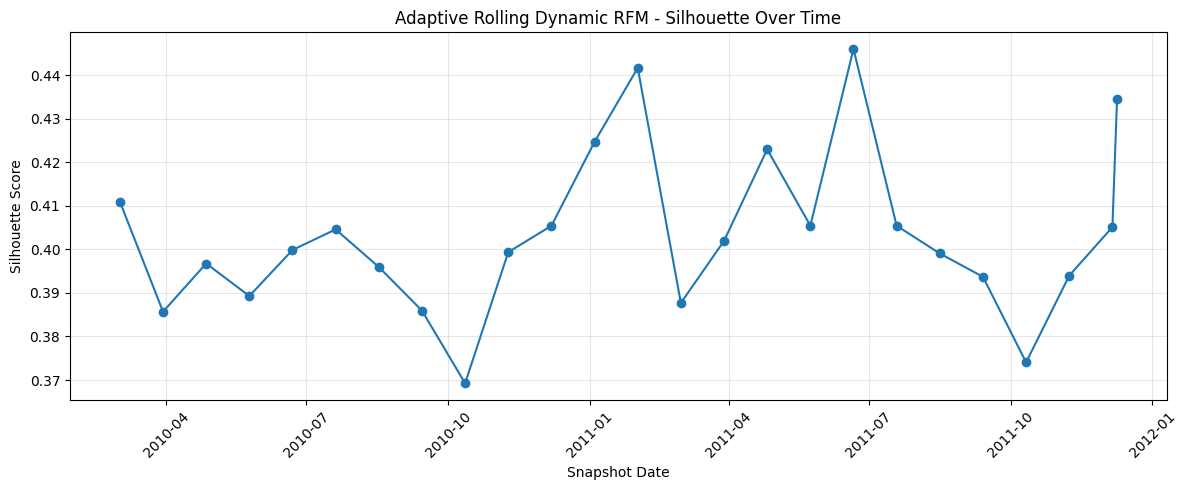

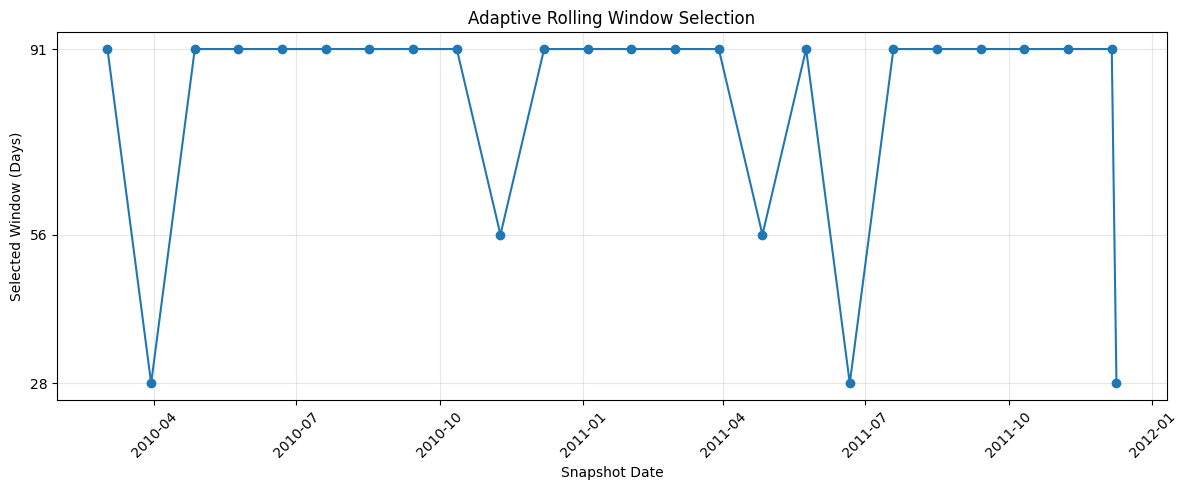

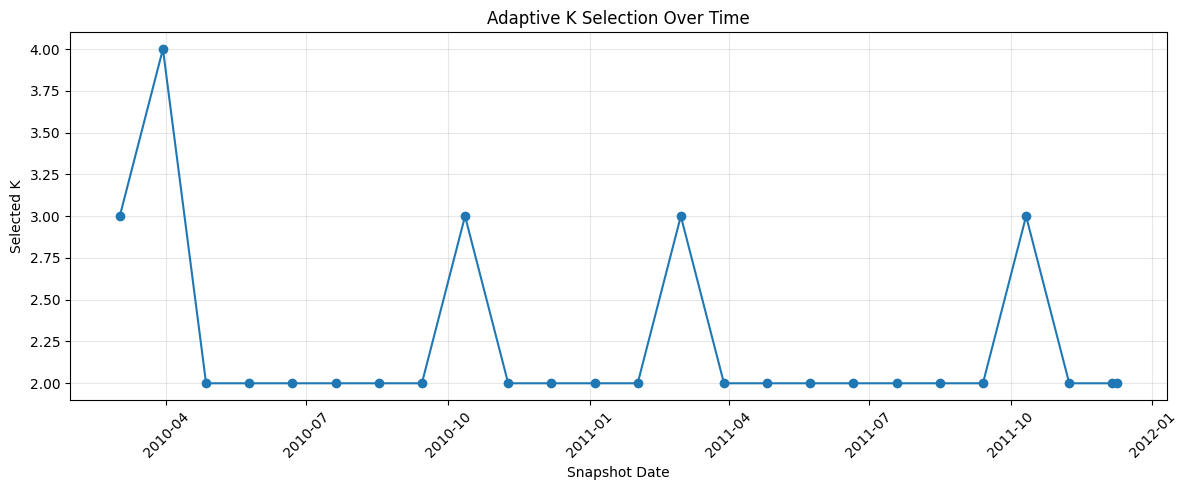

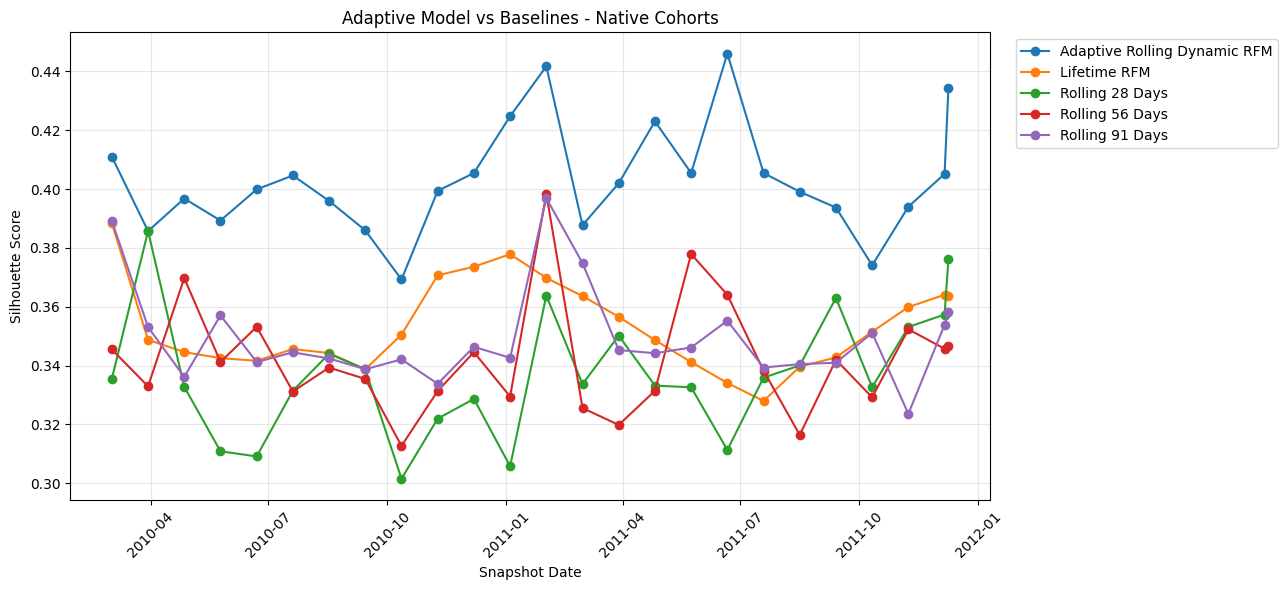

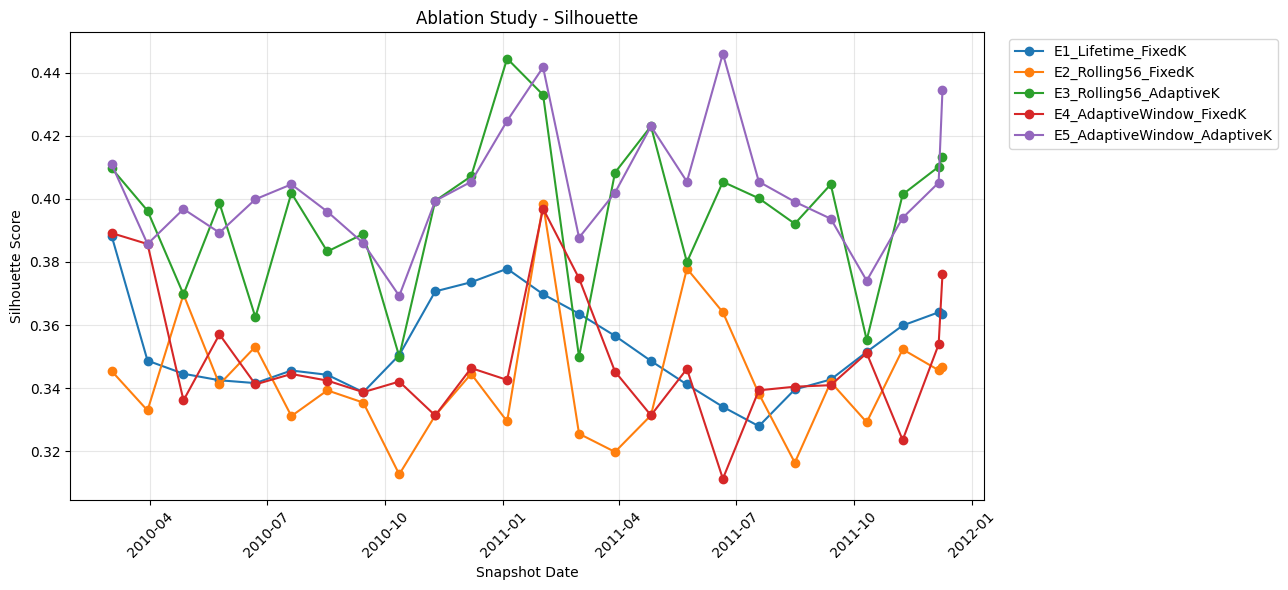

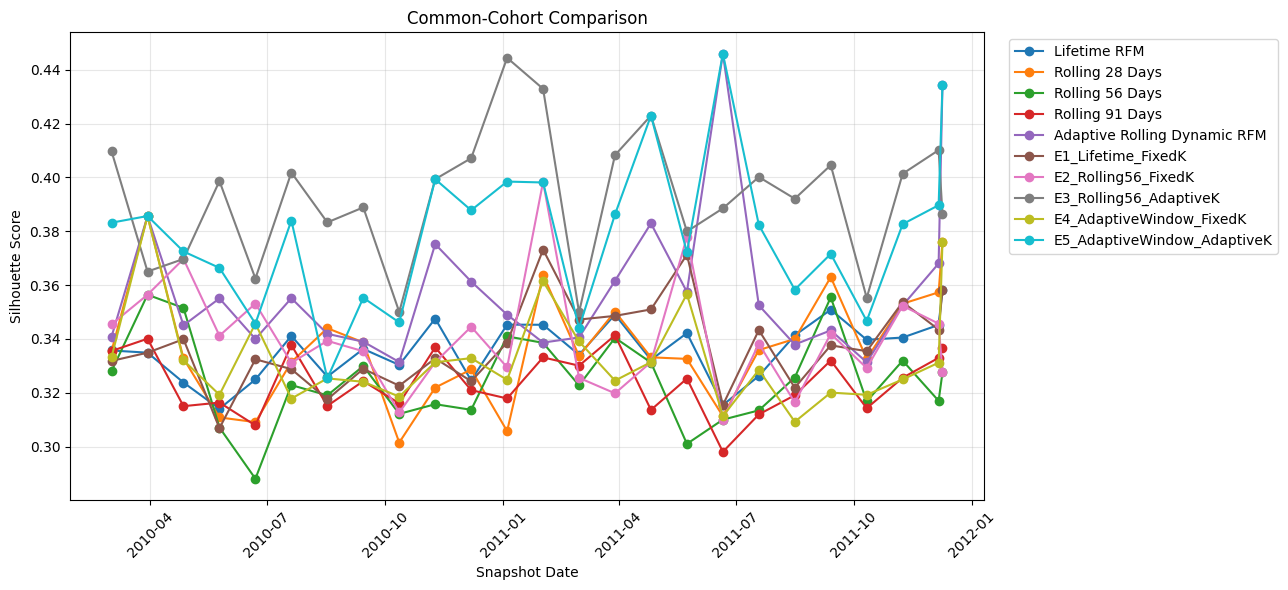

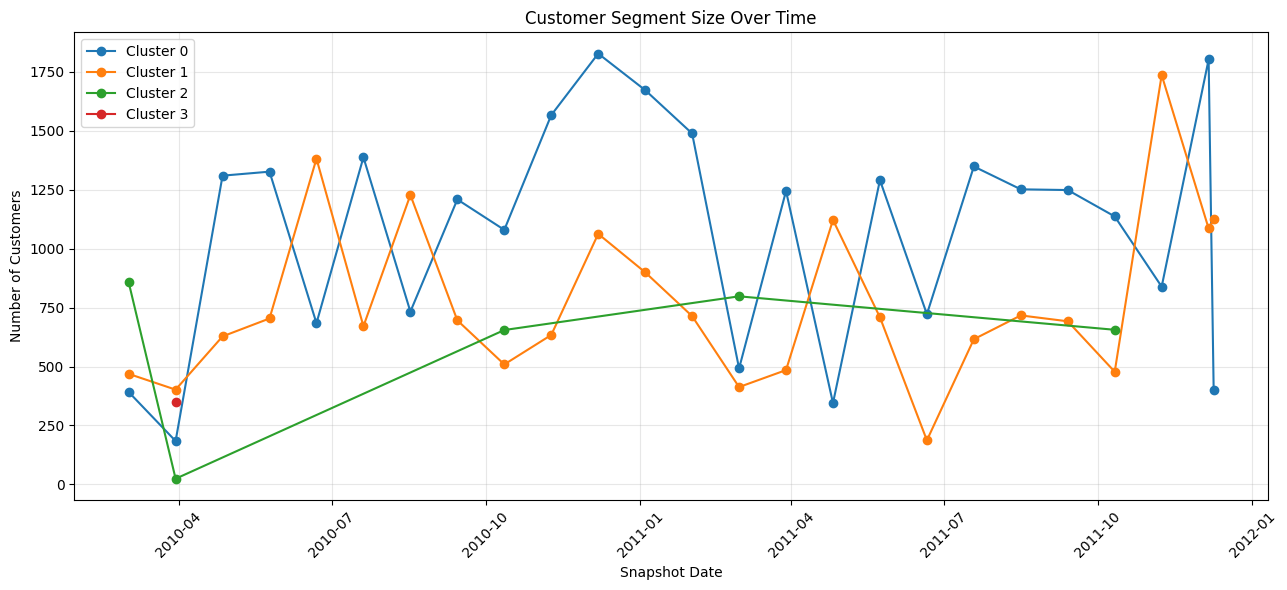

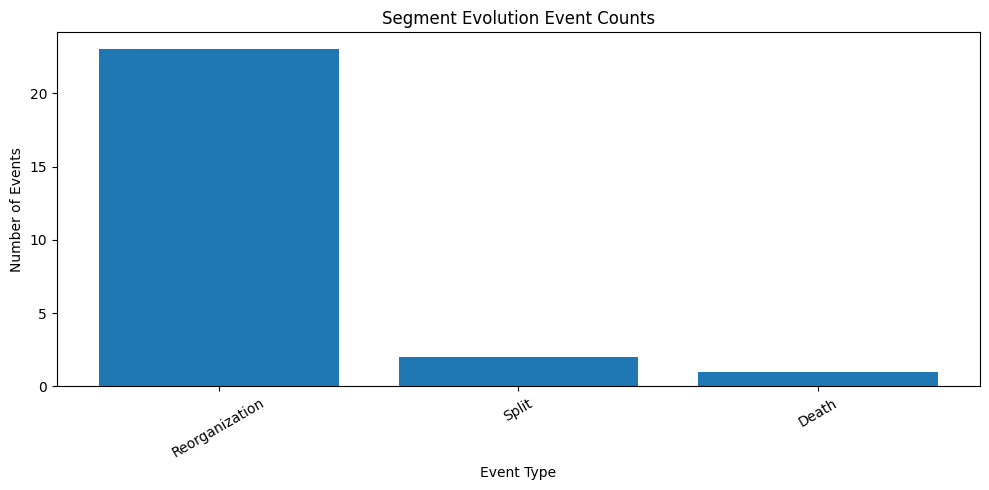

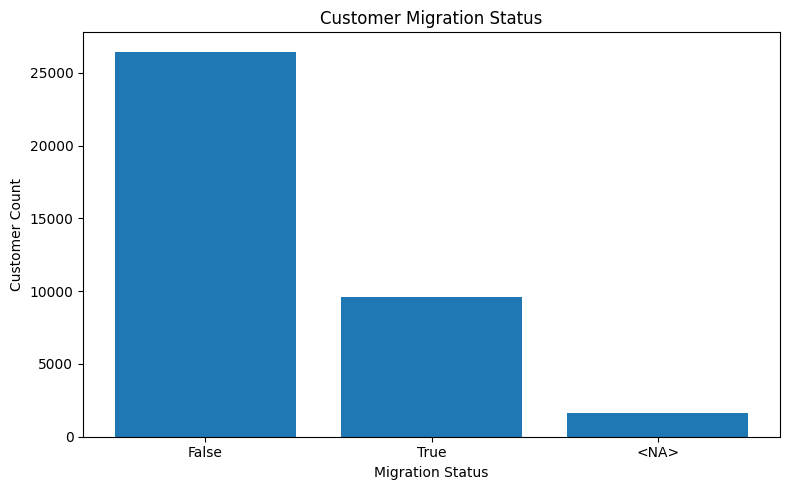

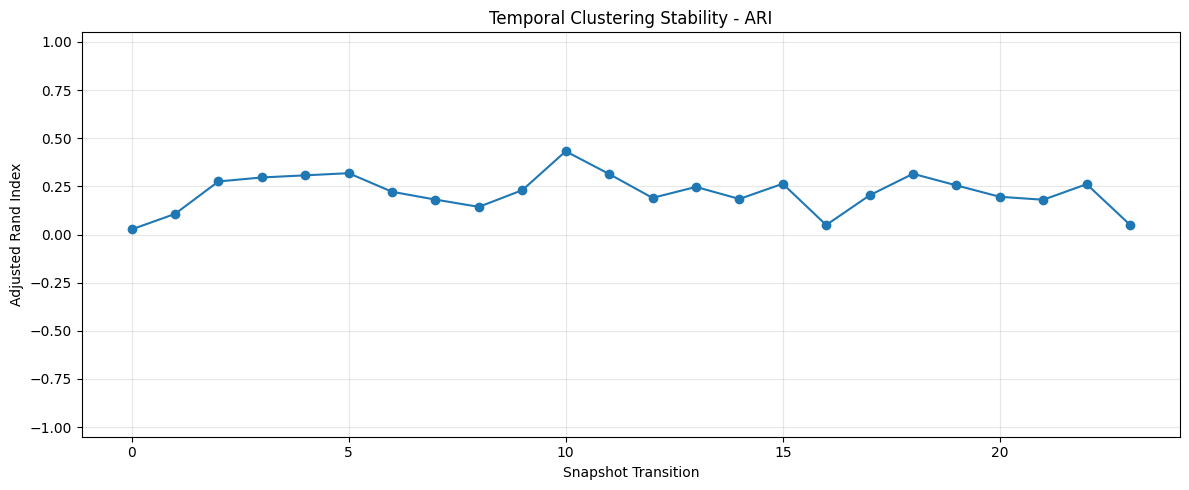

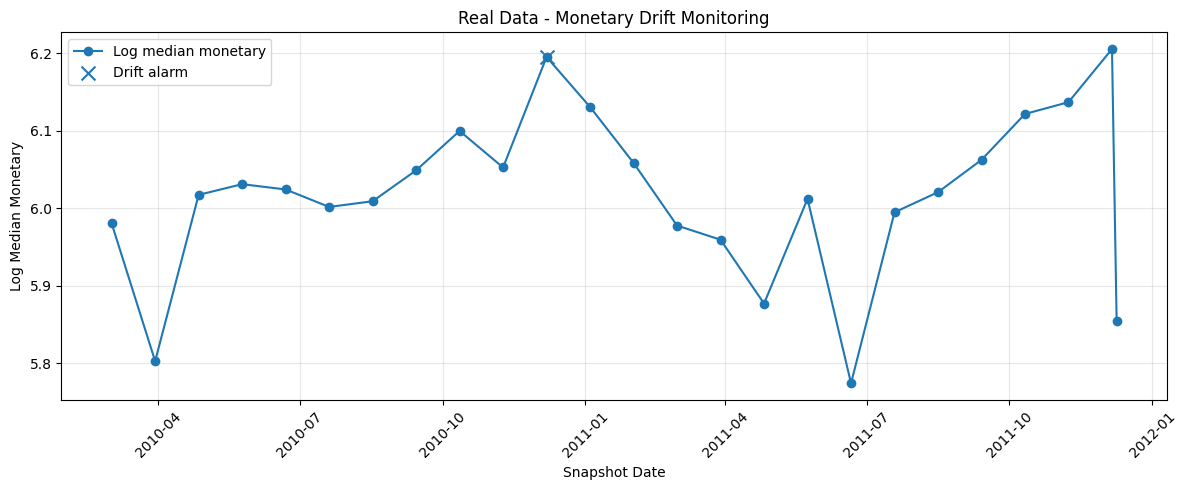

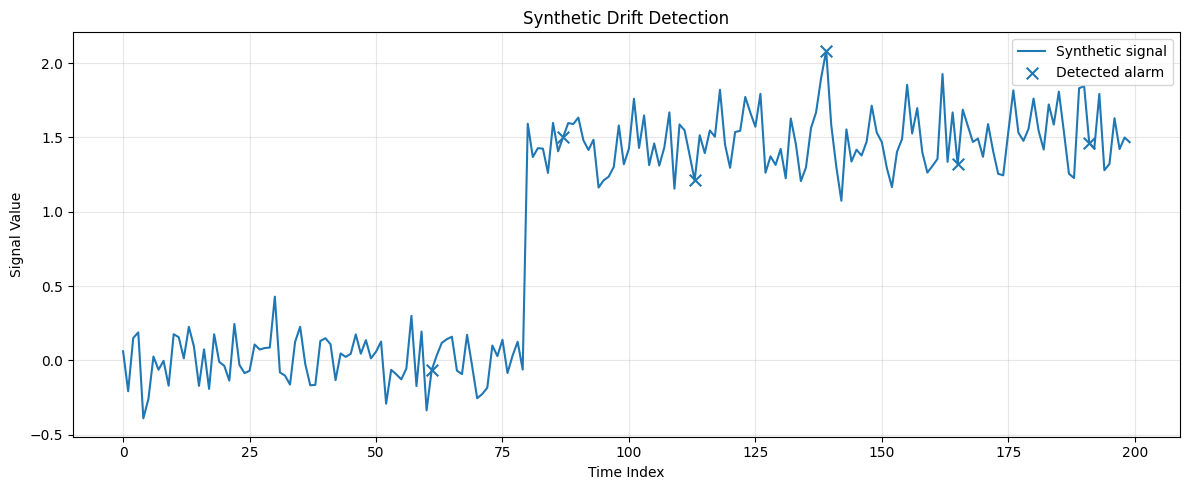


FINAL EXPERIMENT SUMMARY


,Value
dataset_rows,779425.000000
dataset_customers,5878.000000
dataset_invoices,36969.000000
snapshot_count,25.000000
adaptive_mean_silhouette,0.403178
adaptive_mean_davies_bouldin,0.952365
adaptive_mean_calinski_harabasz,1570.311653
adaptive_mean_window_days,80.640000
adaptive_mean_k,2.240000
baseline_method_count,4.000000


Exported: adaptive_model_summary
Exported: adaptive_overall_summary
Exported: adaptive_segment_data
Exported: baseline_results
Exported: baseline_summary
Exported: baseline_rfm_data
Exported: final_native_comparison
Exported: final_native_summary
Exported: final_common_cohort
Exported: ablation_results
Exported: ablation_summary
Exported: ablation_k_selection
Exported: ablation_common_cohort_results
Exported: ablation_common_cohort_summary
Exported: segment_profile
Exported: evolution_events
Exported: evolution_summary
Exported: customer_migrations
Exported: migration_summary
Exported: stability_results
Exported: real_drift_data
Exported: drift_experiment_summary
Exported: monte_carlo_summary
Exported: synthetic_metrics
Exported: real_alarm_events
Exported: statistical_results
Exported: final_experiment_summary

ADAPTIVE ROLLING DYNAMIC RFM - FINAL REPORT
Dataset rows: 779,425
Customers: 5,878
Invoices: 36,969
Snapshots: 25
Adaptive mean Silhouette: 0.4032
Evolution events: 26
Migratio

In [ ]:

# ============================================================
# CELL 16 - FINAL VISUALIZATION, STATISTICAL EVALUATION & EXPORT
# Adaptive Rolling Dynamic RFM
#
# Outputs:
# 1. Adaptive model summary
# 2. Baseline and ablation comparison
# 3. Common-cohort comparison
# 4. Segment evolution and customer migration
# 5. Temporal stability
# 6. Drift detection
# 7. Paired Wilcoxon tests + Holm correction
# 8. CSV, PNG and ZIP exports
# ============================================================

import os
import json
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon


# ============================================================
# 0. CONFIGURATION
# ============================================================

OUTPUT_DIR = (
    "/content/adaptive_rolling_dynamic_rfm_results"
)

PLOT_DIR = os.path.join(
    OUTPUT_DIR,
    "figures"
)

TABLE_DIR = os.path.join(
    OUTPUT_DIR,
    "tables"
)

os.makedirs(
    PLOT_DIR,
    exist_ok=True
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)

STATISTICAL_MIN_PAIRS = 3

STATISTICAL_ALPHA = 0.05

print("=" * 80)
print("FINAL ANALYSIS")
print("=" * 80)


# ============================================================
# 1. VALIDATE MAIN OUTPUTS
# ============================================================

required_objects = [
    "adaptive_history",
    "baseline_results",
    "baseline_summary",
    "ablation_results",
    "ablation_summary",
    "evolution_events",
    "customer_migrations",
    "stability_df",
    "real_drift_data",
    "drift_experiment_summary"
]

missing_objects = [

    name for name in required_objects

    if name not in globals()

]

if missing_objects:

    raise NameError(
        "Missing required outputs: "
        + ", ".join(missing_objects)
    )

if not adaptive_history:

    raise ValueError(
        "adaptive_history is empty."
    )

if baseline_results.empty:

    raise ValueError(
        "baseline_results is empty."
    )

if ablation_results.empty:

    raise ValueError(
        "ablation_results is empty."
    )

print("Adaptive snapshots:", len(adaptive_history))

print("Baseline rows:", len(baseline_results))

print("Ablation rows:", len(ablation_results))


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def to_dataframe(value):

    if isinstance(value, pd.DataFrame):

        return value.copy()

    if isinstance(value, list):

        return pd.DataFrame(value)

    if isinstance(value, dict):

        return pd.DataFrame([value])

    return pd.DataFrame()


def safe_numeric_mean(series):

    values = pd.to_numeric(
        series,
        errors="coerce"
    )

    return values.mean()


def save_figure(filename):

    path = os.path.join(
        PLOT_DIR,
        filename
    )

    plt.tight_layout()

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    return path


# ============================================================
# 3. ADAPTIVE MODEL SNAPSHOT SUMMARY
# ============================================================

adaptive_records = []

adaptive_rfm_records = []

for item in adaptive_history:

    snapshot_date = pd.Timestamp(
        item["snapshot_date"]
    )

    rfm = item["rfm"].copy()

    X = np.asarray(
        item["X"]
    )

    labels = np.asarray(
        item["labels"]
    )

    if len(rfm) != len(labels):

        raise ValueError(
            f"RFM and labels mismatch at {snapshot_date}."
        )

    n_clusters = len(
        np.unique(labels)
    )

    # Get K from stored result or fitted model.
    if "k" in item:

        selected_k = int(item["k"])

    elif item.get("model") is not None:

        selected_k = int(
            item["model"].n_clusters
        )

    else:

        selected_k = n_clusters

    # Recalculate metrics consistently.
    metrics = baseline_evaluate_clustering(
        X,
        labels
    )

    cluster_sizes = pd.Series(
        labels
    ).value_counts()

    adaptive_records.append({

        "snapshot_date": snapshot_date,

        "window_days": item["window"],

        "selected_k": selected_k,

        "n_customers": len(rfm),

        "n_clusters": n_clusters,

        "silhouette": metrics["silhouette"],

        "davies_bouldin": metrics["davies_bouldin"],

        "calinski_harabasz": metrics["calinski_harabasz"],

        "minimum_cluster_size": int(
            cluster_sizes.min()
        ),

        "maximum_cluster_size": int(
            cluster_sizes.max()
        ),

        "minimum_cluster_fraction": float(
            cluster_sizes.min() / len(rfm)
        ),

        "inertia": (
            float(item["model"].inertia_)
            if item.get("model") is not None
            else np.nan
        )

    })

    profile = rfm.copy()

    profile["CustomerID"] = profile.index

    profile["Cluster"] = labels

    profile["snapshot_date"] = snapshot_date

    profile["window_days"] = item["window"]

    profile["selected_k"] = selected_k

    adaptive_rfm_records.append(
        profile.reset_index(drop=True)
    )


adaptive_model_summary = pd.DataFrame(
    adaptive_records
)

adaptive_segment_data = pd.concat(
    adaptive_rfm_records,
    ignore_index=True
)

print("\nADAPTIVE MODEL SUMMARY")

display(
    adaptive_model_summary.round(4)
)


# ============================================================
# 4. OVERALL ADAPTIVE SUMMARY
# ============================================================

adaptive_overall_summary = pd.DataFrame([{

    "snapshots": adaptive_model_summary[
        "snapshot_date"
    ].nunique(),

    "mean_customers": adaptive_model_summary[
        "n_customers"
    ].mean(),

    "mean_selected_k": adaptive_model_summary[
        "selected_k"
    ].mean(),

    "mean_silhouette": adaptive_model_summary[
        "silhouette"
    ].mean(),

    "std_silhouette": adaptive_model_summary[
        "silhouette"
    ].std(),

    "mean_davies_bouldin": adaptive_model_summary[
        "davies_bouldin"
    ].mean(),

    "mean_calinski_harabasz": adaptive_model_summary[
        "calinski_harabasz"
    ].mean(),

    "mean_minimum_cluster_fraction": (
        adaptive_model_summary[
            "minimum_cluster_fraction"
        ].mean()
    )

}])

print("\nADAPTIVE OVERALL SUMMARY")

display(
    adaptive_overall_summary.round(4)
)


# ============================================================
# 5. COMBINE NATIVE-COHORT COMPARISON
# ============================================================

adaptive_native_comparison = adaptive_model_summary[
    [
        "snapshot_date",
        "window_days",
        "n_customers",
        "selected_k",
        "silhouette",
        "davies_bouldin",
        "calinski_harabasz"
    ]
].copy()

adaptive_native_comparison["method"] = (
    "Adaptive Rolling Dynamic RFM"
)

baseline_native_comparison = baseline_results.copy()

baseline_native_comparison["selected_k"] = (
    baseline_native_comparison["n_clusters"]
)

baseline_native_comparison["window_days"] = (
    baseline_native_comparison["window_days"]
)

baseline_native_comparison = baseline_native_comparison[
    [
        "snapshot_date",
        "window_days",
        "n_customers",
        "selected_k",
        "silhouette",
        "davies_bouldin",
        "calinski_harabasz",
        "method"
    ]
]

final_native_comparison = pd.concat(
    [
        adaptive_native_comparison,
        baseline_native_comparison
    ],
    ignore_index=True
)

final_native_summary = (

    final_native_comparison

    .groupby("method")

    .agg(

        snapshots=("snapshot_date", "nunique"),

        mean_customers=("n_customers", "mean"),

        mean_k=("selected_k", "mean"),

        mean_silhouette=("silhouette", "mean"),

        std_silhouette=("silhouette", "std"),

        mean_davies_bouldin=("davies_bouldin", "mean"),

        mean_calinski_harabasz=("calinski_harabasz", "mean")

    )

    .reset_index()

)

print("\nNATIVE-COHORT METHOD COMPARISON")

display(
    final_native_summary.round(4)
)


# ============================================================
# 6. COMMON-COHORT COMPARISON
# ============================================================

common_cohort_tables = []

if (
    "common_cohort_results" in globals()
    and not common_cohort_results.empty
):

    temp = common_cohort_results.copy()

    temp["comparison_group"] = (
        "Adaptive vs Baselines"
    )

    common_cohort_tables.append(
        temp
    )


if (
    "ablation_common_cohort_results" in globals()
    and not ablation_common_cohort_results.empty
):

    temp = ablation_common_cohort_results.copy()

    temp["comparison_group"] = (
        "Ablation E1-E5"
    )

    common_cohort_tables.append(
        temp
    )


final_common_cohort = (

    pd.concat(
        common_cohort_tables,
        ignore_index=True
    )

    if common_cohort_tables

    else pd.DataFrame()

)

if not final_common_cohort.empty:

    print("\nCOMMON-COHORT COMPARISON")

    display(
        final_common_cohort.round(4)
    )

else:

    print(
        "\nNo common-cohort comparison available."
    )


# ============================================================
# 7. PAIRED WILCOXON TEST
# ============================================================

def paired_wilcoxon_comparison(
    data,
    method_column,
    metric_column,
    reference_method,
    comparison_group
):

    """
    Paired comparison by snapshot date.

    Positive median_difference means:
        comparison method > reference method.

    For DBI:
        Lower is better, so interpret direction accordingly.

    A minimum of STATISTICAL_MIN_PAIRS valid snapshot pairs
    is required.
    """

    results = []

    if data.empty:

        return pd.DataFrame()

    required = [
        "snapshot_date",
        method_column,
        metric_column
    ]

    if not set(required).issubset(data.columns):

        return pd.DataFrame()

    pivot = data.pivot_table(

        index="snapshot_date",

        columns=method_column,

        values=metric_column,

        aggfunc="mean"

    )

    if reference_method not in pivot.columns:

        return pd.DataFrame()

    for method_name in pivot.columns:

        if method_name == reference_method:

            continue

        pair = pivot[
            [
                reference_method,
                method_name
            ]
        ].dropna()

        n_pairs = len(pair)

        if n_pairs < STATISTICAL_MIN_PAIRS:

            results.append({

                "comparison_group": comparison_group,

                "metric": metric_column,

                "reference_method": reference_method,

                "comparison_method": method_name,

                "n_pairs": n_pairs,

                "median_difference": np.nan,

                "mean_difference": np.nan,

                "wilcoxon_statistic": np.nan,

                "p_value": np.nan,

                "test_status": "insufficient_pairs"

            })

            continue

        reference_values = pair[
            reference_method
        ].to_numpy(dtype=float)

        comparison_values = pair[
            method_name
        ].to_numpy(dtype=float)

        differences = (
            comparison_values - reference_values
        )

        if np.allclose(
            differences,
            0
        ):

            statistic = 0.0

            p_value = 1.0

            test_status = "all_differences_zero"

        else:

            try:

                test = wilcoxon(

                    comparison_values,

                    reference_values,

                    alternative="two-sided",

                    zero_method="wilcox",

                    method="auto"

                )

                statistic = float(
                    test.statistic
                )

                p_value = float(
                    test.pvalue
                )

                test_status = "ok"

            except Exception as error:

                statistic = np.nan

                p_value = np.nan

                test_status = (
                    "test_error: "
                    + str(error)
                )

        results.append({

            "comparison_group": comparison_group,

            "metric": metric_column,

            "reference_method": reference_method,

            "comparison_method": method_name,

            "n_pairs": n_pairs,

            "median_difference": float(
                np.median(differences)
            ),

            "mean_difference": float(
                np.mean(differences)
            ),

            "wilcoxon_statistic": statistic,

            "p_value": p_value,

            "test_status": test_status

        })

    return pd.DataFrame(results)


# ============================================================
# 8. HOLM MULTIPLE-TEST CORRECTION
# ============================================================

def apply_holm_correction(
    results,
    alpha=STATISTICAL_ALPHA
):

    """
    Holm-Bonferroni correction for multiple comparisons.
    """

    results = results.copy()

    results["p_adjusted_holm"] = np.nan

    results["significant_after_holm"] = False

    valid_indices = results.index[
        results["p_value"].notna()
    ].tolist()

    if not valid_indices:

        return results

    sorted_indices = sorted(

        valid_indices,

        key=lambda idx: results.loc[
            idx,
            "p_value"
        ]

    )

    m = len(sorted_indices)

    adjusted_values = []

    running_max = 0.0

    for rank, idx in enumerate(
        sorted_indices
    ):

        p_value = float(
            results.loc[idx, "p_value"]
        )

        adjusted = min(
            1.0,
            (m - rank) * p_value
        )

        running_max = max(
            running_max,
            adjusted
        )

        adjusted_values.append(
            (idx, running_max)
        )

    for idx, adjusted in adjusted_values:

        results.loc[
            idx,
            "p_adjusted_holm"
        ] = adjusted

        results.loc[
            idx,
            "significant_after_holm"
        ] = adjusted < alpha

    return results


# ============================================================
# 9. RUN STATISTICAL TESTS
# ============================================================

statistical_results = []

# ------------------------------------------------------------
# A. Adaptive model vs baseline methods
# ------------------------------------------------------------

if not final_common_cohort.empty:

    adaptive_baseline_data = final_common_cohort[
        final_common_cohort["comparison_group"]
        == "Adaptive vs Baselines"
    ].copy()

    if not adaptive_baseline_data.empty:

        for metric in [
            "silhouette",
            "davies_bouldin",
            "calinski_harabasz"
        ]:

            result = paired_wilcoxon_comparison(

                data=adaptive_baseline_data,

                method_column="method",

                metric_column=metric,

                reference_method="Adaptive Rolling Dynamic RFM",

                comparison_group="Adaptive vs Baselines"

            )

            if not result.empty:

                statistical_results.append(
                    result
                )


# ------------------------------------------------------------
# B. E5 vs E1-E4
# ------------------------------------------------------------

if not final_common_cohort.empty:

    ablation_stat_data = final_common_cohort[
        final_common_cohort["comparison_group"]
        == "Ablation E1-E5"
    ].copy()

    if not ablation_stat_data.empty:

        for metric in [
            "silhouette",
            "davies_bouldin",
            "calinski_harabasz"
        ]:

            result = paired_wilcoxon_comparison(

                data=ablation_stat_data,

                method_column="experiment",

                metric_column=metric,

                reference_method="E5_AdaptiveWindow_AdaptiveK",

                comparison_group="E5 vs E1-E4"

            )

            if not result.empty:

                statistical_results.append(
                    result
                )


statistical_results = (

    pd.concat(
        statistical_results,
        ignore_index=True
    )

    if statistical_results

    else pd.DataFrame()

)

if not statistical_results.empty:

    statistical_results = apply_holm_correction(
        statistical_results
    )

print("\nPAIRED WILCOXON RESULTS")

if not statistical_results.empty:

    display(
        statistical_results.round(5)
    )

else:

    print(
        "No valid paired statistical tests were produced."
    )


# ============================================================
# 10. SEGMENT PROFILE
# ============================================================

segment_profile = (

    adaptive_segment_data

    .groupby(
        [
            "snapshot_date",
            "Cluster"
        ]
    )

    .agg(

        customer_count=("CustomerID", "nunique"),

        mean_recency=("Recency", "mean"),

        median_recency=("Recency", "median"),

        mean_frequency=("Frequency", "mean"),

        median_frequency=("Frequency", "median"),

        mean_monetary=("Monetary", "mean"),

        median_monetary=("Monetary", "median")

    )

    .reset_index()

)

print("\nSEGMENT PROFILE")

display(
    segment_profile.head(20).round(3)
)


# ============================================================
# 11. EVOLUTION AND MIGRATION TABLES
# ============================================================

evolution_events_df = to_dataframe(
    evolution_events
)

customer_migrations_df = to_dataframe(
    customer_migrations
)

stability_results_df = to_dataframe(
    stability_df
)

evolution_summary_df = to_dataframe(
    evolution_summary
    if "evolution_summary" in globals()
    else None
)

print("\nEVOLUTION EVENTS")

if not evolution_events_df.empty:

    display(
        evolution_events_df.head(20)
    )

else:

    print(
        "No evolution events available."
    )


print("\nCUSTOMER MIGRATIONS")

if not customer_migrations_df.empty:

    display(
        customer_migrations_df.head(20)
    )

else:

    print(
        "No customer migration records available."
    )


print("\nTEMPORAL STABILITY")

if not stability_results_df.empty:

    display(
        stability_results_df.head(20)
    )

else:

    print(
        "No temporal stability records available."
    )


# ============================================================
# 12. MIGRATION SUMMARY
# ============================================================

migration_summary = pd.DataFrame()

if not customer_migrations_df.empty:

    migration_group_column = next(

        (

            col for col in [
                "migrated",
                "status",
                "migration_type",
                "transition"
            ]

            if col in customer_migrations_df.columns

        ),

        None

    )

    if migration_group_column is not None:

        migration_summary = (

            customer_migrations_df

            .groupby(migration_group_column)

            .size()

            .reset_index(name="customer_count")

        )

    elif "migrated" in customer_migrations_df.columns:

        migration_summary = (

            customer_migrations_df[
                "migrated"
            ]

            .value_counts(dropna=False)

            .rename_axis("migrated")

            .reset_index(name="customer_count")

        )


# ============================================================
# 13. DRIFT DETECTION SUMMARY
# ============================================================

real_drift_data_df = to_dataframe(
    real_drift_data
)

drift_summary_df = to_dataframe(
    drift_experiment_summary
)

monte_carlo_summary_df = to_dataframe(
    monte_carlo_summary
    if "monte_carlo_summary" in globals()
    else None
)

synthetic_metrics_df = to_dataframe(
    synthetic_metrics
    if "synthetic_metrics" in globals()
    else None
)

real_alarm_events_df = to_dataframe(
    real_alarm_events
    if "real_alarm_events" in globals()
    else None
)

print("\nDRIFT EXPERIMENT SUMMARY")

display(
    drift_summary_df
)

if not monte_carlo_summary_df.empty:

    print("\nMONTE CARLO DRIFT SUMMARY")

    display(
        monte_carlo_summary_df
    )


# ============================================================
# 14. PLOT 1 - ADAPTIVE SILHOUETTE
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(

    adaptive_model_summary["snapshot_date"],

    adaptive_model_summary["silhouette"],

    marker="o"

)

plt.title(
    "Adaptive Rolling Dynamic RFM - Silhouette Over Time"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Silhouette Score")

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

save_figure(
    "01_adaptive_silhouette.png"
)


# ============================================================
# 15. PLOT 2 - ADAPTIVE WINDOW
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(

    adaptive_model_summary["snapshot_date"],

    adaptive_model_summary["window_days"],

    marker="o"

)

plt.title(
    "Adaptive Rolling Window Selection"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Selected Window (Days)")

plt.yticks(
    sorted(
        adaptive_model_summary[
            "window_days"
        ].dropna().unique()
    )
)

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

save_figure(
    "02_adaptive_window.png"
)


# ============================================================
# 16. PLOT 3 - ADAPTIVE K
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(

    adaptive_model_summary["snapshot_date"],

    adaptive_model_summary["selected_k"],

    marker="o"

)

plt.title(
    "Adaptive K Selection Over Time"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Selected K")

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

save_figure(
    "03_adaptive_k.png"
)


# ============================================================
# 17. PLOT 4 - BASELINE VS ADAPTIVE
# ============================================================

plt.figure(figsize=(13, 6))

for method_name in final_native_comparison[
    "method"
].unique():

    subset = final_native_comparison[
        final_native_comparison["method"]
        == method_name
    ].sort_values("snapshot_date")

    plt.plot(

        subset["snapshot_date"],

        subset["silhouette"],

        marker="o",

        label=method_name

    )

plt.title(
    "Adaptive Model vs Baselines - Native Cohorts"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Silhouette Score")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

save_figure(
    "04_adaptive_vs_baselines.png"
)


# ============================================================
# 18. PLOT 5 - ABLATION COMPARISON
# ============================================================

plt.figure(figsize=(13, 6))

for experiment_name in ablation_results[
    "experiment"
].unique():

    subset = ablation_results[
        ablation_results["experiment"]
        == experiment_name
    ].sort_values("snapshot_date")

    plt.plot(

        subset["snapshot_date"],

        subset["silhouette"],

        marker="o",

        label=experiment_name

    )

plt.title(
    "Ablation Study - Silhouette"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Silhouette Score")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

save_figure(
    "05_ablation_silhouette.png"
)


# ============================================================
# 19. PLOT 6 - COMMON COHORT COMPARISON
# ============================================================

if not final_common_cohort.empty:

    plt.figure(figsize=(13, 6))

    for method_name in final_common_cohort[
        "method"
    ].dropna().unique():

        subset = final_common_cohort[
            final_common_cohort["method"]
            == method_name
        ].sort_values("snapshot_date")

        if "silhouette" not in subset.columns:
            continue

        plt.plot(

            subset["snapshot_date"],

            subset["silhouette"],

            marker="o",

            label=method_name

        )

    if "experiment" in final_common_cohort.columns:

        for experiment_name in final_common_cohort[
            "experiment"
        ].dropna().unique():

            subset = final_common_cohort[
                final_common_cohort["experiment"]
                == experiment_name
            ].sort_values("snapshot_date")

            if "silhouette" not in subset.columns:
                continue

            plt.plot(

                subset["snapshot_date"],

                subset["silhouette"],

                marker="o",

                label=experiment_name

            )

    plt.title(
        "Common-Cohort Comparison"
    )

    plt.xlabel("Snapshot Date")

    plt.ylabel("Silhouette Score")

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.grid(alpha=0.3)

    plt.xticks(rotation=45)

    save_figure(
        "06_common_cohort_comparison.png"
    )


# ============================================================
# 20. PLOT 7 - SEGMENT SIZE OVER TIME
# ============================================================

segment_size_data = (

    adaptive_segment_data

    .groupby(
        [
            "snapshot_date",
            "Cluster"
        ]
    )["CustomerID"]

    .nunique()

    .reset_index(name="customer_count")

)

plt.figure(figsize=(13, 6))

for cluster_id in sorted(
    segment_size_data["Cluster"].unique()
):

    subset = segment_size_data[
        segment_size_data["Cluster"] == cluster_id
    ].sort_values("snapshot_date")

    plt.plot(

        subset["snapshot_date"],

        subset["customer_count"],

        marker="o",

        label=f"Cluster {cluster_id}"

    )

plt.title(
    "Customer Segment Size Over Time"
)

plt.xlabel("Snapshot Date")

plt.ylabel("Number of Customers")

plt.legend()

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

save_figure(
    "07_segment_size_over_time.png"
)


# ============================================================
# 21. PLOT 8 - EVOLUTION EVENT COUNTS
# ============================================================

if (
    not evolution_events_df.empty
    and "event_type" in evolution_events_df.columns
):

    event_counts = (
        evolution_events_df["event_type"]
        .value_counts()
    )

    plt.figure(figsize=(10, 5))

    plt.bar(

        event_counts.index.astype(str),

        event_counts.values

    )

    plt.title(
        "Segment Evolution Event Counts"
    )

    plt.xlabel("Event Type")

    plt.ylabel("Number of Events")

    plt.xticks(rotation=30)

    save_figure(
        "08_evolution_events.png"
    )


# ============================================================
# 22. PLOT 9 - CUSTOMER MIGRATION
# ============================================================

if (
    not customer_migrations_df.empty
    and "migrated" in customer_migrations_df.columns
):

    migration_counts = (

        customer_migrations_df["migrated"]

        .value_counts(dropna=False)

    )

    plt.figure(figsize=(8, 5))

    plt.bar(

        migration_counts.index.astype(str),

        migration_counts.values

    )

    plt.title(
        "Customer Migration Status"
    )

    plt.xlabel("Migration Status")

    plt.ylabel("Customer Count")

    save_figure(
        "09_customer_migration.png"
    )

elif (
    not customer_migrations_df.empty
    and migration_summary.shape[0] > 0
):

    plt.figure(figsize=(9, 5))

    plt.bar(

        migration_summary.iloc[:, 0].astype(str),

        migration_summary["customer_count"]

    )

    plt.title(
        "Customer Migration Summary"
    )

    plt.xticks(rotation=30)

    save_figure(
        "09_customer_migration.png"
    )


# ============================================================
# 23. PLOT 10 - TEMPORAL STABILITY
# ============================================================

if (
    not stability_results_df.empty
    and "ari" in stability_results_df.columns
):

    plt.figure(figsize=(12, 5))

    plt.plot(

        range(len(stability_results_df)),

        stability_results_df["ari"],

        marker="o"

    )

    plt.title(
        "Temporal Clustering Stability - ARI"
    )

    plt.xlabel("Snapshot Transition")

    plt.ylabel("Adjusted Rand Index")

    plt.ylim(-1.05, 1.05)

    plt.grid(alpha=0.3)

    save_figure(
        "10_temporal_stability_ari.png"
    )


# ============================================================
# 24. PLOT 11 - REAL DRIFT SIGNAL
# ============================================================

if (
    not real_drift_data_df.empty
    and "log_median_monetary" in real_drift_data_df.columns
):

    plt.figure(figsize=(12, 5))

    plt.plot(

        real_drift_data_df["snapshot_date"],

        real_drift_data_df["log_median_monetary"],

        marker="o",

        label="Log median monetary"

    )

    if "alarm" in real_drift_data_df.columns:

        alarms = real_drift_data_df[
            real_drift_data_df["alarm"] == True
        ]

        if not alarms.empty:

            plt.scatter(

                alarms["snapshot_date"],

                alarms["log_median_monetary"],

                marker="x",

                s=100,

                label="Drift alarm"

            )

    plt.title(
        "Real Data - Monetary Drift Monitoring"
    )

    plt.xlabel("Snapshot Date")

    plt.ylabel("Log Median Monetary")

    plt.legend()

    plt.grid(alpha=0.3)

    plt.xticks(rotation=45)

    save_figure(
        "11_real_drift_monitoring.png"
    )


# ============================================================
# 25. PLOT 12 - SYNTHETIC DRIFT DETECTION
# ============================================================

if (
    "synthetic_result" in globals()
    and isinstance(synthetic_result, pd.DataFrame)
    and not synthetic_result.empty
):

    plt.figure(figsize=(12, 5))

    plt.plot(

        synthetic_result["index"],

        synthetic_result["value"],

        label="Synthetic signal"

    )

    if "alarm" in synthetic_result.columns:

        alarms = synthetic_result[
            synthetic_result["alarm"] == True
        ]

        if not alarms.empty:

            plt.scatter(

                alarms["index"],

                alarms["value"],

                marker="x",

                s=70,

                label="Detected alarm"

            )

    plt.title(
        "Synthetic Drift Detection"
    )

    plt.xlabel("Time Index")

    plt.ylabel("Signal Value")

    plt.legend()

    plt.grid(alpha=0.3)

    save_figure(
        "12_synthetic_drift_detection.png"
    )


# ============================================================
# 26. BUILD FINAL EXPERIMENT SUMMARY
# ============================================================

final_experiment_summary = {

    "dataset_rows": int(
        len(baseline_transactions)
    ),

    "dataset_customers": int(
        baseline_transactions["CustomerID"].nunique()
    ),

    "dataset_invoices": int(
        baseline_transactions["Invoice"].nunique()
    ),

    "snapshot_count": int(
        adaptive_model_summary["snapshot_date"].nunique()
    ),

    "adaptive_mean_silhouette": float(
        adaptive_model_summary["silhouette"].mean()
    ),

    "adaptive_mean_davies_bouldin": float(
        adaptive_model_summary["davies_bouldin"].mean()
    ),

    "adaptive_mean_calinski_harabasz": float(
        adaptive_model_summary["calinski_harabasz"].mean()
    ),

    "adaptive_mean_window_days": float(
        adaptive_model_summary["window_days"].mean()
    ),

    "adaptive_mean_k": float(
        adaptive_model_summary["selected_k"].mean()
    ),

    "baseline_method_count": int(
        baseline_results["method"].nunique()
    ),

    "ablation_experiment_count": int(
        ablation_results["experiment"].nunique()
    ),

    "common_cohort_rows": int(
        len(final_common_cohort)
    ),

    "evolution_event_count": int(
        len(evolution_events_df)
    ),

    "customer_migration_records": int(
        len(customer_migrations_df)
    ),

    "temporal_stability_records": int(
        len(stability_results_df)
    ),

    "real_drift_alarm_count": int(

        real_drift_data_df["alarm"].sum()

        if (
            not real_drift_data_df.empty
            and "alarm" in real_drift_data_df.columns
        )

        else 0

    ),

    "statistical_test_count": int(
        len(statistical_results)
    )

}


final_experiment_summary_df = pd.DataFrame(
    [final_experiment_summary]
)

print("\nFINAL EXPERIMENT SUMMARY")

display(
    final_experiment_summary_df.T.rename(
        columns={0: "Value"}
    )
)


# ============================================================
# 27. EXPORT TABLES
# ============================================================

tables_to_export = {

    "adaptive_model_summary": adaptive_model_summary,

    "adaptive_overall_summary": adaptive_overall_summary,

    "adaptive_segment_data": adaptive_segment_data,

    "baseline_results": baseline_results,

    "baseline_summary": baseline_summary,

    "baseline_rfm_data": (
        baseline_rfm_data
        if "baseline_rfm_data" in globals()
        else pd.DataFrame()
    ),

    "final_native_comparison": final_native_comparison,

    "final_native_summary": final_native_summary,

    "final_common_cohort": final_common_cohort,

    "ablation_results": ablation_results,

    "ablation_summary": ablation_summary,

    "ablation_k_selection": (
        ablation_k_selection
        if "ablation_k_selection" in globals()
        else pd.DataFrame()
    ),

    "ablation_failures": (
        ablation_failures
        if isinstance(ablation_failures, pd.DataFrame)
        else pd.DataFrame()
    ),

    "ablation_common_cohort_results": (
        ablation_common_cohort_results
        if "ablation_common_cohort_results" in globals()
        else pd.DataFrame()
    ),

    "ablation_common_cohort_summary": (
        ablation_common_cohort_summary
        if "ablation_common_cohort_summary" in globals()
        else pd.DataFrame()
    ),

    "segment_profile": segment_profile,

    "evolution_events": evolution_events_df,

    "evolution_summary": evolution_summary_df,

    "customer_migrations": customer_migrations_df,

    "migration_summary": migration_summary,

    "stability_results": stability_results_df,

    "real_drift_data": real_drift_data_df,

    "drift_experiment_summary": drift_summary_df,

    "monte_carlo_summary": monte_carlo_summary_df,

    "synthetic_metrics": synthetic_metrics_df,

    "real_alarm_events": real_alarm_events_df,

    "statistical_results": statistical_results,

    "final_experiment_summary": final_experiment_summary_df

}

exported_files = []

for table_name, table in tables_to_export.items():

    if not isinstance(table, pd.DataFrame):

        continue

    if table.empty:

        continue

    output_path = os.path.join(

        TABLE_DIR,

        f"{table_name}.csv"

    )

    table.to_csv(

        output_path,

        index=False,

        encoding="utf-8-sig"

    )

    exported_files.append(
        output_path
    )

    print(
        "Exported:",
        table_name
    )


# ============================================================
# 28. EXPORT EXPERIMENT METADATA
# ============================================================

metadata = {

    "project": "Adaptive Rolling Dynamic RFM",

    "dataset": "UCI Online Retail II",

    "baseline_fixed_k": int(
        BASELINE_FIXED_K
    ) if "BASELINE_FIXED_K" in globals() else 4,

    "baseline_windows": [28, 56, 91],

    "ablation_experiments": [
        "E1_Lifetime_FixedK",
        "E2_Rolling56_FixedK",
        "E3_Rolling56_AdaptiveK",
        "E4_AdaptiveWindow_FixedK",
        "E5_AdaptiveWindow_AdaptiveK"
    ],

    "statistical_test": "Paired Wilcoxon signed-rank test",

    "multiple_test_correction": "Holm-Bonferroni",

    "statistical_alpha": STATISTICAL_ALPHA,

    "snapshot_count": len(adaptive_history),

    "notes": [

        "RFM Frequency uses unique invoices.",

        "Monetary uses positive purchase amounts.",

        "Cancelled invoices and non-positive purchases are excluded.",

        "Common-cohort comparisons use the intersection of customer IDs.",

        "K-Means cluster labels are arbitrary across snapshots.",

        "ARI and NMI are permutation-invariant stability measures.",

        "Drift alarms are statistical signals, not proof of behavioral drift."

    ]

}

metadata_path = os.path.join(
    OUTPUT_DIR,
    "experiment_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata,
        file,
        indent=4,
        ensure_ascii=False
    )

exported_files.append(
    metadata_path
)


# ============================================================
# 29. ZIP ALL RESULTS
# ============================================================

zip_path = (
    "/content/adaptive_rolling_dynamic_rfm_results.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, files in os.walk(
        OUTPUT_DIR
    ):

        for filename in files:

            full_path = os.path.join(
                root,
                filename
            )

            relative_path = os.path.relpath(
                full_path,
                OUTPUT_DIR
            )

            zip_file.write(

                full_path,

                arcname=os.path.join(
                    "adaptive_rolling_dynamic_rfm_results",
                    relative_path
                )

            )


# ============================================================
# 30. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("ADAPTIVE ROLLING DYNAMIC RFM - FINAL REPORT")
print("=" * 80)

print(
    "Dataset rows:",
    f"{final_experiment_summary['dataset_rows']:,}"
)

print(
    "Customers:",
    f"{final_experiment_summary['dataset_customers']:,}"
)

print(
    "Invoices:",
    f"{final_experiment_summary['dataset_invoices']:,}"
)

print(
    "Snapshots:",
    final_experiment_summary["snapshot_count"]
)

print(
    "Adaptive mean Silhouette:",
    round(
        final_experiment_summary[
            "adaptive_mean_silhouette"
        ],
        4
    )
)

print(
    "Evolution events:",
    final_experiment_summary["evolution_event_count"]
)

print(
    "Migration records:",
    final_experiment_summary["customer_migration_records"]
)

print(
    "Drift alarms:",
    final_experiment_summary["real_drift_alarm_count"]
)

print(
    "Statistical tests:",
    final_experiment_summary["statistical_test_count"]
)

print(
    "Exported tables:",
    len(exported_files)
)

print(
    "\nResult directory:",
    OUTPUT_DIR
)

print(
    "\nZIP file:",
    zip_path
)

print("\nCELL 16 COMPLETED.")
